In [1]:
!pip install -q accelerate bitsandbytes

In [2]:
import os

# --- HIVE STORAGE REDIRECTION ---
# Define your path in the 20TB department storage
# Replace 'yourusername' with your actual Kerberos name
DEPT_STORAGE = "/group/gquongrp/workspaces/baran/AvalancheBreak"
os.makedirs(DEPT_STORAGE, exist_ok=True)

# Redirect Hugging Face cache to the department storage [cite: 59]
os.environ['HF_HOME'] = os.path.join(DEPT_STORAGE, "hf_cache")

# Update your results directory to also use the 20TB space [cite: 59]
output_dir = os.path.join(DEPT_STORAGE, "results")
os.makedirs(output_dir, exist_ok=True)
# --------------------------------

In [3]:
# ============================================================
# MODEL SELECTION
# ============================================================
# Change MODEL_ID (and re-run the notebook top to bottom) to repeat the
# exact same analysis at a different model scale -- e.g. to check whether
# the boundary-sink / entropy effects studied below hold up as the model
# gets bigger. Outputs are namespaced under results/<MODEL_TAG>/ so runs
# at different scales don't overwrite each other and can be compared
# side by side.

import os

# MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.3"  # cross-family check: different architecture, ~7B params, not gated

MODEL_TAG = MODEL_ID.split("/")[-1]
RESULTS_DIR = os.path.join("results", MODEL_TAG)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Model: {MODEL_ID}")
print(f"Results directory: {RESULTS_DIR}/")

Model: mistralai/Mistral-7B-Instruct-v0.3
Results directory: results/Mistral-7B-Instruct-v0.3/


In [4]:
import os
import shutil

# Set to True only if you explicitly want to wipe THIS model's prior
# results (including previously captured attention tensors) before a
# fresh run. Only clears results/<MODEL_TAG>/ -- results for other
# model scales (see the MODEL SELECTION cell above) are untouched.
CLEAR_PREVIOUS_RESULTS = False

if CLEAR_PREVIOUS_RESULTS:
    if os.path.isdir(RESULTS_DIR):
        shutil.rmtree(RESULTS_DIR)
        os.makedirs(RESULTS_DIR, exist_ok=True)
        print(f"Cleared '{RESULTS_DIR}/'")
else:
    print(f"Skipping cleanup (CLEAR_PREVIOUS_RESULTS=False) -- existing {RESULTS_DIR}/ is preserved.")

Skipping cleanup (CLEAR_PREVIOUS_RESULTS=False) -- existing results/Mistral-7B-Instruct-v0.3/ is preserved.


# Qwen Scaling

In [5]:
import pandas as pd
import numpy as np
import random
import itertools
import torch
from tqdm import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

# --- 1. LOCAL MODEL SETUP ---
# MODEL_ID / MODEL_TAG / RESULTS_DIR come from the MODEL SELECTION cell above.
import os

print(f"Loading {MODEL_ID} into VRAM...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Full A100 headroom available: run in native bf16 rather than 8-bit.
# (int8 quantization noise is an unwanted confound for the attention/entropy
# analysis later in this notebook, and bnb int8 is often *slower* than bf16
# on A100 anyway.)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    device_map="auto",
    torch_dtype=torch.bfloat16,
    attn_implementation="eager",  # required: sdpa/flash-attn can't return attention weights,
                                   # and this notebook's Attention Analysis section needs them.
)
model.eval()

# --- 2. THE PARAMETER SPACE ---
ALPHABET_SIZES = [2, 4, 8]
SEQUENCE_LENGTHS = [4, 8, 16, 32, 64, 128, 256]
# Runtime note (measured on an A100): each generate() call costs roughly
# max_new_tokens / 34 seconds. At N=256 (~400 new tokens) that's ~12s/call;
# the full grid at this length list adds ~1.5h beyond the N<=32 baseline.
# Trim this list or TRIALS_T below for a faster pass.
PERIODIC_INTERVALS = [0, 2, 4, 8]   # 0 = Base
API_TEMPERATURES = [0.0]
TRIALS_T = 20

# Optional global seed for reproducibility of the whole experiment
GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

# --- 3. TASK ENGINE ---
class TaskEngine:
    def __init__(self, alphabet_size):
        self.alphabet_size = alphabet_size
        self.alphabet = [chr(ord('A') + i) for i in range(alphabet_size)]
        self.char_to_idx = {c: i for i, c in enumerate(self.alphabet)}

    def generate_raw_input(self, length, rng=None):
        if rng is None:
            rng = random
        return rng.choices(self.alphabet, k=length)

    def build_base_from_raw(self, raw_input):
        input_str = "".join(raw_input)
        output_str = "".join(
            self.alphabet[(self.char_to_idx[c] + 1) % self.alphabet_size]
            for c in raw_input
        )

        prompt = f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(self.alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {self.alphabet[-1]} -> {self.alphabet[0]}, and {self.alphabet[0]} -> {self.alphabet[1]}.
Constraint: Output ONLY the transformed string.
No spaces, no explanations.

Input: {input_str}
Output: """
        return input_str, output_str, prompt

    def build_cellular_from_raw(self, raw_input, interval):
        input_w_bounds = ""
        output_w_bounds = ""

        for i, char in enumerate(raw_input):
            shifted_char = self.alphabet[(self.char_to_idx[char] + 1) % self.alphabet_size]
            input_w_bounds += char
            output_w_bounds += shifted_char

            if interval > 0 and (i + 1) % interval == 0 and i != len(raw_input) - 1:
                input_w_bounds += "|"
                output_w_bounds += "|"

        prompt = f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(self.alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {self.alphabet[-1]} -> {self.alphabet[0]}, and {self.alphabet[0]} -> {self.alphabet[1]}.
Constraint: The input contains vertical bars (|). These are structural boundaries. DO NOT shift them. Copy them exactly to the output.
No spaces, no explanations.

Input: {input_w_bounds}
Output: """
        return input_w_bounds, output_w_bounds, prompt

# Cache TaskEngines
engines = {A: TaskEngine(A) for A in ALPHABET_SIZES}

# --- 4. PREGENERATE SHARED RAW SEQUENCES ---
# One shared raw sequence per (Alphabet_Size, Seq_Length, Trial)
shared_sequences = {}

for A in ALPHABET_SIZES:
    engine = engines[A]
    for N in SEQUENCE_LENGTHS:
        for t in range(TRIALS_T):
            # Independent deterministic seed per condition key
            local_seed = 10_000 * A + 100 * N + t
            rng = random.Random(local_seed)
            shared_sequences[(A, N, t)] = engine.generate_raw_input(N, rng=rng)

print(f"Pregenerated {len(shared_sequences)} shared raw sequences.")

# --- 5. WORKER FUNCTION FOR A SINGLE TRIAL ---
def run_single_trial(task_params):
    T_api, A, N, k, t = task_params
    engine = engines[A]
    method = "Base" if k == 0 else "Cellular_Bounds"

    # Use the SAME raw sequence for base and all cellular variants with same (A, N, t)
    raw_input = shared_sequences[(A, N, t)]

    if method == "Base":
        inp, truth, prompt = engine.build_base_from_raw(raw_input)
    else:
        inp, truth, prompt = engine.build_cellular_from_raw(raw_input, interval=k)

    # --- LOCAL INFERENCE ---
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    max_tokens_needed = int(N * 1.5) + 20

    do_sample = T_api > 0.0
    temp_val = T_api if do_sample else None

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_tokens_needed,
            temperature=temp_val,
            do_sample=do_sample,
            pad_token_id=tokenizer.eos_token_id
        )

    full_response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    pred = full_response[len(prompt):].strip()

    pred = pred.split("Explanation")[0].split("\n")[0].strip()

    # --- CLEANING AND METRICS ---
    if method == "Cellular_Bounds":
        clean_pred = pred.replace("|", "").replace(" ", "").replace("\n", "")
        clean_truth = truth.replace("|", "")
    else:
        clean_pred = pred.replace(" ", "").replace("\n", "")
        clean_truth = truth

    clean_pred = clean_pred[:len(clean_truth)]

    binary_series = []
    for i in range(len(clean_truth)):
        if i < len(clean_pred) and clean_pred[i] == clean_truth[i]:
            binary_series.append(1)
        else:
            binary_series.append(0)

    tar = sum(binary_series) / len(clean_truth) if len(clean_truth) > 0 else 0.0
    sar = 1.0 if (
        len(binary_series) == len(clean_truth)
        and sum(binary_series) == len(binary_series)
    ) else 0.0
    first_error = binary_series.index(0) if 0 in binary_series else len(binary_series)

    return {
        "API_Temp": T_api,
        "Alphabet_Size": A,
        "Method": method,
        "Interval": k,
        "Seq_Length": N,
        "Trial": t,
        "Shared_Sequence": "".join(raw_input),   # useful for verification
        "TAR": tar,
        "SAR": sar,
        "First_Error_Pos": first_error,
        "Input_Given": inp,
        "Ground_Truth": clean_truth,
        "LLM_Output": clean_pred
    }

# --- 6. MAIN EXPERIMENT SETUP ---
tasks = list(itertools.product(
    API_TEMPERATURES,
    ALPHABET_SIZES,
    SEQUENCE_LENGTHS,
    PERIODIC_INTERVALS,
    range(TRIALS_T)
))

filtered_tasks = [task for task in tasks if task[3] == 0 or task[3] < task[2]]

total_calls = len(filtered_tasks)
print(f"\nStarting Grid Search with 7B Model: {total_calls} total evaluations.")

all_results = []

# --- 7. SEQUENTIAL EXECUTION ---
for task in tqdm(filtered_tasks, total=total_calls, desc="Generating"):
    try:
        result = run_single_trial(task)
        all_results.append(result)
    except Exception as exc:
        print(f"Task failed: {task} | Error: {exc}")

# --- 8. SAVE & SUMMARIZE ---
df = pd.DataFrame(all_results)

csv_filename = os.path.join(RESULTS_DIR, "thermodynamics_grid.csv")
df.to_csv(csv_filename, index=False)
print(f"\nExperiment complete. Saved to '{csv_filename}'")

summary = (
    df.groupby(["Alphabet_Size", "Seq_Length", "Method"])[["TAR", "SAR"]]
      .mean()
      .reset_index()
)

print("\n--- AVERAGE ACCURACY BY ALPHABET & LENGTH ---")
print(summary.to_string(index=False))

# --- 9. OPTIONAL VERIFICATION CHECK ---
# Confirms that for each (A, N, Trial), all intervals share the same raw sequence
verification = (
    df.groupby(["Alphabet_Size", "Seq_Length", "Trial"])["Shared_Sequence"]
      .nunique()
      .reset_index(name="Unique_Shared_Sequences")
)

print("\n--- SHARED SEQUENCE VERIFICATION ---")
print(verification["Unique_Shared_Sequences"].value_counts().sort_index())

if verification["Unique_Shared_Sequences"].max() == 1:
    print("Success: Base and Cellular conditions use the same raw sequence within each (A, N, Trial).")
else:
    print("Warning: Some trials do not share the same raw sequence across conditions.")

/group/gquongrp/workspaces/baran/AvalancheBreak/.conda/envs/qwen-focus/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading mistralai/Mistral-7B-Instruct-v0.3 into VRAM...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Fetching 3 files:  33%|███▎      | 1/3 [01:48<03:36, 108.29s/it]

...

Generating: 100%|█████████▉| 1498/1500 [1:40:06<00:21, 10.66s/it]

Generating: 100%|█████████▉| 1499/1500 [1:40:13<00:09,  9.55s/it]

Generating: 100%|██████████| 1500/1500 [1:40:25<00:00, 10.47s/it]

Generating: 100%|██████████| 1500/1500 [1:40:25<00:00,  4.02s/it]


Experiment complete. Saved to 'results/Mistral-7B-Instruct-v0.3/thermodynamics_grid.csv'

--- AVERAGE ACCURACY BY ALPHABET & LENGTH ---
 Alphabet_Size  Seq_Length          Method      TAR   SAR
             2           4            Base 0.687500 0.300
             2           4 Cellular_Bounds 0.400000 0.000
             2           8            Base 0.406250 0.000
             2           8 Cellular_Bounds 0.431250 0.025
             2          16            Base 0.365625 0.000
             2          16 Cellular_Bounds 0.442708 0.000
             2          32            Base 0.360938 0.000
             2          32 Cellular_Bounds 0.384896 0.000
             2          64            Base 0.234375 0.000
             2          64 Cellular_Bounds 0.371615 0.000
             2         128            Base 0.276953 0.000
             2         128 Cellular_Bounds 0.334505 0.000
             2         256            Base 0.215039 0.000
             2         256 Cellular_Bounds 0.330924

## Qwen Visualuition of Scaling

      Seq_Length  Alphabet_Size  Interval       TAR  SAR
40             8              2         0  0.875000  0.0
41             8              2         0  0.375000  0.0
42             8              2         0  0.125000  0.0
43             8              2         0  0.500000  0.0
44             8              2         0  0.250000  0.0
...          ...            ...       ...       ...  ...
1495         256              8         8  0.105469  0.0
1496         256              8         8  0.062500  0.0
1497         256              8         8  0.070312  0.0
1498         256              8         8  0.109375  0.0
1499         256              8         8  0.046875  0.0

[1380 rows x 5 columns]


Saved plot to results/Mistral-7B-Instruct-v0.3/scaling_law_N8_plus.png


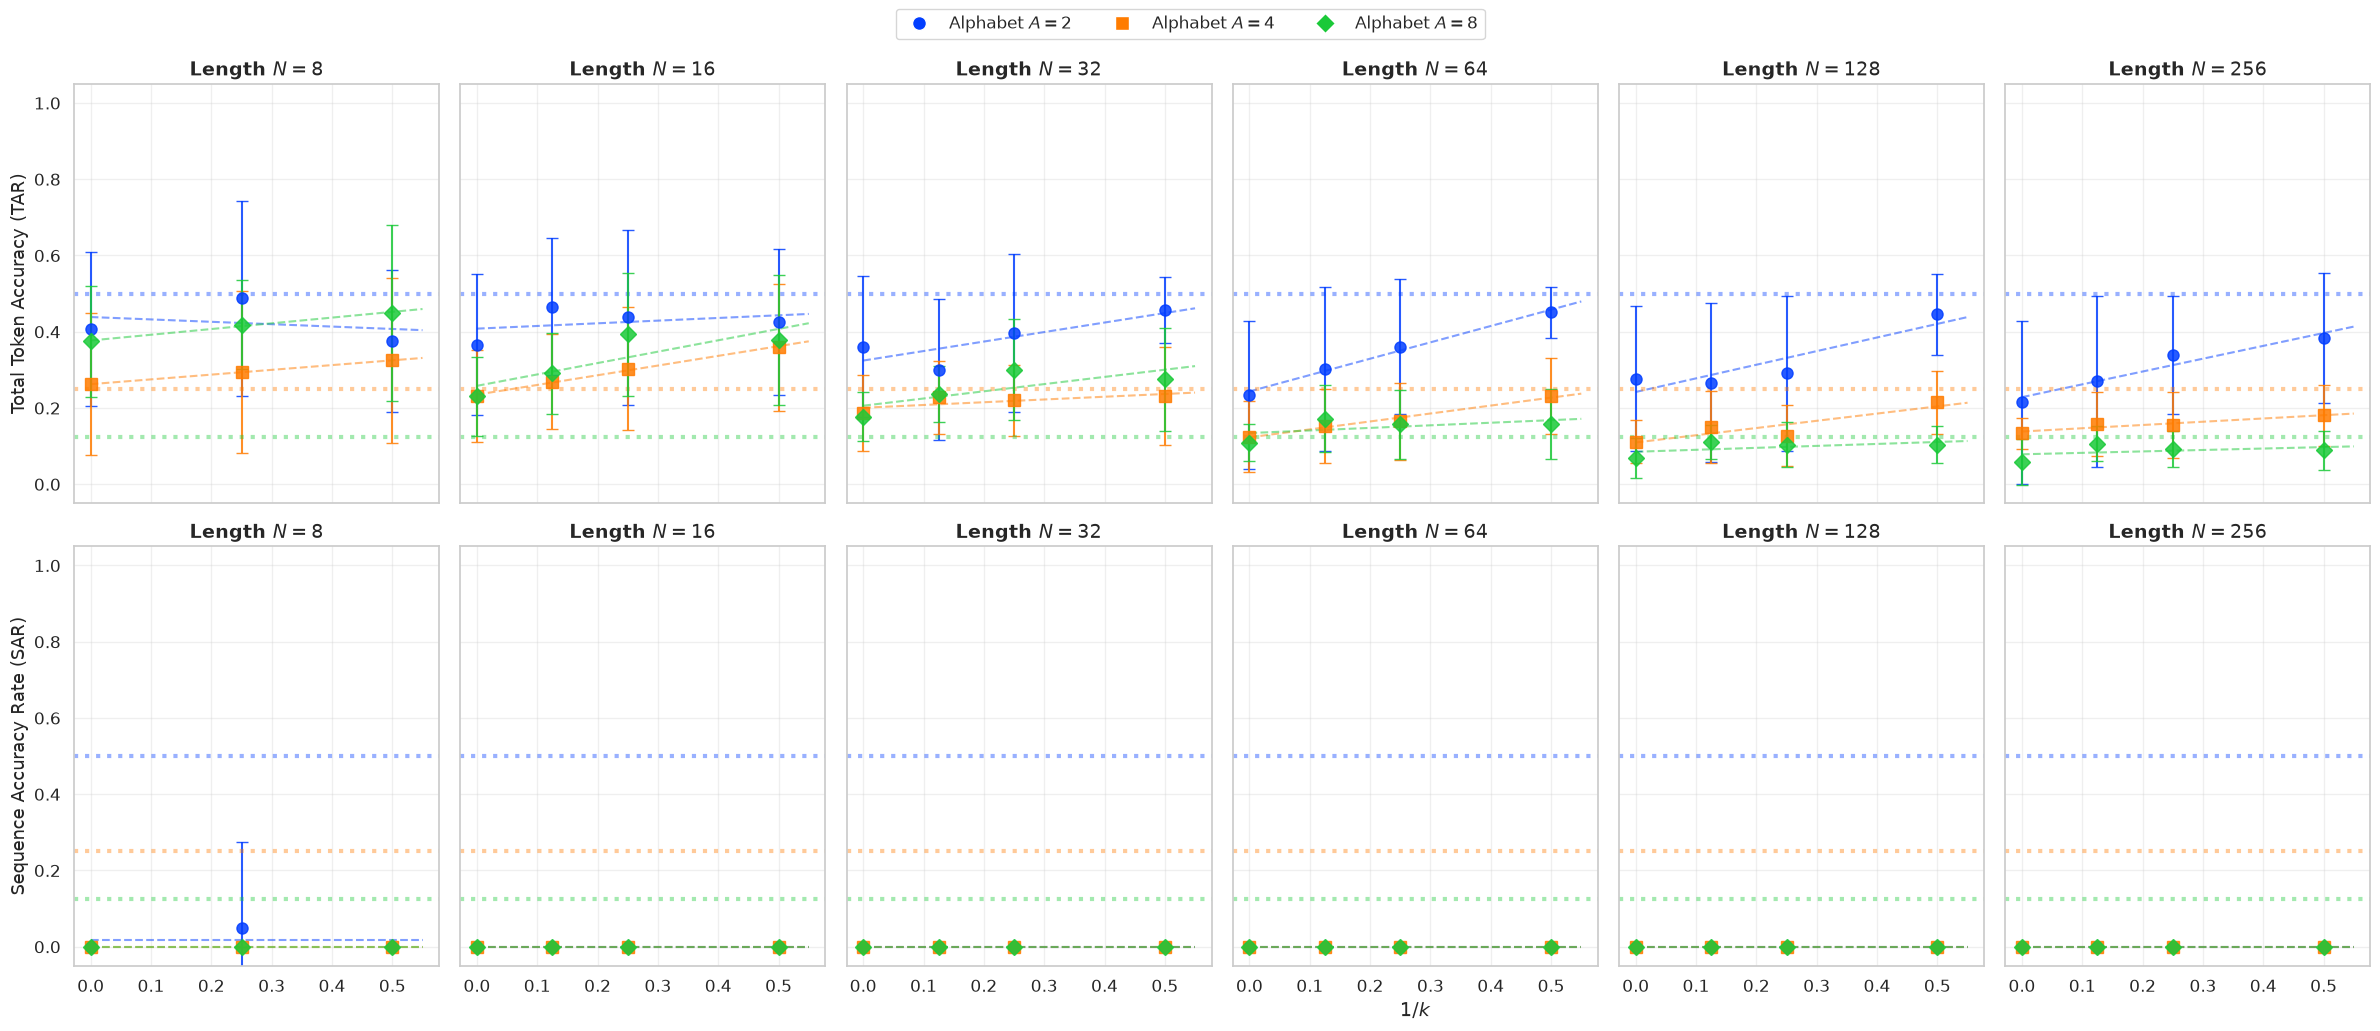


--- SCALING LAW REGRESSION (N >= 8), TAR and SAR ---

TAR:
Seq_Length    8      16     32     64     128    256
Alphabet                                            
2           0.072  0.126  0.649  0.990  0.819  0.935
4           1.000  0.995  0.547  0.977  0.794  0.893
8           0.991  0.696  0.565  0.280  0.345  0.161

SAR:
Seq_Length    8
Alphabet       
2           0.0


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import seaborn as sns
import os

# --- 1. LOAD DATA ---
file_path = os.path.join(RESULTS_DIR, "thermodynamics_grid.csv")
df = pd.read_csv(file_path)

# Robustly handle column names
if 'Accuracy' in df.columns and 'TAR' not in df.columns:
    df['TAR'] = df['Accuracy']
elif 'TAR' not in df.columns:
    raise ValueError("Dataset missing 'TAR' or 'Accuracy' column.")

# --- 2. CALCULATE 1/k (DEFECT DENSITY) WITH BASE CASE AT 0 ---

# Logic: If k=0 (Base), density is 0. If k>0, density is 1/k.
df['Inv_K'] = df['Interval'].apply(lambda k: 0.0 if k == 0 else 1.0/k)

# # --- FILTER: ONLY PLOT N >= 8 ---
df = df[df['Seq_Length'] >= 8]
#target_lengths = [128, 256, 512]
#df = df[df['Seq_Length'].isin(target_lengths)]

# Calculate mean AND std (across the 20 trials per condition) for both TAR and
# SAR -- SAR (whole-sequence exact match) is the paper's headline "accuracy
# cliff" metric, TAR (per-token accuracy) is the softer companion metric.
summary = (
    df.groupby(['Seq_Length', 'Alphabet_Size', 'Inv_K'])[['TAR', 'SAR']]
      .agg(['mean', 'std'])
)
summary.columns = ['_'.join(c) for c in summary.columns]
summary = summary.reset_index().sort_values(['Seq_Length', 'Alphabet_Size', 'Inv_K'])
summary[['TAR_std', 'SAR_std']] = summary[['TAR_std', 'SAR_std']].fillna(0.0)  # single-sample groups

print(df[['Seq_Length', 'Alphabet_Size', 'Interval', 'TAR', 'SAR']])

# --- 3. PLOTTING (TAR on top row, SAR on bottom row) ---
seq_lengths = sorted(summary['Seq_Length'].unique())
alphabet_sizes = sorted(summary['Alphabet_Size'].unique())
num_lengths = len(seq_lengths)

# Dynamic Styling
palette = sns.color_palette("bright", n_colors=len(alphabet_sizes))
colors = {A: col for A, col in zip(alphabet_sizes, palette)}
marker_list = ['o', 's', 'D', '^', 'v', '<', '>']
markers = {A: marker_list[i % len(marker_list)] for i, A in enumerate(alphabet_sizes)}

sns.set_theme(style="whitegrid", font_scale=1.1)

fig, axes = plt.subplots(2, max(num_lengths, 1), figsize=(4 * max(num_lengths, 1), 10),
                          sharex=True, sharey=True, squeeze=False)

regression_results = []

for row, (metric, ylabel) in enumerate([('TAR', 'Total Token Accuracy (TAR)'),
                                         ('SAR', 'Sequence Accuracy Rate (SAR)')]):
    for i, N in enumerate(seq_lengths):
        ax = axes[row][i]
        sub_N = summary[summary['Seq_Length'] == N]

        for A in alphabet_sizes:
            sub_A = sub_N[sub_N['Alphabet_Size'] == A]

            # Need at least 2 points for a line
            if len(sub_A) < 2: continue

            inv_k_vals = sub_A['Inv_K'].values
            metric_vals = sub_A[f'{metric}_mean'].values
            metric_err = sub_A[f'{metric}_std'].values

            # Linear Regression (Including the Base point at x=0)
            slope, intercept, r_value, p_value, std_err = linregress(inv_k_vals, metric_vals)

            regression_results.append({
                'Metric': metric,
                'Seq_Length': N,
                'Alphabet': A,
                'Slope': slope,
                'Intercept (Base Fit)': intercept,
                'R_squared': r_value**2
            })

            # --- PLOT DYNAMIC 1/A REFERENCE LINE (chance baseline) ---
            ax.axhline(1.0/A, color=colors[A], linestyle=':', alpha=0.4, linewidth=3)

            # Plot Data Points with error bars (std across the 20 trials)
            ax.errorbar(inv_k_vals, metric_vals, yerr=metric_err,
                        fmt=markers[A], color=colors[A], markersize=8, alpha=0.85,
                        capsize=4, linestyle='none')

            # Plot Fit Line
            x_fit = np.linspace(0, max(inv_k_vals) * 1.1, 100)
            y_fit = slope * x_fit + intercept
            ax.plot(x_fit, y_fit, linestyle='--', color=colors[A], alpha=0.5, linewidth=1.5)

        ax.set_title(f'Length $N = {N}$', fontsize=14, fontweight='bold')
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True, alpha=0.3)

        if i == 0:
            ax.set_ylabel(ylabel, fontsize=13)
        if row == 1 and i == num_lengths // 2:
            ax.set_xlabel('$1/k$', fontsize=14)

# Legend
handles = [plt.Line2D([0], [0], marker=markers[A], color='w', markerfacecolor=colors[A],
                      markersize=10, label=f'Alphabet $A={A}$') for A in alphabet_sizes]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.04), ncol=len(alphabet_sizes), fontsize=12)

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'scaling_law_N8_plus.png')
plt.savefig(plot_path, bbox_inches='tight', dpi=300)
print(f"Saved plot to {plot_path}")
plt.show()

# --- 4. PRINT RESULTS ---
print("\n--- SCALING LAW REGRESSION (N >= 8), TAR and SAR ---")
results_df = pd.DataFrame(regression_results).round(3)
for metric in ['TAR', 'SAR']:
    print(f"\n{metric}:")
    pivot = results_df[results_df['Metric'] == metric].pivot_table(
        index='Alphabet', columns='Seq_Length', values='R_squared')
    print(pivot)

results_df.to_csv(os.path.join(RESULTS_DIR, "thermodynamics_regression.csv"), index=False)

--- SK MODEL FIT: beta0 (intrinsic error rate), alpha (error accumulation), N* (cliff length) ---
 Alphabet_Size          Method  Interval  Beta0  Alpha  N_star  N_points
             2            Base         0 0.0737 1.5988  6.5588         7
             2 Cellular_Bounds         2 0.5363 1.7434  2.1208         7
             2 Cellular_Bounds         4 0.0686 1.2744 12.0511         6
             2 Cellular_Bounds         8 0.0512 1.2046 16.9682         5
             4            Base         0 0.3825 1.2510  5.2910         7
             4 Cellular_Bounds         2 0.2364 1.3453  5.8618         7
             4 Cellular_Bounds         4 0.1130 1.4520  6.8458         6
             4 Cellular_Bounds         8 0.0512 1.2046 16.9682         5
             8            Base         0 0.2364 1.3453  5.8618         7
             8 Cellular_Bounds         2 0.0737 1.5988  6.5588         7
             8 Cellular_Bounds         4 0.1130 1.4520  6.8458         6
             8 Cellular_Bo


Saved plot to results/Mistral-7B-Instruct-v0.3/thermodynamics_sk_alpha_vs_density.png


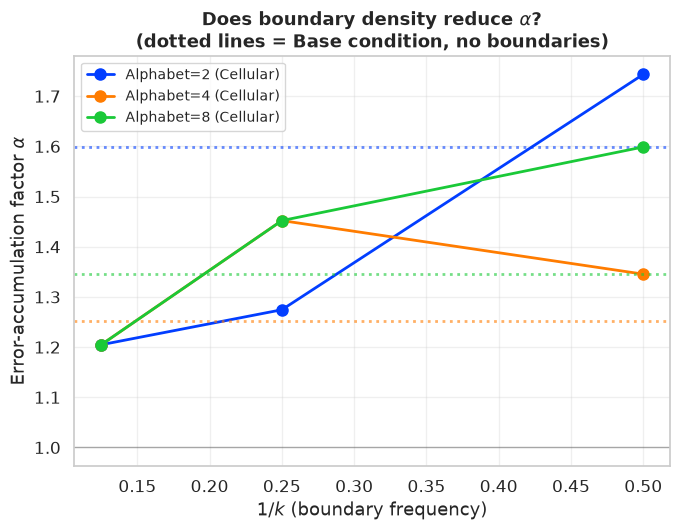

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import os

# ============================================================
# SK SPIN-GLASS FIT
# ============================================================
# Hou, Zhou, Hu, Chen, You, Qi -- "How Focused Are LLMs? A Quantitative
# Study via Repetitive Deterministic Prediction Tasks" (arXiv:2511.00763).
#
# Eq. 14:  SAR(N) = exp(-beta0 * N * alpha**(N-1))
#   beta0 = intrinsic per-token error rate
#   alpha = error-accumulation factor (alpha > 1 produces the cliff;
#           alpha == 1 would just be ordinary per-token exponential decay)
# Eq. 15:  cliff length  N* ~= 1 + log(1/beta0) / log(alpha)
#
# Fit separately per (Alphabet, Method, Interval) so alpha_base and
# alpha_cellular are directly comparable -- this is the notebook's actual
# test of whether "|" boundaries slow the accuracy cliff, stated in the
# same language as the paper instead of just an empirical linear slope.

def sk_model(N, beta0, alpha):
    N = np.asarray(N, dtype=np.float64)
    return np.exp(-beta0 * N * np.power(alpha, N - 1))

def fit_sk(N_vals, sar_vals):
    N_vals = np.asarray(N_vals, dtype=np.float64)
    sar_vals = np.asarray(sar_vals, dtype=np.float64)
    try:
        popt, _ = curve_fit(
            sk_model, N_vals, sar_vals,
            p0=[0.05, 1.2], bounds=([1e-6, 1.0 + 1e-6], [1.0, 5.0]), maxfev=20000,
        )
        beta0, alpha = popt
        n_star = 1 + np.log(1.0 / beta0) / np.log(alpha) if alpha > 1 else np.inf
        return beta0, alpha, n_star
    except RuntimeError:
        return np.nan, np.nan, np.nan

df_sk = pd.read_csv(os.path.join(RESULTS_DIR, "thermodynamics_grid.csv"))

sk_results = []
for grp in sorted(df_sk['Alphabet_Size'].unique()):
    sub_G = df_sk[df_sk['Alphabet_Size'] == grp]
    for method, sub_M in sub_G.groupby('Method'):
        for interval, sub_I in sub_M.groupby('Interval'):
            per_N = sub_I.groupby('Seq_Length')['SAR'].mean().reset_index()
            if len(per_N) < 3:  # need enough distinct N to fit 2 free params
                continue
            beta0, alpha, n_star = fit_sk(per_N['Seq_Length'], per_N['SAR'])
            sk_results.append({
                'Alphabet_Size': grp, 'Method': method, 'Interval': interval,
                'Beta0': beta0, 'Alpha': alpha, 'N_star': n_star,
                'N_points': len(per_N),
            })

sk_df = pd.DataFrame(sk_results)
print("--- SK MODEL FIT: beta0 (intrinsic error rate), alpha (error accumulation), N* (cliff length) ---")
print(sk_df.round(4).to_string(index=False))
sk_df.to_csv(os.path.join(RESULTS_DIR, "thermodynamics_sk_fit.csv"), index=False)

# --- Headline comparison: does alpha drop from Base to Cellular? ---
base_alpha = sk_df[sk_df['Method'] == 'Base'].set_index('Alphabet_Size')['Alpha']
cell_alpha_mean = (
    sk_df[sk_df['Method'] == 'Cellular_Bounds']
    .groupby('Alphabet_Size')['Alpha']
    .mean()
)
print("\n--- ALPHA: Base vs mean(Cellular) per Alphabet ---")
for grp in sorted(set(base_alpha.index) & set(cell_alpha_mean.index)):
    b, c = base_alpha[grp], cell_alpha_mean[grp]
    pct = 100 * (b - c) / b if b else float('nan')
    print(f"Alphabet={grp}: alpha_base={b:.4f}  alpha_cellular_mean={c:.4f}  "
          f"({'-' if pct >= 0 else '+'}{abs(pct):.1f}% {'reduction' if pct >= 0 else 'increase'})")

# --- Plot: alpha vs boundary density (Inv_K), Base shown as a reference line ---
sk_df['Inv_K'] = sk_df['Interval'].apply(lambda k: 0.0 if k == 0 else 1.0 / k)
groups = sorted(sk_df['Alphabet_Size'].unique())
palette = sns.color_palette("bright", n_colors=len(groups))
colors = {g: c for g, c in zip(groups, palette)}

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, ax = plt.subplots(figsize=(7, 5.5))
for grp in groups:
    sub = sk_df[(sk_df['Alphabet_Size'] == grp) & (sk_df['Method'] == 'Cellular_Bounds')].sort_values('Inv_K')
    if len(sub):
        ax.plot(sub['Inv_K'], sub['Alpha'], marker='o', markersize=8, linewidth=2,
                color=colors[grp], label=f'Alphabet={grp} (Cellular)')
    base_row = sk_df[(sk_df['Alphabet_Size'] == grp) & (sk_df['Method'] == 'Base')]
    if len(base_row):
        ax.axhline(base_row['Alpha'].iloc[0], color=colors[grp], linestyle=':', alpha=0.6, linewidth=2)

ax.axhline(1.0, color='black', linestyle='-', alpha=0.3, linewidth=1)
ax.set_xlabel('$1/k$ (boundary frequency)', fontsize=13)
ax.set_ylabel(r'Error-accumulation factor $\alpha$', fontsize=13)
ax.set_title('Does boundary density reduce $\\alpha$?\n(dotted lines = Base condition, no boundaries)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'thermodynamics_sk_alpha_vs_density.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\nSaved plot to {plot_path}")
plt.show()

# running sum modulo M over digits

In [8]:
# ============================================================
# RUNNING SUM MODULO M -- TASK ENGINE + GRID SEARCH
# ============================================================
# Complements the cyclic-shift task above: that task is purely
# position-local (each output digit depends only on the matching
# input digit), while this task requires tracking a running/
# cumulative state across the whole sequence. It is a better test
# of whether the "|" cell boundaries help or hurt long-range state
# tracking, since the true running sum must persist across
# boundaries rather than reset at each one.
#
# Reuses the `model` / `tokenizer` already loaded above -- no reload.

import pandas as pd
import numpy as np
import random
import itertools
import torch
import os
from tqdm import tqdm

# --- 1. THE PARAMETER SPACE ---
MODULI = [2, 4, 8]
SEQUENCE_LENGTHS = [4, 8, 16, 32, 64, 128, 256]
# Runtime note (measured on an A100): each generate() call costs roughly
# max_new_tokens / 34 seconds. At N=256 (~400 new tokens) that's ~12s/call;
# the full grid at this length list adds ~1.5h beyond the N<=32 baseline.
# Trim this list or TRIALS_T below for a faster pass.
PERIODIC_INTERVALS = [0, 2, 4, 8]   # 0 = Base
API_TEMPERATURES = [0.0]
TRIALS_T = 20

GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

# --- 2. TASK ENGINE ---
class ModSumTaskEngine:
    def __init__(self, modulus):
        self.modulus = modulus
        self.digits = [str(i) for i in range(modulus)]

    def generate_raw_input(self, length, rng=None):
        if rng is None:
            rng = random
        return rng.choices(self.digits, k=length)

    def _running_sum_digits(self, raw_input):
        running = 0
        out = []
        for d in raw_input:
            running = (running + int(d)) % self.modulus
            out.append(str(running))
        return out

    def build_base_from_raw(self, raw_input):
        input_str = "".join(raw_input)
        output_str = "".join(self._running_sum_digits(raw_input))

        prompt = f"""You are a deterministic sequence transformer.
Task: Running sum modulo {self.modulus}.
Digits: {', '.join(self.digits)}
Rule: At each position, output the cumulative sum of all digits from the start of the sequence up to and including that position, taken modulo {self.modulus}.
Constraint: Output ONLY the transformed string, one output digit per input digit.
No spaces, no explanations.

Input: {input_str}
Output: """
        return input_str, output_str, prompt

    def build_cellular_from_raw(self, raw_input, interval):
        running_digits = self._running_sum_digits(raw_input)

        input_w_bounds = ""
        output_w_bounds = ""
        for i, (d, out_d) in enumerate(zip(raw_input, running_digits)):
            input_w_bounds += d
            output_w_bounds += out_d
            if interval > 0 and (i + 1) % interval == 0 and i != len(raw_input) - 1:
                input_w_bounds += "|"
                output_w_bounds += "|"

        prompt = f"""You are a deterministic sequence transformer.
Task: Running sum modulo {self.modulus}.
Digits: {', '.join(self.digits)}
Rule: At each position, output the cumulative sum of ALL digits seen so far since the very start of the sequence, taken modulo {self.modulus}.
Constraint: The input contains vertical bars (|). These are structural boundaries only -- DO NOT reset the running sum at a boundary, and DO NOT shift the boundary itself. Copy each boundary exactly to the output.
No spaces, no explanations.

Input: {input_w_bounds}
Output: """
        return input_w_bounds, output_w_bounds, prompt

engines = {M: ModSumTaskEngine(M) for M in MODULI}

# --- 3. PREGENERATE SHARED RAW SEQUENCES ---
shared_sequences = {}
for M in MODULI:
    engine = engines[M]
    for N in SEQUENCE_LENGTHS:
        for t in range(TRIALS_T):
            local_seed = 20_000 * M + 100 * N + t
            rng = random.Random(local_seed)
            shared_sequences[(M, N, t)] = engine.generate_raw_input(N, rng=rng)

print(f"Pregenerated {len(shared_sequences)} shared raw sequences.")

# --- 4. WORKER FUNCTION FOR A SINGLE TRIAL ---
def run_single_modsum_trial(task_params):
    T_api, M, N, k, t = task_params
    engine = engines[M]
    method = "Base" if k == 0 else "Cellular_Bounds"

    raw_input = shared_sequences[(M, N, t)]

    if method == "Base":
        inp, truth, prompt = engine.build_base_from_raw(raw_input)
    else:
        inp, truth, prompt = engine.build_cellular_from_raw(raw_input, interval=k)

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    max_tokens_needed = int(N * 1.5) + 20

    do_sample = T_api > 0.0
    temp_val = T_api if do_sample else None

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_tokens_needed,
            temperature=temp_val,
            do_sample=do_sample,
            pad_token_id=tokenizer.eos_token_id
        )

    full_response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    pred = full_response[len(prompt):].strip()
    pred = pred.split("Explanation")[0].split("\n")[0].strip()

    if method == "Cellular_Bounds":
        clean_pred = pred.replace("|", "").replace(" ", "").replace("\n", "")
        clean_truth = truth.replace("|", "")
    else:
        clean_pred = pred.replace(" ", "").replace("\n", "")
        clean_truth = truth

    clean_pred = clean_pred[:len(clean_truth)]

    binary_series = []
    for i in range(len(clean_truth)):
        if i < len(clean_pred) and clean_pred[i] == clean_truth[i]:
            binary_series.append(1)
        else:
            binary_series.append(0)

    tar = sum(binary_series) / len(clean_truth) if len(clean_truth) > 0 else 0.0
    sar = 1.0 if (
        len(binary_series) == len(clean_truth)
        and sum(binary_series) == len(binary_series)
    ) else 0.0
    first_error = binary_series.index(0) if 0 in binary_series else len(binary_series)

    return {
        "API_Temp": T_api,
        "Modulus": M,
        "Method": method,
        "Interval": k,
        "Seq_Length": N,
        "Trial": t,
        "Shared_Sequence": "".join(raw_input),
        "TAR": tar,
        "SAR": sar,
        "First_Error_Pos": first_error,
        "Input_Given": inp,
        "Ground_Truth": clean_truth,
        "LLM_Output": clean_pred
    }

# --- 5. MAIN EXPERIMENT SETUP ---
modsum_tasks = list(itertools.product(
    API_TEMPERATURES,
    MODULI,
    SEQUENCE_LENGTHS,
    PERIODIC_INTERVALS,
    range(TRIALS_T)
))

filtered_modsum_tasks = [task for task in modsum_tasks if task[3] == 0 or task[3] < task[2]]

total_calls = len(filtered_modsum_tasks)
print(f"\nStarting Running-Sum-Mod-M Grid Search with 7B Model: {total_calls} total evaluations.")

all_modsum_results = []
for task in tqdm(filtered_modsum_tasks, total=total_calls, desc="Generating"):
    try:
        result = run_single_modsum_trial(task)
        all_modsum_results.append(result)
    except Exception as exc:
        print(f"Task failed: {task} | Error: {exc}")

# --- 6. SAVE & SUMMARIZE ---
df = pd.DataFrame(all_modsum_results)

csv_filename = os.path.join(RESULTS_DIR, "running_modsum_grid.csv")
df.to_csv(csv_filename, index=False)
print(f"\nExperiment complete. Saved to '{csv_filename}'")

summary = (
    df.groupby(["Modulus", "Seq_Length", "Method"])[["TAR", "SAR"]]
      .mean()
      .reset_index()
)
print("\n--- AVERAGE ACCURACY BY MODULUS & LENGTH ---")
print(summary.to_string(index=False))

Pregenerated 420 shared raw sequences.

Starting Running-Sum-Mod-M Grid Search with 7B Model: 1500 total evaluations.


Generating:   0%|          | 0/1500 [00:00<?, ?it/s]

Generating:   0%|          | 1/1500 [00:00<19:54,  1.25it/s]

Generating:   0%|          | 2/1500 [00:01<19:51,  1.26it/s]

Generating:   0%|          | 3/1500 [00:02<19:50,  1.26it/s]

...

Generating: 100%|█████████▉| 1498/1500 [1:41:13<00:24, 12.35s/it]

Generating: 100%|█████████▉| 1499/1500 [1:41:25<00:12, 12.28s/it]

Generating: 100%|██████████| 1500/1500 [1:41:38<00:00, 12.26s/it]

Generating: 100%|██████████| 1500/1500 [1:41:38<00:00,  4.07s/it]


Experiment complete. Saved to 'results/Mistral-7B-Instruct-v0.3/running_modsum_grid.csv'

--- AVERAGE ACCURACY BY MODULUS & LENGTH ---
 Modulus  Seq_Length          Method      TAR  SAR
       2           4            Base 0.675000 0.10
       2           4 Cellular_Bounds 0.600000 0.35
       2           8            Base 0.568750 0.05
       2           8 Cellular_Bounds 0.378125 0.00
       2          16            Base 0.500000 0.00
       2          16 Cellular_Bounds 0.282292 0.00
       2          32            Base 0.496875 0.00
       2          32 Cellular_Bounds 0.255729 0.00
       2          64            Base 0.489844 0.00
       2          64 Cellular_Bounds 0.202604 0.00
       2         128            Base 0.482031 0.00
       2         128 Cellular_Bounds 0.234766 0.00
       2         256            Base 0.468555 0.00
       2         256 Cellular_Bounds 0.337435 0.00
       4           4            Base 0.350000 0.05
       4           4 Cellular_Bounds 0.350000 0.

    Seq_Length  Modulus  Interval    TAR  SAR
40           8        2         0  0.500  0.0
41           8        2         0  0.375  0.0
42           8        2         0  0.250  0.0
43           8        2         0  1.000  1.0
44           8        2         0  0.750  0.0
45           8        2         0  0.750  0.0
46           8        2         0  0.625  0.0
47           8        2         0  0.250  0.0
48           8        2         0  0.250  0.0
49           8        2         0  0.625  0.0
50           8        2         0  0.625  0.0
51           8        2         0  0.625  0.0
52           8        2         0  0.375  0.0
53           8        2         0  0.875  0.0
54           8        2         0  0.625  0.0
55           8        2         0  0.250  0.0
56           8        2         0  0.750  0.0
57           8        2         0  0.875  0.0
58           8        2         0  0.750  0.0
59           8        2         0  0.250  0.0


Saved plot to results/Mistral-7B-Instruct-v0.3/running_modsum_scaling_law_N8_plus.png


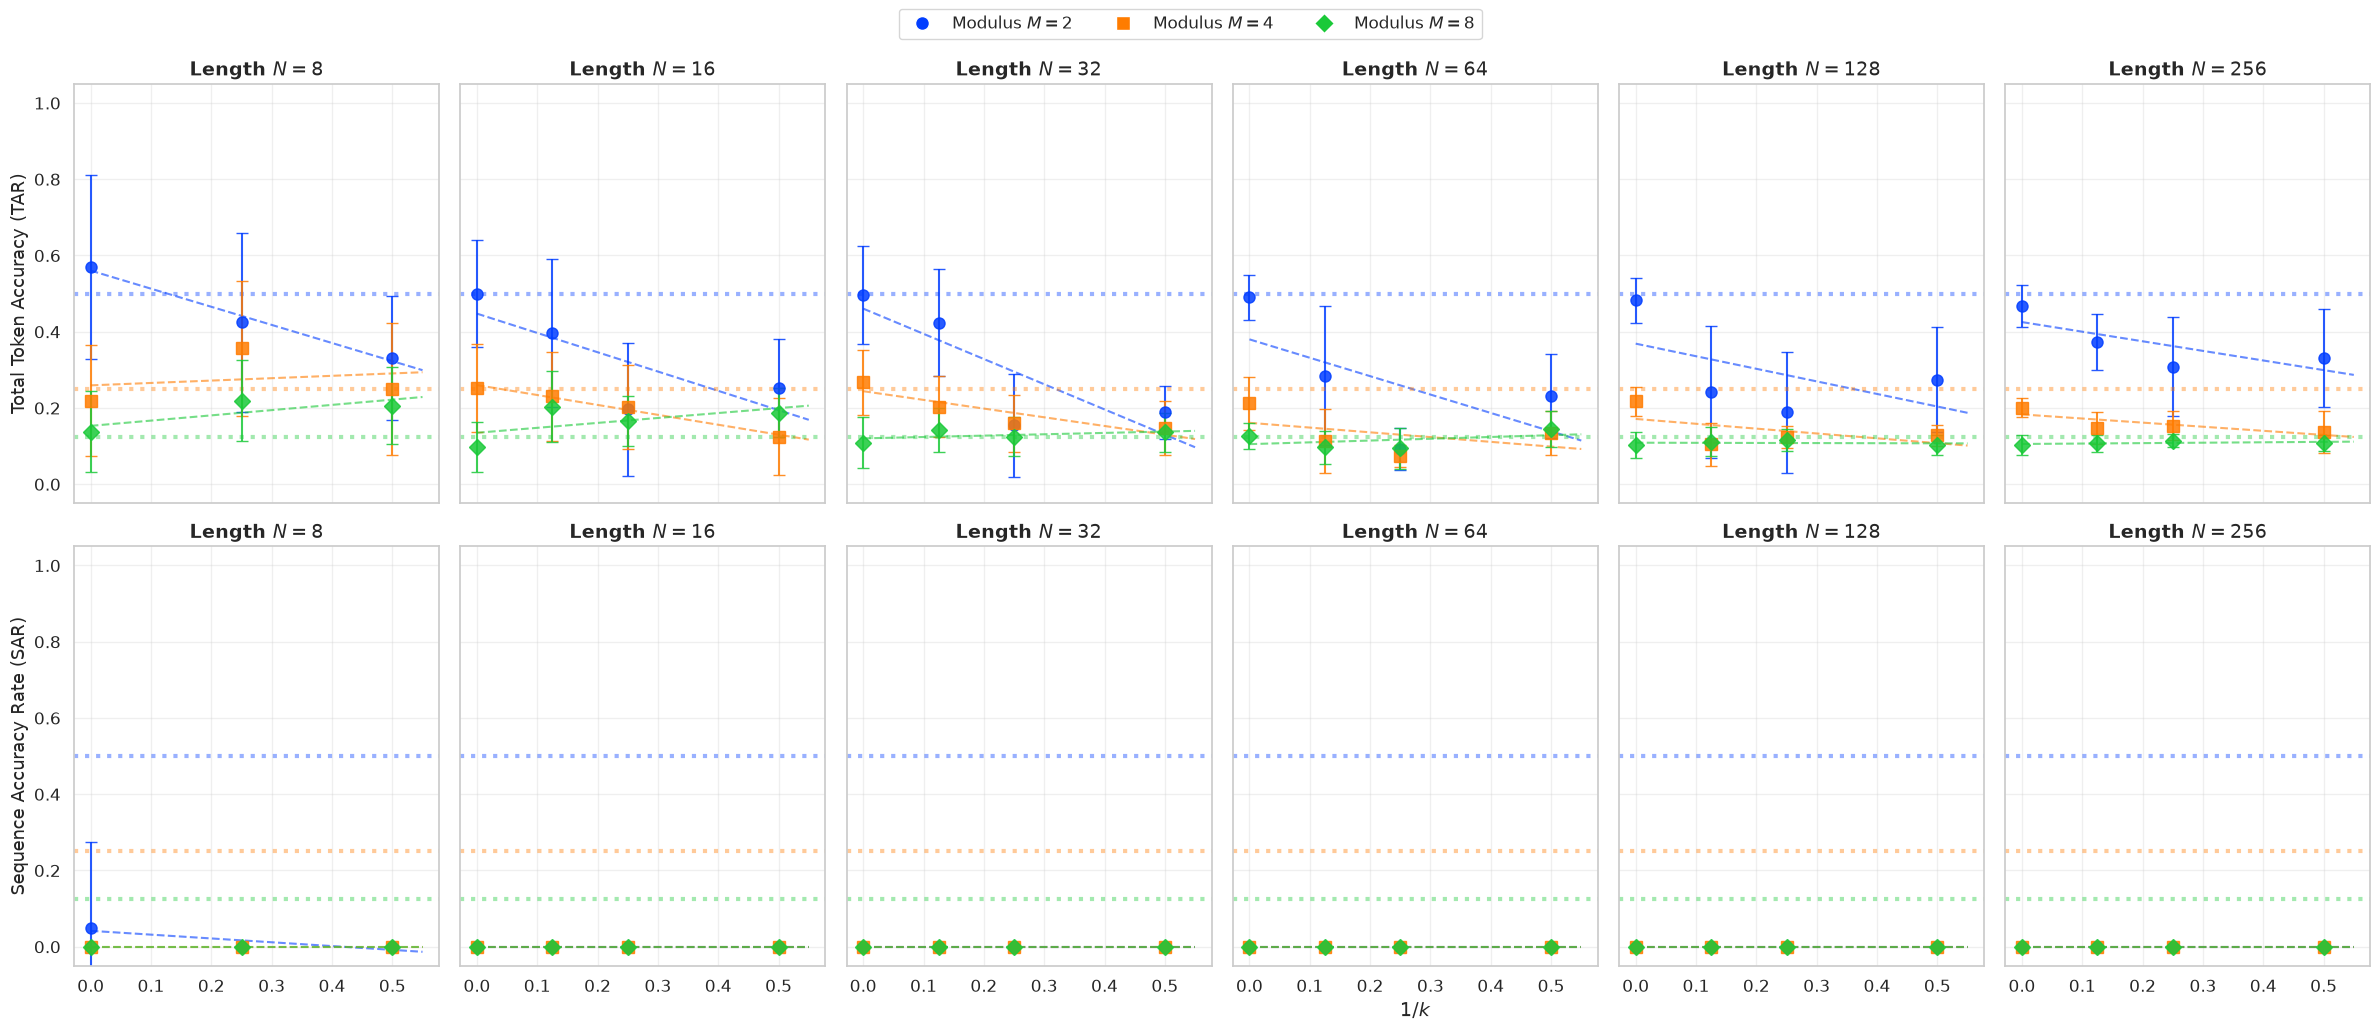


--- SCALING LAW REGRESSION (N >= 8), TAR and SAR ---

TAR:
Seq_Length    8      16     32     64     128    256
Modulus                                             
2           0.985  0.617  0.692  0.389  0.300  0.581
4           0.047  0.984  0.804  0.210  0.288  0.640
8           0.617  0.347  0.281  0.172  0.011  0.228

SAR:
Seq_Length     8
Modulus         
2           0.75

--- FULL REGRESSION RESULTS ---
Metric  Seq_Length  Modulus  Slope  Intercept  R_squared  P_value
   TAR           8        2 -0.475      0.560      0.985    0.077
   TAR           8        4  0.062      0.259      0.047    0.861
   TAR           8        8  0.137      0.153      0.617    0.425
   TAR          16        2 -0.506      0.448      0.617    0.214
   TAR          16        4 -0.260      0.260      0.984    0.008
   TAR          16        8  0.129      0.135      0.347    0.411
   TAR          32        2 -0.661      0.461      0.692    0.168
   TAR          32        4 -0.228      0.244      0.804 

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import seaborn as sns
import os

# --- 1. LOAD DATA ---
file_path = os.path.join(RESULTS_DIR, "running_modsum_grid.csv")
df = pd.read_csv(file_path)

# Robustly handle column names
if 'Accuracy' in df.columns and 'TAR' not in df.columns:
    df['TAR'] = df['Accuracy']
elif 'TAR' not in df.columns:
    raise ValueError("Dataset missing 'TAR' or 'Accuracy' column.")

if 'Modulus' not in df.columns:
    raise ValueError("Dataset missing 'Modulus' column.")

# --- 2. CALCULATE 1/k ---
# Base case (k=0) gets Inv_K = 0
df['Inv_K'] = df['Interval'].apply(lambda k: 0.0 if k == 0 else 1.0 / k)

# Optional filter
df = df[df['Seq_Length'] >= 8]

# Mean AND std (across the 20 trials per condition) for both TAR and SAR --
# SAR (whole-sequence exact match) is the paper's headline "accuracy cliff"
# metric, TAR (per-token accuracy) is the softer companion metric.
summary = (
    df.groupby(['Seq_Length', 'Modulus', 'Inv_K'])[['TAR', 'SAR']]
      .agg(['mean', 'std'])
)
summary.columns = ['_'.join(c) for c in summary.columns]
summary = summary.reset_index().sort_values(['Seq_Length', 'Modulus', 'Inv_K'])
summary[['TAR_std', 'SAR_std']] = summary[['TAR_std', 'SAR_std']].fillna(0.0)

print(df[['Seq_Length', 'Modulus', 'Interval', 'TAR', 'SAR']].head(20))

# --- 3. PLOTTING SETUP (TAR on top row, SAR on bottom row) ---
seq_lengths = sorted(summary['Seq_Length'].unique())
moduli = sorted(summary['Modulus'].unique())
num_lengths = len(seq_lengths)

sns.set_theme(style="whitegrid", font_scale=1.1)

palette = sns.color_palette("bright", n_colors=len(moduli))
colors = {M: col for M, col in zip(moduli, palette)}
marker_list = ['o', 's', 'D', '^', 'v', '<', '>']
markers = {M: marker_list[i % len(marker_list)] for i, M in enumerate(moduli)}

fig, axes = plt.subplots(2, max(num_lengths, 1), figsize=(4 * max(num_lengths, 1), 10),
                          sharex=True, sharey=True, squeeze=False)

regression_results = []

# --- 4. PLOT EACH SEQUENCE LENGTH, EACH METRIC ---
for row, (metric, ylabel) in enumerate([('TAR', 'Total Token Accuracy (TAR)'),
                                         ('SAR', 'Sequence Accuracy Rate (SAR)')]):
    for i, N in enumerate(seq_lengths):
        ax = axes[row][i]
        sub_N = summary[summary['Seq_Length'] == N]

        for M in moduli:
            sub_M = sub_N[sub_N['Modulus'] == M]

            if len(sub_M) < 2:
                continue

            inv_k_vals = sub_M['Inv_K'].values
            metric_vals = sub_M[f'{metric}_mean'].values
            metric_err = sub_M[f'{metric}_std'].values

            slope, intercept, r_value, p_value, std_err = linregress(inv_k_vals, metric_vals)

            regression_results.append({
                'Metric': metric,
                'Seq_Length': N,
                'Modulus': M,
                'Slope': slope,
                'Intercept': intercept,
                'R_squared': r_value ** 2,
                'P_value': p_value
            })

            # Chance baseline: 1/M
            ax.axhline(1.0 / M, color=colors[M], linestyle=':', alpha=0.4, linewidth=3)

            # Points with error bars (std across the 20 trials)
            ax.errorbar(
                inv_k_vals, metric_vals, yerr=metric_err,
                fmt=markers[M], color=colors[M], markersize=8, alpha=0.85,
                capsize=4, linestyle='none'
            )

            # Fit line
            x_fit = np.linspace(0, max(inv_k_vals) * 1.1, 100)
            y_fit = slope * x_fit + intercept
            ax.plot(x_fit, y_fit, linestyle='--', color=colors[M], alpha=0.6, linewidth=1.5)

        ax.set_title(f'Length $N = {N}$', fontsize=14, fontweight='bold')
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True, alpha=0.3)

        if i == 0:
            ax.set_ylabel(ylabel, fontsize=13)
        if row == 1 and i == num_lengths // 2:
            ax.set_xlabel('$1/k$', fontsize=14)

# --- 5. LEGEND ---
handles = [
    plt.Line2D([0], [0], marker=markers[M], color='w', markerfacecolor=colors[M],
               markersize=10, label=f'Modulus $M={M}$')
    for M in moduli
]

fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.04), ncol=len(moduli), fontsize=12)

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'running_modsum_scaling_law_N8_plus.png')
plt.savefig(plot_path, bbox_inches='tight', dpi=300)
print(f"Saved plot to {plot_path}")
plt.show()

# --- 6. PRINT REGRESSION TABLE ---
print("\n--- SCALING LAW REGRESSION (N >= 8), TAR and SAR ---")
results_df = pd.DataFrame(regression_results).round(3)
for metric in ['TAR', 'SAR']:
    print(f"\n{metric}:")
    pivot = results_df[results_df['Metric'] == metric].pivot_table(
        index='Modulus', columns='Seq_Length', values='R_squared')
    print(pivot)

print("\n--- FULL REGRESSION RESULTS ---")
print(results_df.to_string(index=False))

results_df.to_csv(os.path.join(RESULTS_DIR, "modsum_regression.csv"), index=False)

--- SK MODEL FIT: beta0 (intrinsic error rate), alpha (error accumulation), N* (cliff length) ---
 Modulus          Method  Interval  Beta0  Alpha      N_star  N_points
       2            Base         0 0.5557 1.0000 587461.2500         7
       2 Cellular_Bounds         2 0.0580 1.6541      6.6581         7
       2 Cellular_Bounds         4 0.1130 1.4520      6.8458         6
       2 Cellular_Bounds         8 0.0512 1.2046     16.9682         5
       4            Base         0 0.3825 1.2510      5.2910         7
       4 Cellular_Bounds         2 0.5363 1.7434      2.1208         7
       4 Cellular_Bounds         4 0.1130 1.4520      6.8458         6
       4 Cellular_Bounds         8 0.0512 1.2046     16.9682         5
       8            Base         0 0.5363 1.7434      2.1208         7
       8 Cellular_Bounds         2 0.5363 1.7434      2.1208         7
       8 Cellular_Bounds         4 0.1130 1.4520      6.8458         6
       8 Cellular_Bounds         8 0.0512 1.2046  


Saved plot to results/Mistral-7B-Instruct-v0.3/modsum_sk_alpha_vs_density.png


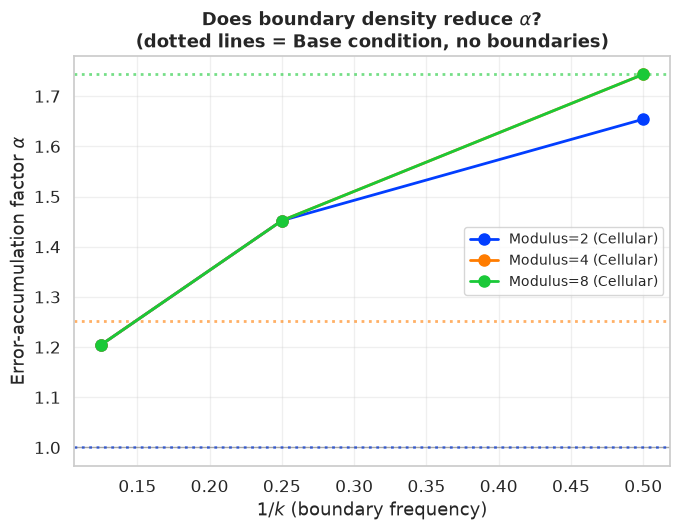

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import os

# ============================================================
# SK SPIN-GLASS FIT
# ============================================================
# Hou, Zhou, Hu, Chen, You, Qi -- "How Focused Are LLMs? A Quantitative
# Study via Repetitive Deterministic Prediction Tasks" (arXiv:2511.00763).
#
# Eq. 14:  SAR(N) = exp(-beta0 * N * alpha**(N-1))
#   beta0 = intrinsic per-token error rate
#   alpha = error-accumulation factor (alpha > 1 produces the cliff;
#           alpha == 1 would just be ordinary per-token exponential decay)
# Eq. 15:  cliff length  N* ~= 1 + log(1/beta0) / log(alpha)
#
# Fit separately per (Modulus, Method, Interval) so alpha_base and
# alpha_cellular are directly comparable -- this is the notebook's actual
# test of whether "|" boundaries slow the accuracy cliff, stated in the
# same language as the paper instead of just an empirical linear slope.

def sk_model(N, beta0, alpha):
    N = np.asarray(N, dtype=np.float64)
    return np.exp(-beta0 * N * np.power(alpha, N - 1))

def fit_sk(N_vals, sar_vals):
    N_vals = np.asarray(N_vals, dtype=np.float64)
    sar_vals = np.asarray(sar_vals, dtype=np.float64)
    try:
        popt, _ = curve_fit(
            sk_model, N_vals, sar_vals,
            p0=[0.05, 1.2], bounds=([1e-6, 1.0 + 1e-6], [1.0, 5.0]), maxfev=20000,
        )
        beta0, alpha = popt
        n_star = 1 + np.log(1.0 / beta0) / np.log(alpha) if alpha > 1 else np.inf
        return beta0, alpha, n_star
    except RuntimeError:
        return np.nan, np.nan, np.nan

df_sk = pd.read_csv(os.path.join(RESULTS_DIR, "running_modsum_grid.csv"))

sk_results = []
for grp in sorted(df_sk['Modulus'].unique()):
    sub_G = df_sk[df_sk['Modulus'] == grp]
    for method, sub_M in sub_G.groupby('Method'):
        for interval, sub_I in sub_M.groupby('Interval'):
            per_N = sub_I.groupby('Seq_Length')['SAR'].mean().reset_index()
            if len(per_N) < 3:  # need enough distinct N to fit 2 free params
                continue
            beta0, alpha, n_star = fit_sk(per_N['Seq_Length'], per_N['SAR'])
            sk_results.append({
                'Modulus': grp, 'Method': method, 'Interval': interval,
                'Beta0': beta0, 'Alpha': alpha, 'N_star': n_star,
                'N_points': len(per_N),
            })

sk_df = pd.DataFrame(sk_results)
print("--- SK MODEL FIT: beta0 (intrinsic error rate), alpha (error accumulation), N* (cliff length) ---")
print(sk_df.round(4).to_string(index=False))
sk_df.to_csv(os.path.join(RESULTS_DIR, "modsum_sk_fit.csv"), index=False)

# --- Headline comparison: does alpha drop from Base to Cellular? ---
base_alpha = sk_df[sk_df['Method'] == 'Base'].set_index('Modulus')['Alpha']
cell_alpha_mean = (
    sk_df[sk_df['Method'] == 'Cellular_Bounds']
    .groupby('Modulus')['Alpha']
    .mean()
)
print("\n--- ALPHA: Base vs mean(Cellular) per Modulus ---")
for grp in sorted(set(base_alpha.index) & set(cell_alpha_mean.index)):
    b, c = base_alpha[grp], cell_alpha_mean[grp]
    pct = 100 * (b - c) / b if b else float('nan')
    print(f"Modulus={grp}: alpha_base={b:.4f}  alpha_cellular_mean={c:.4f}  "
          f"({'-' if pct >= 0 else '+'}{abs(pct):.1f}% {'reduction' if pct >= 0 else 'increase'})")

# --- Plot: alpha vs boundary density (Inv_K), Base shown as a reference line ---
sk_df['Inv_K'] = sk_df['Interval'].apply(lambda k: 0.0 if k == 0 else 1.0 / k)
groups = sorted(sk_df['Modulus'].unique())
palette = sns.color_palette("bright", n_colors=len(groups))
colors = {g: c for g, c in zip(groups, palette)}

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, ax = plt.subplots(figsize=(7, 5.5))
for grp in groups:
    sub = sk_df[(sk_df['Modulus'] == grp) & (sk_df['Method'] == 'Cellular_Bounds')].sort_values('Inv_K')
    if len(sub):
        ax.plot(sub['Inv_K'], sub['Alpha'], marker='o', markersize=8, linewidth=2,
                color=colors[grp], label=f'Modulus={grp} (Cellular)')
    base_row = sk_df[(sk_df['Modulus'] == grp) & (sk_df['Method'] == 'Base')]
    if len(base_row):
        ax.axhline(base_row['Alpha'].iloc[0], color=colors[grp], linestyle=':', alpha=0.6, linewidth=2)

ax.axhline(1.0, color='black', linestyle='-', alpha=0.3, linewidth=1)
ax.set_xlabel('$1/k$ (boundary frequency)', fontsize=13)
ax.set_ylabel(r'Error-accumulation factor $\alpha$', fontsize=13)
ax.set_title('Does boundary density reduce $\\alpha$?\n(dotted lines = Base condition, no boundaries)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'modsum_sk_alpha_vs_density.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\nSaved plot to {plot_path}")
plt.show()

# Cyclic-Shift vs Running-Sum-Mod-M Comparison

--- SAR ~ 1/k SLOPE BY TASK, GROUP, SEQ_LENGTH ---
                          Task  Group  Seq_Length  Slope  R_squared
          Cyclic Shift (local)      2           8    0.0       0.00
          Cyclic Shift (local)      4           8    0.0        NaN
          Cyclic Shift (local)      8           8    0.0        NaN
          Cyclic Shift (local)      2          16    0.0        NaN
          Cyclic Shift (local)      4          16    0.0        NaN
          Cyclic Shift (local)      8          16    0.0        NaN
          Cyclic Shift (local)      2          32    0.0        NaN
          Cyclic Shift (local)      4          32    0.0        NaN
          Cyclic Shift (local)      8          32    0.0        NaN
          Cyclic Shift (local)      2          64    0.0        NaN
          Cyclic Shift (local)      4          64    0.0        NaN
          Cyclic Shift (local)      8          64    0.0        NaN
          Cyclic Shift (local)      2         128    0.0        N


Saved plot to results/Mistral-7B-Instruct-v0.3/cyclic_vs_modsum_slope_comparison.png


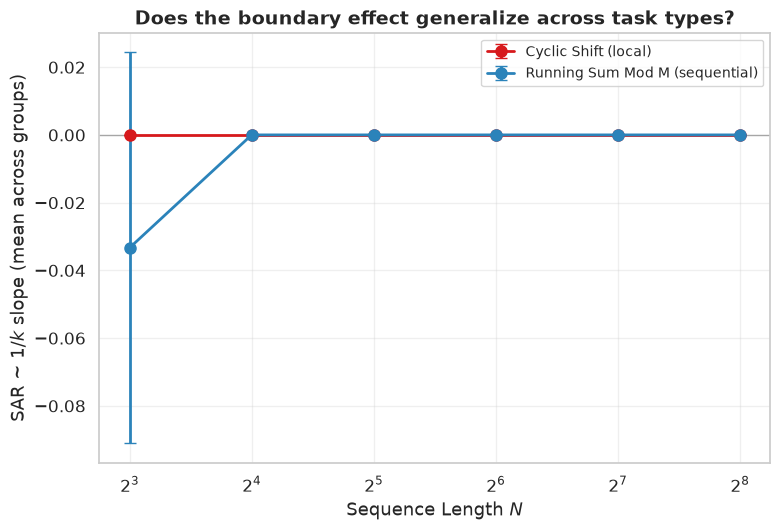


--- SAME-SIGN SLOPE ACROSS TASKS, PER SEQ_LENGTH ---
Seq_Length
8      False
16     False
32     False
64     False
128    False
256    False
dtype: bool

Agrees on direction at 0/6 sequence lengths.


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# CYCLIC-SHIFT vs RUNNING-SUM-MOD-M: DOES THE BOUNDARY EFFECT GENERALIZE?
# ============================================================
# Cyclic shift is a purely position-local task (each output token depends
# only on the matching input token -- no dependency between positions).
# Running-sum-mod-M requires tracking state across the *whole* sequence.
# Comparing their SAR ~ 1/k slopes tests whether the "|" boundary effect
# measured throughout this notebook is specific to one task's dependency
# structure, or holds across tasks that need very different kinds of
# reasoning. Positive slope = SAR rises with boundary density (boundaries
# help); negative = boundaries hurt.

thermo_reg = pd.read_csv(os.path.join(RESULTS_DIR, "thermodynamics_regression.csv"))
modsum_reg = pd.read_csv(os.path.join(RESULTS_DIR, "modsum_regression.csv"))

thermo_sar = thermo_reg[thermo_reg['Metric'] == 'SAR'].rename(columns={'Alphabet': 'Group'}).copy()
thermo_sar['Task'] = 'Cyclic Shift (local)'
modsum_sar = modsum_reg[modsum_reg['Metric'] == 'SAR'].rename(columns={'Modulus': 'Group'}).copy()
modsum_sar['Task'] = 'Running Sum Mod M (sequential)'

combined = pd.concat([
    thermo_sar[['Task', 'Group', 'Seq_Length', 'Slope', 'R_squared']],
    modsum_sar[['Task', 'Group', 'Seq_Length', 'Slope', 'R_squared']],
], ignore_index=True)

print("--- SAR ~ 1/k SLOPE BY TASK, GROUP, SEQ_LENGTH ---")
print(combined.round(4).to_string(index=False))

# --- Per-task summary: mean slope across groups, by sequence length ---
summary = combined.groupby(['Task', 'Seq_Length'])['Slope'].agg(['mean', 'std']).reset_index()
summary['std'] = summary['std'].fillna(0.0)
print("\n--- MEAN SLOPE PER TASK, PER SEQ_LENGTH ---")
print(summary.round(4).to_string(index=False))

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, ax = plt.subplots(figsize=(8, 5.5))
palette = {'Cyclic Shift (local)': '#d7191c', 'Running Sum Mod M (sequential)': '#2b83ba'}
for task, sub in summary.groupby('Task'):
    sub = sub.sort_values('Seq_Length')
    ax.errorbar(sub['Seq_Length'], sub['mean'], yerr=sub['std'],
                marker='o', markersize=8, linewidth=2, capsize=4,
                color=palette.get(task), label=task)

ax.axhline(0.0, color='black', linestyle='-', alpha=0.3, linewidth=1)
ax.set_xscale('log', base=2)
ax.set_xlabel('Sequence Length $N$', fontsize=13)
ax.set_ylabel('SAR ~ $1/k$ slope (mean across groups)', fontsize=13)
ax.set_title('Does the boundary effect generalize across task types?', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'cyclic_vs_modsum_slope_comparison.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\nSaved plot to {plot_path}")
plt.show()

# --- Headline: same sign (both help or both hurt) at each N? ---
pivot = summary.pivot(index='Seq_Length', columns='Task', values='mean')
if pivot.shape[1] == 2:
    same_sign = (pivot.iloc[:, 0] * pivot.iloc[:, 1]) > 0
    print("\n--- SAME-SIGN SLOPE ACROSS TASKS, PER SEQ_LENGTH ---")
    print(same_sign)
    print(f"\nAgrees on direction at {same_sign.sum()}/{len(same_sign)} sequence lengths.")

# Error-Containment, Significance, and Model Validation


--- [Cyclic Shift] RECOVERY PROBABILITY: P(correct | previous token wrong) ---
         Method  Boundary_Adjacent   mean  count
           Base              False 0.1249  25274
Cellular_Bounds              False 0.1548  49925
Cellular_Bounds               True 0.2066  19972

[Cyclic Shift] Recovery right after a boundary: 0.207  vs elsewhere in Cellular trials: 0.155  (+5.2 pp)



--- [Running Sum Mod M] RECOVERY PROBABILITY: P(correct | previous token wrong) ---
         Method  Boundary_Adjacent   mean  count
           Base              False 0.2199  21761
Cellular_Bounds              False 0.1417  51798
Cellular_Bounds               True 0.1389  20960

[Running Sum Mod M] Recovery right after a boundary: 0.139  vs elsewhere in Cellular trials: 0.142  (-0.3 pp)



Saved plot to results/Mistral-7B-Instruct-v0.3/error_containment_recovery.png


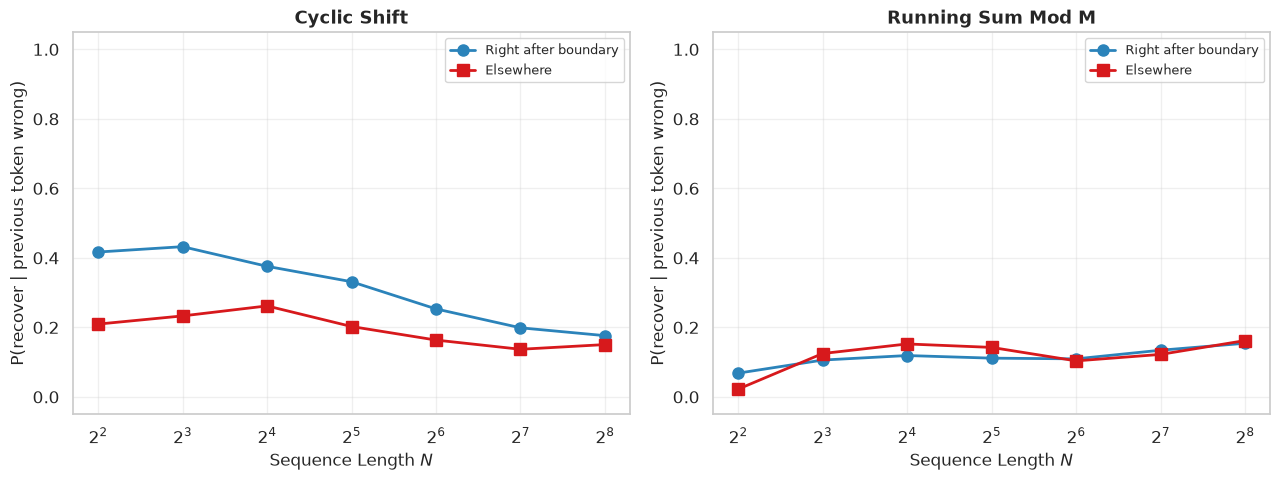

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# ERROR-CONTAINMENT ANALYSIS (does crossing a boundary help recovery?)
# ============================================================
# First_Error_Pos already exists in the saved CSVs but nothing analyzes it.
# This is the direct, mechanistic test of "boundaries contain errors"
# rather than the indirect evidence from the boundary-density regression:
# for every position immediately following a WRONG token, does the model
# recover (produce the next token correctly) more often when a "|" was just
# crossed than when it wasn't? Reconstructed entirely from the already-saved
# Ground_Truth / LLM_Output strings -- no new data collection needed.

def reconstruct_binary_series(ground_truth, llm_output):
    truth = str(ground_truth)
    pred = str(llm_output)[:len(truth)]
    return [1 if i < len(pred) and pred[i] == truth[i] else 0 for i in range(len(truth))]

def is_boundary_adjacent(pos, interval):
    # True if `pos` (0-indexed in the clean, boundary-stripped sequence) is
    # the first character immediately after a "|" was crossed.
    return interval > 0 and pos > 0 and pos % interval == 0

def error_recovery_events(df):
    events = []
    for _, row in df.iterrows():
        series = reconstruct_binary_series(row['Ground_Truth'], row['LLM_Output'])
        interval = row['Interval']
        for i in range(1, len(series)):
            if series[i - 1] == 0:  # previous token was wrong
                events.append({
                    'Method': row['Method'],
                    'Interval': interval,
                    'Seq_Length': row['Seq_Length'],
                    'Boundary_Adjacent': is_boundary_adjacent(i, interval),
                    'Recovered': series[i],
                })
    return pd.DataFrame(events)


def summarize_recovery(events_df, task_label):
    if len(events_df) == 0:
        print(f"[{task_label}] No error-recovery events found (no errors occurred in this data).")
        return None

    summary = (
        events_df.groupby(['Method', 'Boundary_Adjacent'])['Recovered']
                  .agg(['mean', 'count'])
                  .reset_index()
    )
    print(f"\n--- [{task_label}] RECOVERY PROBABILITY: P(correct | previous token wrong) ---")
    print(summary.round(4).to_string(index=False))

    cell_rows = summary[summary['Method'] == 'Cellular_Bounds']
    adj = cell_rows[cell_rows['Boundary_Adjacent'] == True]
    non_adj = cell_rows[cell_rows['Boundary_Adjacent'] == False]
    if len(adj) and len(non_adj):
        p_adj, p_non = adj['mean'].iloc[0], non_adj['mean'].iloc[0]
        print(f"\n[{task_label}] Recovery right after a boundary: {p_adj:.3f}  "
              f"vs elsewhere in Cellular trials: {p_non:.3f}  "
              f"({'+' if p_adj >= p_non else ''}{100*(p_adj-p_non):.1f} pp)")
    return summary


thermo_df = pd.read_csv(os.path.join(RESULTS_DIR, "thermodynamics_grid.csv"))
thermo_events = error_recovery_events(thermo_df)
thermo_recovery_summary = summarize_recovery(thermo_events, "Cyclic Shift")

modsum_df = pd.read_csv(os.path.join(RESULTS_DIR, "running_modsum_grid.csv"))
modsum_events = error_recovery_events(modsum_df)
modsum_recovery_summary = summarize_recovery(modsum_events, "Running Sum Mod M")

# --- Plot: recovery probability by Seq_Length, boundary-adjacent vs not (Cellular only) ---
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, events_df, label in [(axes[0], thermo_events, "Cyclic Shift"),
                              (axes[1], modsum_events, "Running Sum Mod M")]:
    if len(events_df) == 0:
        ax.set_title(f"{label}\n(no error-recovery events)")
        continue
    cell_events = events_df[events_df['Method'] == 'Cellular_Bounds']
    per_N = (
        cell_events.groupby(['Seq_Length', 'Boundary_Adjacent'])['Recovered']
                   .mean()
                   .reset_index()
    )
    for adj_val, color, marker, lbl in [(True, '#2b83ba', 'o', 'Right after boundary'),
                                          (False, '#d7191c', 's', 'Elsewhere')]:
        sub = per_N[per_N['Boundary_Adjacent'] == adj_val].sort_values('Seq_Length')
        if len(sub):
            ax.plot(sub['Seq_Length'], sub['Recovered'], marker=marker, markersize=8,
                    linewidth=2, color=color, label=lbl)
    ax.set_xscale('log', base=2)
    ax.set_xlabel('Sequence Length $N$', fontsize=12)
    ax.set_ylabel('P(recover | previous token wrong)', fontsize=12)
    ax.set_title(label, fontsize=13, fontweight='bold')
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'error_containment_recovery.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\nSaved plot to {plot_path}")
plt.show()

if thermo_recovery_summary is not None:
    thermo_recovery_summary.to_csv(os.path.join(RESULTS_DIR, "thermodynamics_error_recovery.csv"), index=False)
if modsum_recovery_summary is not None:
    modsum_recovery_summary.to_csv(os.path.join(RESULTS_DIR, "modsum_error_recovery.csv"), index=False)

In [13]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon, binomtest
import os

# ============================================================
# STATISTICAL SIGNIFICANCE: Cellular vs Base, paired by seed
# ============================================================
# The regressions show boundary density correlates with accuracy, but don't
# establish that Cellular significantly beats Base at a given N. Base and
# Cellular trials share the same underlying raw sequence per Trial (see the
# "Shared_Sequence" verification in the grid-search cells), so a paired
# test is valid and more powerful than an unpaired one.
#   TAR (continuous, per-token accuracy): paired Wilcoxon signed-rank test.
#   SAR (binary, whole-sequence pass/fail): exact McNemar's test on the
#   discordant-pair counts (implemented directly with scipy.stats.binomtest
#   to avoid adding a statsmodels dependency).

def mcnemar_exact_pvalue(b, c):
    if b + c == 0:
        return 1.0
    return binomtest(min(b, c), b + c, 0.5).pvalue

def paired_significance(df, group_col, task_label):
    results = []
    base = df[df['Method'] == 'Base']
    cell = df[df['Method'] == 'Cellular_Bounds']

    for grp in sorted(df[group_col].unique()):
        for N in sorted(df['Seq_Length'].unique()):
            for interval in sorted(cell['Interval'].unique()):
                b_df = base[(base[group_col] == grp) & (base['Seq_Length'] == N)]
                c_df = cell[(cell[group_col] == grp) & (cell['Seq_Length'] == N) & (cell['Interval'] == interval)]
                if len(b_df) == 0 or len(c_df) == 0:
                    continue

                merged = b_df[['Trial', 'TAR', 'SAR']].merge(
                    c_df[['Trial', 'TAR', 'SAR']], on='Trial', suffixes=('_base', '_cell')
                )
                if len(merged) < 2:
                    continue

                diffs = merged['TAR_cell'] - merged['TAR_base']
                if np.any(diffs != 0):
                    _, p_tar = wilcoxon(merged['TAR_cell'], merged['TAR_base'])
                else:
                    p_tar = 1.0

                base_pass = merged['SAR_base'] >= 0.5
                cell_pass = merged['SAR_cell'] >= 0.5
                b_disc = int((base_pass & ~cell_pass).sum())
                c_disc = int((~base_pass & cell_pass).sum())
                p_sar = mcnemar_exact_pvalue(b_disc, c_disc)

                results.append({
                    group_col: grp, 'Seq_Length': N, 'Interval': interval,
                    'N_pairs': len(merged),
                    'Mean_TAR_Base': merged['TAR_base'].mean(),
                    'Mean_TAR_Cell': merged['TAR_cell'].mean(),
                    'P_value_TAR_Wilcoxon': p_tar,
                    'SAR_Base_pass': int(base_pass.sum()),
                    'SAR_Cell_pass': int(cell_pass.sum()),
                    'P_value_SAR_McNemar': p_sar,
                    'Significant_TAR_p05': p_tar < 0.05,
                    'Significant_SAR_p05': p_sar < 0.05,
                })

    results_df = pd.DataFrame(results)
    print(f"\n--- [{task_label}] PAIRED SIGNIFICANCE: Cellular vs Base ---")
    print(results_df.round(4).to_string(index=False))
    if len(results_df):
        n_sig_tar = results_df['Significant_TAR_p05'].sum()
        n_sig_sar = results_df['Significant_SAR_p05'].sum()
        print(f"\n[{task_label}] Significant at p<0.05: TAR {n_sig_tar}/{len(results_df)} conditions, "
              f"SAR {n_sig_sar}/{len(results_df)} conditions")
    return results_df

thermo_df = pd.read_csv(os.path.join(RESULTS_DIR, "thermodynamics_grid.csv"))
thermo_sig = paired_significance(thermo_df, 'Alphabet_Size', "Cyclic Shift")
thermo_sig.to_csv(os.path.join(RESULTS_DIR, "thermodynamics_significance.csv"), index=False)

modsum_df = pd.read_csv(os.path.join(RESULTS_DIR, "running_modsum_grid.csv"))
modsum_sig = paired_significance(modsum_df, 'Modulus', "Running Sum Mod M")
modsum_sig.to_csv(os.path.join(RESULTS_DIR, "modsum_significance.csv"), index=False)


--- [Cyclic Shift] PAIRED SIGNIFICANCE: Cellular vs Base ---
 Alphabet_Size  Seq_Length  Interval  N_pairs  Mean_TAR_Base  Mean_TAR_Cell  P_value_TAR_Wilcoxon  SAR_Base_pass  SAR_Cell_pass  P_value_SAR_McNemar  Significant_TAR_p05  Significant_SAR_p05
             2           4         2       20         0.6875         0.4000                0.0008              6              0               0.0312                 True                 True
             2           8         2       20         0.4062         0.3750                0.6248              0              0               1.0000                False                False
             2           8         4       20         0.4062         0.4875                0.3360              0              1               1.0000                False                False
             2          16         2       20         0.3656         0.4250                0.4868              0              0               1.0000                False     


--- [Running Sum Mod M] PAIRED SIGNIFICANCE: Cellular vs Base ---
 Modulus  Seq_Length  Interval  N_pairs  Mean_TAR_Base  Mean_TAR_Cell  P_value_TAR_Wilcoxon  SAR_Base_pass  SAR_Cell_pass  P_value_SAR_McNemar  Significant_TAR_p05  Significant_SAR_p05
       2           4         2       20         0.6750         0.6000                0.4357              2              7               0.1797                False                False
       2           8         2       20         0.5688         0.3312                0.0036              1              0               1.0000                 True                False
       2           8         4       20         0.5688         0.4250                0.0597              1              0               1.0000                False                False
       2          16         2       20         0.5000         0.2531                0.0007              0              0               1.0000                 True                False
       2

In [14]:
import pandas as pd
from transformers import AutoTokenizer
import os

# ============================================================
# TOKEN OVERHEAD: Cellular vs Base
# ============================================================
# The framing here (and in the source paper) is "cheaper than multi-call
# divide-and-conquer" -- this quantifies the cost side of that tradeoff.
# Boundaries add extra "|" characters to both input and output; this counts
# that overhead directly from the already-saved Input_Given / LLM_Output
# strings, no new generation needed. Wall-clock latency isn't recoverable
# retroactively since it wasn't timed during the grid search -- add a timer
# around model.generate() in run_single_trial in a future run for that.

tok_for_counting = AutoTokenizer.from_pretrained(MODEL_ID)

def count_tokens(text):
    return len(tok_for_counting(str(text), add_special_tokens=False)['input_ids'])

def token_overhead_summary(df, task_label):
    df = df.copy()
    df['Input_Tokens'] = df['Input_Given'].apply(count_tokens)
    df['Output_Tokens'] = df['LLM_Output'].apply(count_tokens)
    df['Total_Tokens'] = df['Input_Tokens'] + df['Output_Tokens']

    summary = (
        df.groupby(['Method', 'Seq_Length'])[['Input_Tokens', 'Output_Tokens', 'Total_Tokens']]
          .mean()
          .reset_index()
    )
    print(f"\n--- [{task_label}] MEAN TOKEN COUNT BY METHOD, SEQ_LENGTH ---")
    print(summary.round(2).to_string(index=False))

    pivot = summary.pivot(index='Seq_Length', columns='Method', values='Total_Tokens')
    if 'Base' in pivot.columns and 'Cellular_Bounds' in pivot.columns:
        pivot['Overhead_%'] = 100 * (pivot['Cellular_Bounds'] - pivot['Base']) / pivot['Base']
        print(f"\n[{task_label}] Cellular token overhead vs Base:")
        print(pivot.round(2).to_string())
    return summary

thermo_df = pd.read_csv(os.path.join(RESULTS_DIR, "thermodynamics_grid.csv"))
thermo_token_summary = token_overhead_summary(thermo_df, "Cyclic Shift")
thermo_token_summary.to_csv(os.path.join(RESULTS_DIR, "thermodynamics_token_overhead.csv"), index=False)

modsum_df = pd.read_csv(os.path.join(RESULTS_DIR, "running_modsum_grid.csv"))
modsum_token_summary = token_overhead_summary(modsum_df, "Running Sum Mod M")
modsum_token_summary.to_csv(os.path.join(RESULTS_DIR, "modsum_token_overhead.csv"), index=False)


--- [Cyclic Shift] MEAN TOKEN COUNT BY METHOD, SEQ_LENGTH ---
         Method  Seq_Length  Input_Tokens  Output_Tokens  Total_Tokens
           Base           4          2.60           2.57          5.17
           Base           8          4.77           4.85          9.62
           Base          16          9.32           9.33         18.65
           Base          32         18.10          18.87         36.97
           Base          64         35.93          38.03         73.97
           Base         128         72.02          74.03        146.05
           Base         256        142.83         146.33        289.17
Cellular_Bounds           4          3.20           2.43          5.63
Cellular_Bounds           8          6.71           4.56         11.27
Cellular_Bounds          16         12.98           9.30         22.28
Cellular_Bounds          32         26.66          18.16         44.82
Cellular_Bounds          64         53.71          36.03         89.73
Cellular_Bound

In [15]:
import pandas as pd
import numpy as np
import os

# ============================================================
# HELD-OUT VALIDATION OF THE SK MODEL FIT
# ============================================================
# Fitting Eq. 14 and reporting R^2 only shows the model can interpolate the
# grid it was fit on. A real test: fit beta0/alpha using only the SMALLER
# sequence lengths, then use that fit to PREDICT SAR at the held-out LARGER
# lengths (the cliff region) -- if the model captures something real about
# error accumulation, it should extrapolate into the cliff, not just trace
# through points it already saw. Reuses sk_model / fit_sk from the SK-fit
# cells above.

def fit_sk_holdout(N_vals, sar_vals, n_holdout=2):
    N_vals = np.asarray(N_vals, dtype=np.float64)
    sar_vals = np.asarray(sar_vals, dtype=np.float64)
    order = np.argsort(N_vals)
    N_vals, sar_vals = N_vals[order], sar_vals[order]
    if len(N_vals) <= n_holdout + 2:  # need enough points left to fit 2 free params
        return None
    N_train, sar_train = N_vals[:-n_holdout], sar_vals[:-n_holdout]
    N_test, sar_test = N_vals[-n_holdout:], sar_vals[-n_holdout:]
    beta0, alpha, n_star = fit_sk(N_train, sar_train)
    if np.isnan(beta0):
        return None
    sar_pred = sk_model(N_test, beta0, alpha)
    mae = np.mean(np.abs(sar_pred - sar_test))
    return {
        'N_train_max': N_train.max(), 'Beta0_train': beta0, 'Alpha_train': alpha,
        'N_star_train': n_star, 'N_test': list(N_test),
        'SAR_test_actual': list(np.round(sar_test, 4)),
        'SAR_test_predicted': list(np.round(sar_pred, 4)),
        'MAE_held_out': mae,
    }

def run_holdout_validation(csv_name, group_col, task_label, n_holdout=2):
    df_sk = pd.read_csv(os.path.join(RESULTS_DIR, csv_name))
    rows = []
    for grp in sorted(df_sk[group_col].unique()):
        sub_G = df_sk[df_sk[group_col] == grp]
        for method, sub_M in sub_G.groupby('Method'):
            for interval, sub_I in sub_M.groupby('Interval'):
                per_N = sub_I.groupby('Seq_Length')['SAR'].mean().reset_index()
                if len(per_N) < 3:
                    continue
                result = fit_sk_holdout(per_N['Seq_Length'], per_N['SAR'], n_holdout=n_holdout)
                if result is None:
                    continue
                result.update({group_col: grp, 'Method': method, 'Interval': interval})
                rows.append(result)

    result_df = pd.DataFrame(rows)
    print(f"\n--- [{task_label}] SK MODEL HELD-OUT VALIDATION (predict largest {n_holdout} lengths from the rest) ---")
    if len(result_df):
        print(result_df[[group_col, 'Method', 'Interval', 'N_train_max', 'MAE_held_out']].round(4).to_string(index=False))
        print(f"\n[{task_label}] Mean absolute error on held-out lengths: {result_df['MAE_held_out'].mean():.4f}")
    else:
        print(f"[{task_label}] Not enough distinct sequence lengths per condition to hold any out.")
    return result_df

thermo_holdout = run_holdout_validation("thermodynamics_grid.csv", "Alphabet_Size", "Cyclic Shift")
thermo_holdout.to_csv(os.path.join(RESULTS_DIR, "thermodynamics_sk_holdout.csv"), index=False)

modsum_holdout = run_holdout_validation("running_modsum_grid.csv", "Modulus", "Running Sum Mod M")
modsum_holdout.to_csv(os.path.join(RESULTS_DIR, "modsum_sk_holdout.csv"), index=False)


--- [Cyclic Shift] SK MODEL HELD-OUT VALIDATION (predict largest 2 lengths from the rest) ---
 Alphabet_Size          Method  Interval  N_train_max  MAE_held_out
             2            Base         0         64.0           0.0
             2 Cellular_Bounds         2         64.0           0.0
             2 Cellular_Bounds         4         64.0           0.0
             2 Cellular_Bounds         8         64.0           0.0
             4            Base         0         64.0           0.0
             4 Cellular_Bounds         2         64.0           0.0
             4 Cellular_Bounds         4         64.0           0.0
             4 Cellular_Bounds         8         64.0           0.0
             8            Base         0         64.0           0.0
             8 Cellular_Bounds         2         64.0           0.0
             8 Cellular_Bounds         4         64.0           0.0
             8 Cellular_Bounds         8         64.0           0.0

[Cyclic Shift] Mean 


--- [Running Sum Mod M] SK MODEL HELD-OUT VALIDATION (predict largest 2 lengths from the rest) ---
 Modulus          Method  Interval  N_train_max  MAE_held_out
       2            Base         0         64.0           0.0
       2 Cellular_Bounds         2         64.0           0.0
       2 Cellular_Bounds         4         64.0           0.0
       2 Cellular_Bounds         8         64.0           0.0
       4            Base         0         64.0           0.0
       4 Cellular_Bounds         2         64.0           0.0
       4 Cellular_Bounds         4         64.0           0.0
       4 Cellular_Bounds         8         64.0           0.0
       8            Base         0         64.0           0.0
       8 Cellular_Bounds         2         64.0           0.0
       8 Cellular_Bounds         4         64.0           0.0
       8 Cellular_Bounds         8         64.0           0.0

[Running Sum Mod M] Mean absolute error on held-out lengths: 0.0000


# Boundary Ablation (marker identity, placement, density vs count)

In [16]:
import pandas as pd
import numpy as np
import random
import itertools
import torch
import os
from tqdm import tqdm

ABLATION_ALPHABET_SIZE = 2
ABLATION_SEQUENCE_LENGTHS = [8, 16, 32, 64]
ABLATION_TRIALS = 15

engine_ablation = TaskEngine(alphabet_size=ABLATION_ALPHABET_SIZE)

def boundary_positions_periodic(length, interval):
    return set(i for i in range(interval - 1, length - 1, interval))

def boundary_positions_random(length, count, rng):
    candidates = list(range(length - 1))
    return set(rng.sample(candidates, min(count, len(candidates))))

def boundary_positions_fixed_count(length, count):
    if count <= 0 or length <= 1:
        return set()
    step = length / (count + 1)
    positions = {int(round(step * (j + 1))) - 1 for j in range(count)}
    return {p for p in positions if 0 <= p < length - 1}

def build_ablation_variant(raw_input, marker, placement, interval=4, fixed_count=4, rng=None):
    rng = rng or random
    length = len(raw_input)
    if placement == "periodic":
        boundary_positions = boundary_positions_periodic(length, interval)
    elif placement == "random":
        n_boundaries = len(boundary_positions_periodic(length, interval))
        boundary_positions = boundary_positions_random(length, n_boundaries, rng)
    elif placement == "periodic_fixed_count":
        boundary_positions = boundary_positions_fixed_count(length, fixed_count)
    else:
        raise ValueError(placement)

    input_w_bounds, output_w_bounds = "", ""
    for i, char in enumerate(raw_input):
        shifted_char = engine_ablation.alphabet[(engine_ablation.char_to_idx[char] + 1) % ABLATION_ALPHABET_SIZE]
        input_w_bounds += char
        output_w_bounds += shifted_char
        if i in boundary_positions:
            input_w_bounds += marker
            output_w_bounds += marker

    prompt = f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(engine_ablation.alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {engine_ablation.alphabet[-1]} -> {engine_ablation.alphabet[0]}, and {engine_ablation.alphabet[0]} -> {engine_ablation.alphabet[1]}.
Constraint: The input contains structural boundary markers ({marker}). DO NOT shift them. Copy them exactly to the output.
No spaces, no explanations.

Input: {input_w_bounds}
Output: """
    return input_w_bounds, output_w_bounds, prompt, len(boundary_positions)


ABLATION_CONDITIONS = [
    {"Marker": "|", "Placement": "periodic",            "Ablation_Axis": "marker+placement baseline"},
    {"Marker": ";", "Placement": "periodic",            "Ablation_Axis": "marker identity"},
    {"Marker": "#", "Placement": "periodic",            "Ablation_Axis": "marker identity"},
    {"Marker": "|", "Placement": "random",               "Ablation_Axis": "placement regularity"},
    {"Marker": "|", "Placement": "periodic_fixed_count", "Ablation_Axis": "density vs fixed count"},
]

def run_ablation_trial(raw_input, condition, N, trial, rng):
    marker, placement = condition["Marker"], condition["Placement"]
    inp, truth, prompt, n_boundaries = build_ablation_variant(
        raw_input, marker=marker, placement=placement, interval=4, fixed_count=4, rng=rng
    )

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    max_tokens_needed = int(N * 1.5) + 20 + n_boundaries
    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=max_tokens_needed, do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    full_response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    pred = full_response[len(prompt):].strip()
    pred = pred.split("Explanation")[0].split("\n")[0].strip()

    clean_pred = pred.replace(marker, "").replace(" ", "").replace("\n", "")
    clean_truth = truth.replace(marker, "")
    clean_pred = clean_pred[:len(clean_truth)]

    binary_series = [1 if i < len(clean_pred) and clean_pred[i] == clean_truth[i] else 0
                      for i in range(len(clean_truth))]
    tar = sum(binary_series) / len(clean_truth) if clean_truth else 0.0
    sar = 1.0 if (len(binary_series) == len(clean_truth) and sum(binary_series) == len(binary_series)) else 0.0

    return {
        "Marker": marker, "Placement": placement, "Ablation_Axis": condition["Ablation_Axis"],
        "Seq_Length": N, "Trial": trial, "N_Boundaries": n_boundaries,
        "TAR": tar, "SAR": sar,
    }


ablation_tasks = [
    (cond, N, t)
    for cond in ABLATION_CONDITIONS
    for N in ABLATION_SEQUENCE_LENGTHS
    for t in range(ABLATION_TRIALS)
]
print(f"\nStarting boundary ablation sweep: {len(ablation_tasks)} evaluations...")

ablation_results = []
for (cond, N, t) in tqdm(ablation_tasks, desc="Boundary ablation"):
    local_seed = 70_000 * N + 1000 * ABLATION_CONDITIONS.index(cond) + t
    rng = random.Random(local_seed)
    raw_input = engine_ablation.generate_raw_input(N, rng=rng)
    try:
        result = run_ablation_trial(raw_input, cond, N, t, rng)
        ablation_results.append(result)
    except Exception as exc:
        print(f"Task failed: {cond}, N={N}, trial={t} | Error: {exc}")

ablation_df = pd.DataFrame(ablation_results)
ablation_csv = os.path.join(RESULTS_DIR, "boundary_ablation_grid.csv")
ablation_df.to_csv(ablation_csv, index=False)
print(f"\nAblation sweep complete. Saved to '{ablation_csv}'")

summary = ablation_df.groupby(["Ablation_Axis", "Marker", "Placement", "Seq_Length"])[["TAR", "SAR"]].mean().reset_index()
print("\n--- MEAN ACCURACY BY ABLATION CONDITION ---")
print(summary.round(4).to_string(index=False))



Starting boundary ablation sweep: 300 evaluations...


Boundary ablation:   0%|          | 0/300 [00:00<?, ?it/s]

Boundary ablation:   0%|          | 1/300 [00:01<05:00,  1.01s/it]

Boundary ablation:   1%|          | 2/300 [00:02<04:58,  1.00s/it]

Boundary ablation:   1%|          | 3/300 [00:03<04:58,  1.00s/it]

...

Boundary ablation:  99%|█████████▉| 298/300 [09:35<00:03,  1.93s/it]

Boundary ablation: 100%|█████████▉| 299/300 [09:38<00:02,  2.45s/it]

Boundary ablation: 100%|██████████| 300/300 [09:42<00:00,  2.80s/it]

Boundary ablation: 100%|██████████| 300/300 [09:42<00:00,  1.94s/it]


Ablation sweep complete. Saved to 'results/Mistral-7B-Instruct-v0.3/boundary_ablation_grid.csv'

--- MEAN ACCURACY BY ABLATION CONDITION ---
            Ablation_Axis Marker            Placement  Seq_Length    TAR    SAR
   density vs fixed count      | periodic_fixed_count           8 0.4667 0.0000
   density vs fixed count      | periodic_fixed_count          16 0.5292 0.0000
   density vs fixed count      | periodic_fixed_count          32 0.4083 0.0000
   density vs fixed count      | periodic_fixed_count          64 0.3323 0.0000
          marker identity      #             periodic           8 0.4750 0.0000
          marker identity      #             periodic          16 0.4792 0.0000
          marker identity      #             periodic          32 0.4188 0.0000
          marker identity      #             periodic          64 0.3312 0.0000
          marker identity      ;             periodic           8 0.3333 0.0000
          marker identity      ;             periodic     

--- BASE (no boundaries) REFERENCE ---
 Seq_Length    TAR  SAR
          4 0.6875  0.3
          8 0.4062  0.0
         16 0.3656  0.0
         32 0.3609  0.0
         64 0.2344  0.0
        128 0.2770  0.0
        256 0.2150  0.0

--- MEAN ACCURACY BY ABLATION CONDITION ---
            Ablation_Axis Marker            Placement  Seq_Length    TAR    SAR
   density vs fixed count      | periodic_fixed_count           8 0.4667 0.0000
   density vs fixed count      | periodic_fixed_count          16 0.5292 0.0000
   density vs fixed count      | periodic_fixed_count          32 0.4083 0.0000
   density vs fixed count      | periodic_fixed_count          64 0.3323 0.0000
          marker identity      #             periodic           8 0.4750 0.0000
          marker identity      #             periodic          16 0.4792 0.0000
          marker identity      #             periodic          32 0.4188 0.0000
          marker identity      #             periodic          64 0.3312 0.0000
    


Saved plot to results/Mistral-7B-Instruct-v0.3/boundary_ablation_analysis.png


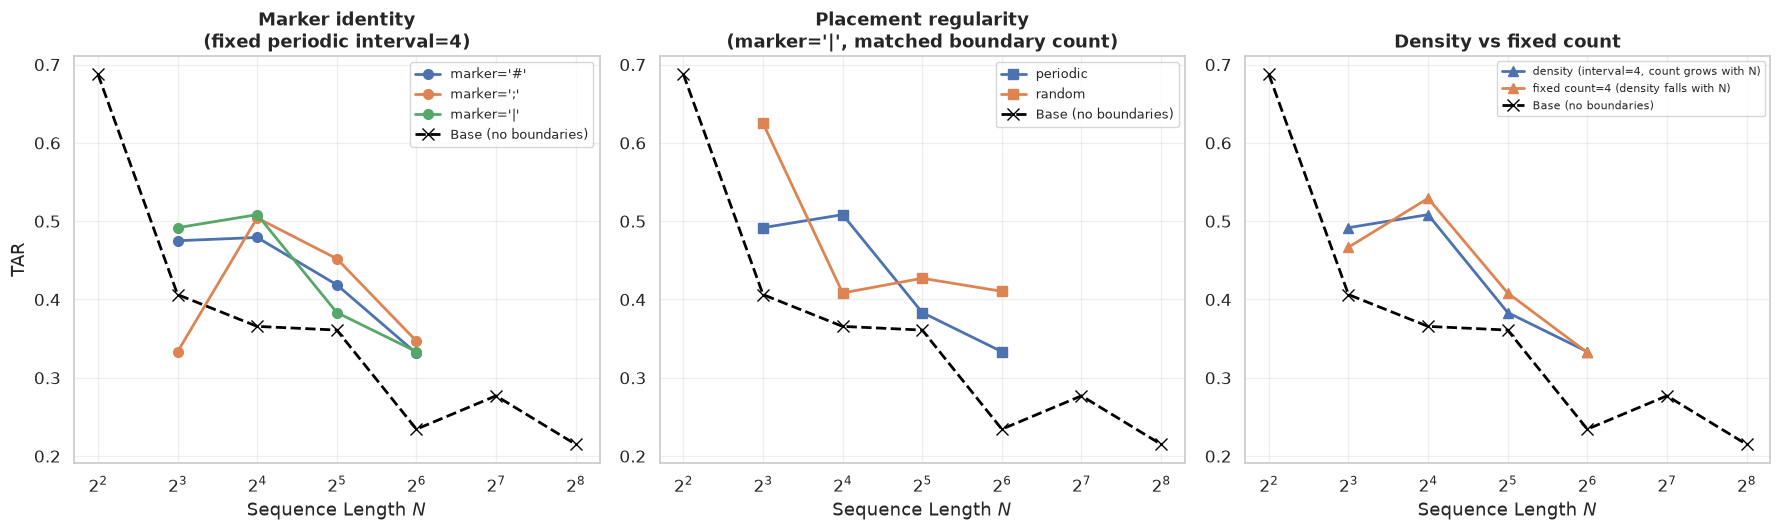

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

ablation_df = pd.read_csv(os.path.join(RESULTS_DIR, "boundary_ablation_grid.csv"))

base_df = pd.read_csv(os.path.join(RESULTS_DIR, "thermodynamics_grid.csv"))
base_ref = (
    base_df[(base_df["Method"] == "Base") & (base_df["Alphabet_Size"] == ABLATION_ALPHABET_SIZE)]
    .groupby("Seq_Length")[["TAR", "SAR"]]
    .mean()
    .reset_index()
)
print("--- BASE (no boundaries) REFERENCE ---")
print(base_ref.round(4).to_string(index=False))

summary = ablation_df.groupby(["Ablation_Axis", "Marker", "Placement", "Seq_Length"])[["TAR", "SAR"]].mean().reset_index()
print("\n--- MEAN ACCURACY BY ABLATION CONDITION ---")
print(summary.round(4).to_string(index=False))

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

ax = axes[0]
marker_sub = summary[summary["Placement"] == "periodic"]
for marker, sub in marker_sub.groupby("Marker"):
    sub = sub.sort_values("Seq_Length")
    ax.plot(sub["Seq_Length"], sub["TAR"], marker='o', markersize=7, linewidth=2, label=f"marker='{marker}'")
ax.plot(base_ref["Seq_Length"], base_ref["TAR"], marker='x', markersize=8, linewidth=2,
        linestyle='--', color='black', label="Base (no boundaries)")
ax.set_xscale('log', base=2)
ax.set_xlabel("Sequence Length $N$")
ax.set_ylabel("TAR")
ax.set_title("Marker identity\n(fixed periodic interval=4)", fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
placement_sub = summary[(summary["Marker"] == "|") & (summary["Placement"].isin(["periodic", "random"]))]
for placement, sub in placement_sub.groupby("Placement"):
    sub = sub.sort_values("Seq_Length")
    ax.plot(sub["Seq_Length"], sub["TAR"], marker='s', markersize=7, linewidth=2, label=placement)
ax.plot(base_ref["Seq_Length"], base_ref["TAR"], marker='x', markersize=8, linewidth=2,
        linestyle='--', color='black', label="Base (no boundaries)")
ax.set_xscale('log', base=2)
ax.set_xlabel("Sequence Length $N$")
ax.set_title("Placement regularity\n(marker='|', matched boundary count)", fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[2]
count_sub = summary[(summary["Marker"] == "|") & (summary["Placement"].isin(["periodic", "periodic_fixed_count"]))]
labels = {"periodic": "density (interval=4, count grows with N)", "periodic_fixed_count": "fixed count=4 (density falls with N)"}
for placement, sub in count_sub.groupby("Placement"):
    sub = sub.sort_values("Seq_Length")
    ax.plot(sub["Seq_Length"], sub["TAR"], marker='^', markersize=7, linewidth=2, label=labels[placement])
ax.plot(base_ref["Seq_Length"], base_ref["TAR"], marker='x', markersize=8, linewidth=2,
        linestyle='--', color='black', label="Base (no boundaries)")
ax.set_xscale('log', base=2)
ax.set_xlabel("Sequence Length $N$")
ax.set_title("Density vs fixed count", fontweight='bold')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, "boundary_ablation_analysis.png")
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
print(f"\nSaved plot to {plot_path}")
plt.show()


# Integer Addition Task

In [18]:
import pandas as pd
import numpy as np
import random
import itertools
import torch
import os
from tqdm import tqdm

class AdditionTaskEngine:
    def _sample_pair(self, length, rng):
        for _ in range(200):
            a = [rng.randrange(10) for _ in range(length)]
            b = [rng.randrange(10) for _ in range(length)]
            if a[0] == 0: a[0] = rng.randrange(1, 10)
            if b[0] == 0: b[0] = rng.randrange(1, 10)
            carry = 0
            total = []
            for i in range(length - 1, -1, -1):
                s = a[i] + b[i] + carry
                total.append(s % 10)
                carry = s // 10
            if carry == 0:
                return a, b, list(reversed(total))
        raise RuntimeError(f"failed to sample a non-overflowing {length}-digit pair")

    def build_prompt(self, length, interval, rng=None):
        rng = rng or random
        a, b, total = self._sample_pair(length, rng)
        a_str = "".join(map(str, a))
        b_str = "".join(map(str, b))
        sum_str = "".join(map(str, total))

        combined = list(a_str + b_str)
        bounded = []
        for i, d in enumerate(combined):
            bounded.append(d)
            if interval > 0 and (i + 1) % interval == 0 and i != len(combined) - 1:
                bounded.append("|")
        input_str = "".join(bounded)

        prompt = f"""You are a deterministic arithmetic calculator.
Task: Add two {length}-digit numbers, given as a single digit stream: the first {length} digits are the first number, the next {length} digits are the second number.
Constraint: The input may contain vertical bars (|) as structural boundaries -- they carry no numeric meaning, ignore them when computing.
Output ONLY the {length}-digit sum (zero-padded to {length} digits if needed). No spaces, no explanations.

Input: {input_str}
Output: """
        return input_str, sum_str, prompt


ADD_SEQUENCE_LENGTHS = [4, 8, 16, 32, 64]
ADD_PERIODIC_INTERVALS = [0, 4, 8, 16]
ADD_TRIALS = 20

engine_add = AdditionTaskEngine()

def run_addition_trial(task_params):
    N, k, t = task_params
    method = "Base" if k == 0 else "Cellular_Bounds"
    local_seed = 90_000 * N + 100 * k + t
    rng = random.Random(local_seed)

    inp, truth, prompt = engine_add.build_prompt(N, interval=k, rng=rng)

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    max_tokens_needed = N + 20
    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=max_tokens_needed, do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    full_response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    pred = full_response[len(prompt):].strip()
    pred = pred.split("Explanation")[0].split("\n")[0].strip()

    clean_pred = "".join(ch for ch in pred if ch.isdigit())[:len(truth)]
    binary_series = [1 if i < len(clean_pred) and clean_pred[i] == truth[i] else 0 for i in range(len(truth))]
    tar = sum(binary_series) / len(truth) if truth else 0.0
    sar = 1.0 if (len(binary_series) == len(truth) and sum(binary_series) == len(binary_series)) else 0.0
    first_error = binary_series.index(0) if 0 in binary_series else len(binary_series)

    return {
        "Method": method, "Interval": k, "Seq_Length": N, "Trial": t,
        "TAR": tar, "SAR": sar, "First_Error_Pos": first_error,
        "Input_Given": inp, "Ground_Truth": truth, "LLM_Output": clean_pred,
    }

addition_tasks = [
    (N, k, t)
    for N in ADD_SEQUENCE_LENGTHS
    for k in ADD_PERIODIC_INTERVALS
    for t in range(ADD_TRIALS)
    if k == 0 or k < 2 * N
]
print(f"\nStarting integer-addition grid search: {len(addition_tasks)} evaluations...")

addition_results = []
for task in tqdm(addition_tasks, desc="Addition"):
    try:
        addition_results.append(run_addition_trial(task))
    except Exception as exc:
        print(f"Task failed: {task} | Error: {exc}")

addition_df = pd.DataFrame(addition_results)
addition_csv = os.path.join(RESULTS_DIR, "addition_grid.csv")
addition_df.to_csv(addition_csv, index=False)
print(f"\nAddition grid search complete. Saved to '{addition_csv}'")

summary = addition_df.groupby(["Seq_Length", "Method"])[["TAR", "SAR"]].mean().reset_index()
print("\n--- AVERAGE ACCURACY BY LENGTH & METHOD ---")
print(summary.to_string(index=False))



Starting integer-addition grid search: 340 evaluations...


Addition:   0%|          | 0/340 [00:00<?, ?it/s]

Addition:   0%|          | 1/340 [00:00<04:09,  1.36it/s]

Addition:   1%|          | 2/340 [00:01<04:07,  1.36it/s]

Addition:   1%|          | 3/340 [00:02<04:07,  1.36it/s]

...

Addition:  99%|█████████▉| 338/340 [08:14<00:05,  2.55s/it]

Addition: 100%|█████████▉| 339/340 [08:17<00:02,  2.55s/it]

Addition: 100%|██████████| 340/340 [08:19<00:00,  2.55s/it]

Addition: 100%|██████████| 340/340 [08:19<00:00,  1.47s/it]


Addition grid search complete. Saved to 'results/Mistral-7B-Instruct-v0.3/addition_grid.csv'

--- AVERAGE ACCURACY BY LENGTH & METHOD ---
 Seq_Length          Method      TAR      SAR
          4            Base 0.112500 0.000000
          4 Cellular_Bounds 0.925000 0.800000
          8            Base 0.137500 0.000000
          8 Cellular_Bounds 0.496875 0.350000
         16            Base 0.118750 0.000000
         16 Cellular_Bounds 0.352083 0.116667
         32            Base 0.101562 0.000000
         32 Cellular_Bounds 0.092708 0.000000
         64            Base 0.099219 0.000000
         64 Cellular_Bounds 0.099219 0.000000


Saved plot to results/Mistral-7B-Instruct-v0.3/addition_scaling_law.png


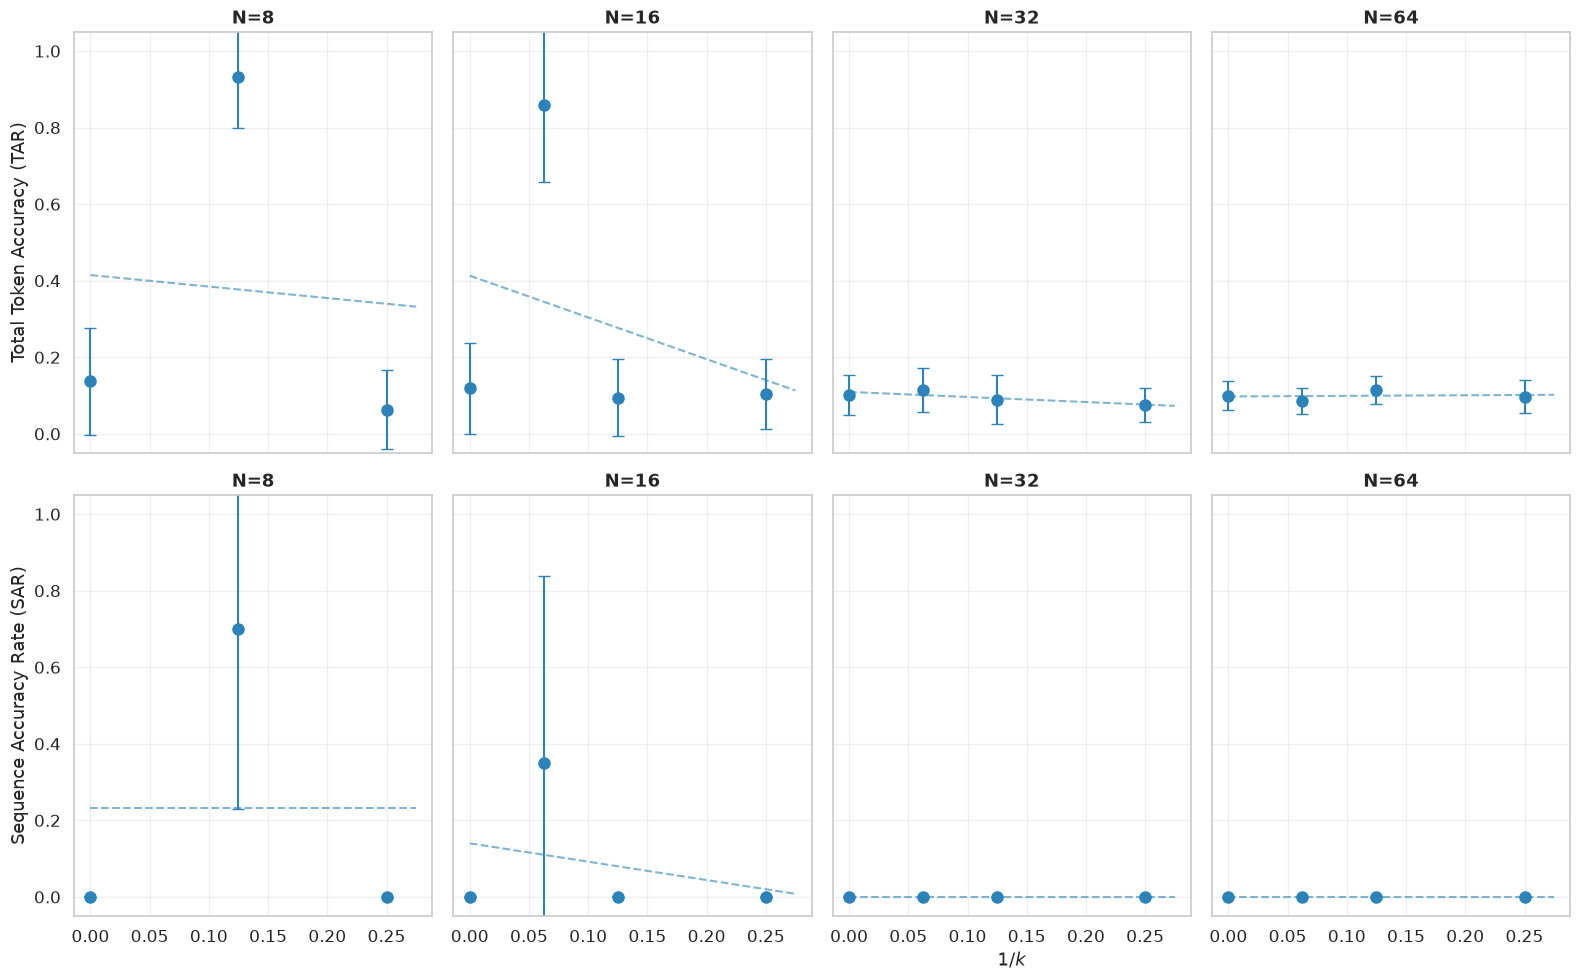

Metric  Seq_Length   Slope  R_squared
   TAR           8 -0.3000     0.0061
   TAR          16 -1.0914     0.0954
   TAR          32 -0.1321     0.7091
   TAR          64  0.0157     0.0198
   SAR           8  0.0000     0.0000
   SAR          16 -0.4800     0.0857
   SAR          32  0.0000        NaN
   SAR          64  0.0000        NaN



--- ADDITION TASK: SK MODEL FIT ---
         Method  Interval  Beta0  Alpha  N_star
           Base         0 0.1130 1.4520  6.8458
Cellular_Bounds         4 0.1130 1.4520  6.8458
Cellular_Bounds         8 0.0026 1.5036 15.6261
Cellular_Bounds        16 0.0089 1.1421 36.5037


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import seaborn as sns
import os

df = pd.read_csv(os.path.join(RESULTS_DIR, "addition_grid.csv"))
df['Inv_K'] = df['Interval'].apply(lambda k: 0.0 if k == 0 else 1.0/k)
df = df[df['Seq_Length'] >= 8]

summary = df.groupby(['Seq_Length', 'Inv_K'])[['TAR','SAR']].agg(['mean','std'])
summary.columns = ['_'.join(c) for c in summary.columns]
summary = summary.reset_index().sort_values(['Seq_Length','Inv_K'])
summary[['TAR_std','SAR_std']] = summary[['TAR_std','SAR_std']].fillna(0.0)

seq_lengths = sorted(summary['Seq_Length'].unique())
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(2, max(len(seq_lengths),1), figsize=(4*max(len(seq_lengths),1), 10), sharex=True, sharey=True, squeeze=False)

regression_results = []
for row, (metric, ylabel) in enumerate([('TAR','Total Token Accuracy (TAR)'), ('SAR','Sequence Accuracy Rate (SAR)')]):
    for i, N in enumerate(seq_lengths):
        ax = axes[row][i]
        sub = summary[summary['Seq_Length']==N]
        if len(sub) >= 2:
            slope, intercept, r, p, se = linregress(sub['Inv_K'], sub[f'{metric}_mean'])
            regression_results.append(dict(Metric=metric, Seq_Length=N, Slope=slope, R_squared=r**2))
            ax.errorbar(sub['Inv_K'], sub[f'{metric}_mean'], yerr=sub[f'{metric}_std'], fmt='o',
                        color='#2b83ba', markersize=8, capsize=4, linestyle='none')
            x_fit = np.linspace(0, sub['Inv_K'].max()*1.1, 100)
            ax.plot(x_fit, slope*x_fit+intercept, linestyle='--', color='#2b83ba', alpha=0.6)
        ax.set_title(f'N={N}', fontweight='bold')
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True, alpha=0.3)
        if i == 0: ax.set_ylabel(ylabel)
        if row==1 and i==len(seq_lengths)//2: ax.set_xlabel('$1/k$')

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'addition_scaling_law.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"Saved plot to {plot_path}")
plt.show()

results_df = pd.DataFrame(regression_results)
print(results_df.round(4).to_string(index=False))
results_df.to_csv(os.path.join(RESULTS_DIR, "addition_regression.csv"), index=False)

sk_results = []
for method, sub_M in df.groupby('Method'):
    for interval, sub_I in sub_M.groupby('Interval'):
        per_N = sub_I.groupby('Seq_Length')['SAR'].mean().reset_index()
        if len(per_N) < 3:
            continue
        beta0, alpha, n_star = fit_sk(per_N['Seq_Length'], per_N['SAR'])
        sk_results.append(dict(Method=method, Interval=interval, Beta0=beta0, Alpha=alpha, N_star=n_star))

sk_df = pd.DataFrame(sk_results)
print("\n--- ADDITION TASK: SK MODEL FIT ---")
print(sk_df.round(4).to_string(index=False))
sk_df.to_csv(os.path.join(RESULTS_DIR, "addition_sk_fit.csv"), index=False)


# Prompt-Wording Robustness

In [20]:
import pandas as pd
import numpy as np
import random
import torch
import os
from tqdm import tqdm

def prompt_template_original(alphabet, input_str):
    return f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {alphabet[-1]} -> {alphabet[0]}, and {alphabet[0]} -> {alphabet[1]}.
Constraint: The input contains vertical bars (|). These are structural boundaries. DO NOT shift them. Copy them exactly to the output.
No spaces, no explanations.

Input: {input_str}
Output: """

def prompt_template_paraphrase_1(alphabet, input_str):
    return f"""You perform one job only: shifting letters forward in a fixed alphabet.
Letters in use: {', '.join(alphabet)}
For every letter you see, write the next letter in this list instead (wrapping from {alphabet[-1]} back to {alphabet[0]}).
Some characters in the input are pipes (|); these are dividers, not letters -- reproduce them unchanged in your answer.
Respond with the transformed string only. Do not add spaces or commentary.

Sequence: {input_str}
Result: """

def prompt_template_paraphrase_2(alphabet, input_str):
    return f"""Apply a fixed substitution cipher: {' -> '.join(alphabet[1:] + alphabet[:1])} -> {alphabet[0]}.
In plain terms, replace each symbol with the one that follows it in {', '.join(alphabet)}, cycling back to the start after the last symbol.
Any "|" characters present must be left exactly where they are -- they are not part of the alphabet.
Give only the resulting string, with no spaces and no explanation of your reasoning.

>>> {input_str}
<<< """

PROMPT_TEMPLATES = {
    "original": prompt_template_original,
    "paraphrase_1": prompt_template_paraphrase_1,
    "paraphrase_2": prompt_template_paraphrase_2,
}

ROBUST_ALPHABET_SIZE = 2
ROBUST_SEQUENCE_LENGTHS = [8, 16, 32]
ROBUST_INTERVAL = 4
ROBUST_TRIALS = 15

engine_robust = TaskEngine(alphabet_size=ROBUST_ALPHABET_SIZE)

def build_robust_variant(raw_input, interval):
    input_w_bounds, output_w_bounds = "", ""
    for i, char in enumerate(raw_input):
        shifted = engine_robust.alphabet[(engine_robust.char_to_idx[char] + 1) % ROBUST_ALPHABET_SIZE]
        input_w_bounds += char
        output_w_bounds += shifted
        if interval > 0 and (i + 1) % interval == 0 and i != len(raw_input) - 1:
            input_w_bounds += "|"
            output_w_bounds += "|"
    return input_w_bounds, output_w_bounds

def run_robust_trial(template_name, N, k, t):
    method = "Base" if k == 0 else "Cellular_Bounds"
    local_seed = 110_000 * N + 100 * k + t
    rng = random.Random(local_seed)
    raw_input = engine_robust.generate_raw_input(N, rng=rng)
    input_str, truth = build_robust_variant(raw_input, interval=k)
    prompt = PROMPT_TEMPLATES[template_name](engine_robust.alphabet, input_str)

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    max_tokens_needed = int(N * 1.5) + 20
    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=max_tokens_needed, do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    full_response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    pred = full_response[len(prompt):].strip()
    pred = pred.split("Explanation")[0].split("\n")[0].strip()

    clean_pred = pred.replace("|", "").replace(" ", "").replace("\n", "")
    clean_truth = truth.replace("|", "")
    clean_pred = clean_pred[:len(clean_truth)]
    binary_series = [1 if i < len(clean_pred) and clean_pred[i]==clean_truth[i] else 0 for i in range(len(clean_truth))]
    tar = sum(binary_series)/len(clean_truth) if clean_truth else 0.0
    sar = 1.0 if (len(binary_series)==len(clean_truth) and sum(binary_series)==len(binary_series)) else 0.0

    return dict(Template=template_name, Method=method, Interval=k, Seq_Length=N, Trial=t, TAR=tar, SAR=sar)

robust_tasks = [
    (tmpl, N, k, t)
    for tmpl in PROMPT_TEMPLATES
    for N in ROBUST_SEQUENCE_LENGTHS
    for k in [0, ROBUST_INTERVAL]
    for t in range(ROBUST_TRIALS)
]
print(f"\nStarting prompt-robustness sweep: {len(robust_tasks)} evaluations...")

robust_results = []
for (tmpl, N, k, t) in tqdm(robust_tasks, desc="Prompt robustness"):
    try:
        robust_results.append(run_robust_trial(tmpl, N, k, t))
    except Exception as exc:
        print(f"Task failed: {(tmpl,N,k,t)} | Error: {exc}")

robust_df = pd.DataFrame(robust_results)
robust_csv = os.path.join(RESULTS_DIR, "prompt_robustness_grid.csv")
robust_df.to_csv(robust_csv, index=False)
print(f"\nPrompt-robustness sweep complete. Saved to '{robust_csv}'")

summary = robust_df.groupby(['Template','Method','Seq_Length'])[['TAR','SAR']].mean().reset_index()
print("\n--- MEAN ACCURACY BY TEMPLATE, METHOD, LENGTH ---")
print(summary.round(4).to_string(index=False))



Starting prompt-robustness sweep: 270 evaluations...


Prompt robustness:   0%|          | 0/270 [00:00<?, ?it/s]

Prompt robustness:   0%|          | 1/270 [00:00<04:22,  1.02it/s]

Prompt robustness:   1%|          | 2/270 [00:01<04:23,  1.02it/s]

Prompt robustness:   1%|          | 3/270 [00:02<04:22,  1.02it/s]

...

Prompt robustness:  99%|█████████▉| 268/270 [05:05<00:02,  1.05s/it]

Prompt robustness: 100%|█████████▉| 269/270 [05:06<00:00,  1.03it/s]

Prompt robustness: 100%|██████████| 270/270 [05:07<00:00,  1.09it/s]

Prompt robustness: 100%|██████████| 270/270 [05:07<00:00,  1.14s/it]


Prompt-robustness sweep complete. Saved to 'results/Mistral-7B-Instruct-v0.3/prompt_robustness_grid.csv'

--- MEAN ACCURACY BY TEMPLATE, METHOD, LENGTH ---
    Template          Method  Seq_Length    TAR    SAR
    original            Base           8 0.5667 0.0667
    original            Base          16 0.4458 0.0000
    original            Base          32 0.4396 0.0000
    original Cellular_Bounds           8 0.5250 0.0667
    original Cellular_Bounds          16 0.5292 0.0000
    original Cellular_Bounds          32 0.4479 0.0000
paraphrase_1            Base           8 0.3000 0.0667
paraphrase_1            Base          16 0.1583 0.0000
paraphrase_1            Base          32 0.1438 0.0000
paraphrase_1 Cellular_Bounds           8 0.3667 0.0000
paraphrase_1 Cellular_Bounds          16 0.2583 0.0000
paraphrase_1 Cellular_Bounds          32 0.2083 0.0000
paraphrase_2            Base           8 0.4500 0.0667
paraphrase_2            Base          16 0.4208 0.0000
paraphrase_2      

Saved plot to results/Mistral-7B-Instruct-v0.3/prompt_robustness.png


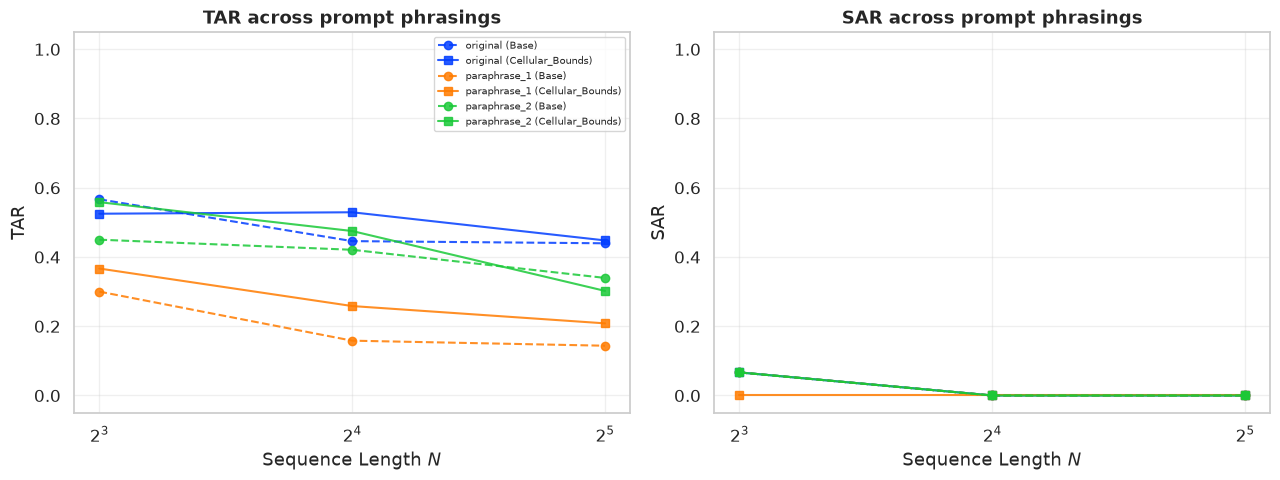


--- TAR GAP (Cellular - Base) BY TEMPLATE ---
    Template  Seq_Length   Base  Cellular_Bounds     Gap
    original           8 0.5667           0.5250 -0.0417
    original          16 0.4458           0.5292  0.0833
    original          32 0.4396           0.4479  0.0083
paraphrase_1           8 0.3000           0.3667  0.0667
paraphrase_1          16 0.1583           0.2583  0.1000
paraphrase_1          32 0.1438           0.2083  0.0646
paraphrase_2           8 0.4500           0.5583  0.1083
paraphrase_2          16 0.4208           0.4750  0.0542
paraphrase_2          32 0.3396           0.3021 -0.0375

Positive gap (boundaries help) in 7/9 (template, N) combinations.


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

robust_df = pd.read_csv(os.path.join(RESULTS_DIR, "prompt_robustness_grid.csv"))
summary = robust_df.groupby(['Template','Method','Seq_Length'])[['TAR','SAR']].mean().reset_index()

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(1, 2, figsize=(13,5))
templates = summary['Template'].unique()
palette = sns.color_palette("bright", n_colors=len(templates))
colors = {t:c for t,c in zip(templates, palette)}

for ax, metric in zip(axes, ['TAR','SAR']):
    for template in templates:
        for method, marker, ls in [('Base','o','--'), ('Cellular_Bounds','s','-')]:
            sub = summary[(summary['Template']==template) & (summary['Method']==method)].sort_values('Seq_Length')
            if len(sub):
                ax.plot(sub['Seq_Length'], sub[metric], marker=marker, linestyle=ls,
                        color=colors[template], label=f'{template} ({method})', alpha=0.85)
    ax.set_xscale('log', base=2)
    ax.set_xlabel('Sequence Length $N$')
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} across prompt phrasings', fontweight='bold')
    ax.set_ylim(-0.05,1.05)
    ax.grid(True, alpha=0.3)

axes[0].legend(fontsize=7, loc='upper right')
plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'prompt_robustness.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"Saved plot to {plot_path}")
plt.show()

gap = summary.pivot_table(index=['Template','Seq_Length'], columns='Method', values='TAR').reset_index()
if 'Base' in gap.columns and 'Cellular_Bounds' in gap.columns:
    gap['Gap'] = gap['Cellular_Bounds'] - gap['Base']
    print("\n--- TAR GAP (Cellular - Base) BY TEMPLATE ---")
    print(gap.round(4).to_string(index=False))
    print(f"\nPositive gap (boundaries help) in {int((gap['Gap']>0).sum())}/{len(gap)} (template, N) combinations.")


# Attention Analysis

In [22]:
import os
import csv
import random
import torch
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# ============================================================
# 1. SETUP
# ============================================================

run_id = 0  # representative example id (see SECTION 3 below)

output_dir = RESULTS_DIR  # from the MODEL SELECTION cell -- results/<MODEL_TAG>/

# Reuses the `model` / `tokenizer` already loaded above -- no reload needed.
# (output_attentions is requested per forward-call below instead of at load
# time; the shared model was loaded with attn_implementation="eager" so
# attentions are actually computable.)
model.eval()

num_layers = model.config.num_hidden_layers
num_heads = model.config.num_attention_heads

# Seed the representative-example prompt draw so it's reproducible.
ATTENTION_SEED = 123
random.seed(ATTENTION_SEED)

# ============================================================
# 2. TASK ENGINE
# ============================================================

class TaskEngine:
    def __init__(self, alphabet_size):
        self.alphabet_size = alphabet_size
        self.alphabet = [chr(ord('A') + i) for i in range(alphabet_size)]

    def generate_paired_prompts(self, length, interval, rng=None):
        rng = rng or random
        raw_chars = rng.choices(self.alphabet, k=length)

        base_str = " ".join(raw_chars)
        prompt_base = f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(self.alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {self.alphabet[-1]} -> {self.alphabet[0]}, and {self.alphabet[0]} -> {self.alphabet[1]}.
Constraint: The input contains vertical bars (|). These are structural boundaries. DO NOT shift them. Copy them exactly to the output.
No spaces, no explanations.

Input: {base_str}
Output: """

        cellular_w_bounds = []
        for i, char in enumerate(raw_chars):
            cellular_w_bounds.append(char)
            if interval > 0 and (i + 1) % interval == 0 and i != length - 1:
                cellular_w_bounds.append("|")

        cell_str = " ".join(cellular_w_bounds)

        prompt_cell = f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(self.alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {self.alphabet[-1]} -> {self.alphabet[0]}, and {self.alphabet[0]} -> {self.alphabet[1]}.
Constraint: The input contains vertical bars (|). These are structural boundaries. DO NOT shift them. Copy them exactly to the output.
No spaces, no explanations.

Input: {cell_str}
Output: """

        return prompt_base, prompt_cell


engine = TaskEngine(alphabet_size=2)
N_length = 16
k_interval = 2
prompt_base, prompt_cell = engine.generate_paired_prompts(
    length=N_length,
    interval=k_interval
)

# ============================================================
# 3. ATTENTION EXTRACTION (FULL TENSOR)
# ============================================================

def extract_all_layers_and_heads(prompt):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    tokens = [tokenizer.decode([t]) for t in inputs.input_ids[0]]

    # Cropping
    try:
        input_idx = next(i for i, t in enumerate(tokens) if 'Input' in t)
        output_idx = next(i for i in range(input_idx, len(tokens)) if 'Output' in tokens[i])

        start_idx = input_idx + 1
        while start_idx < output_idx and tokens[start_idx].strip() in [':', '']:
            start_idx += 1

        end_idx = output_idx
        while end_idx > start_idx and tokens[end_idx - 1].strip() == '':
            end_idx -= 1
    except StopIteration:
        start_idx, end_idx = 0, len(tokens)

    clean_tokens = [t.strip() if t.strip() else '_' for t in tokens[start_idx:end_idx]]

    attentions = outputs.attentions
    seq_len = end_idx - start_idx

    full_tensor = np.zeros(
        (num_layers, num_heads, seq_len, seq_len),
        dtype=np.float32
    )

    for l in range(num_layers):
        layer_attn = attentions[l][0]
        for h in range(num_heads):
            attn_matrix = layer_attn[h].cpu().to(torch.float32).numpy()
            cropped = attn_matrix[start_idx:end_idx, start_idx:end_idx]
            full_tensor[l, h] = cropped

    return full_tensor, clean_tokens


print("\nRunning forward pass for Base Prompt (representative example)...")
attn_base_tensor, tokens_base = extract_all_layers_and_heads(prompt_base)

print("Running forward pass for Cellular Prompt (representative example)...")
attn_cell_tensor, tokens_cell = extract_all_layers_and_heads(prompt_cell)

# ============================================================
# 4. SAVE FULL MATRICES (representative example only -- used by the
#    detailed single-example cells further down: Head Entropy, Network
#    Analysis, Sample Presentation, attention-weight distributions,
#    Correlation Decay)
# ============================================================

print("Saving full attention tensors...")

np.savez_compressed(
    os.path.join(output_dir, f"attention_run_{run_id}.npz"),
    attn_base=attn_base_tensor,
    attn_cell=attn_cell_tensor,
    tokens_base=np.array(tokens_base),
    tokens_cell=np.array(tokens_cell),
    N_length=N_length,
    k_interval=k_interval
)

print("Full tensors saved successfully.\n")

# ============================================================
# 5. MULTI-CONDITION SWEEP (statistics, not just one anecdote)
# ============================================================
# The representative example above is a single (N, k) case. To see whether
# the boundary-sink / entropy effects are systematic -- not an artifact of
# one random draw -- sweep across sequence lengths, boundary intervals, and
# many trials, the same way the "Qwen Scaling" grid search does for
# accuracy. Only scalar metrics (averaged over all layers/heads) are kept
# per condition -- full attention tensors are only saved for the single
# representative example above, to keep storage bounded.

def compute_condition_metrics(attn_base_tensor, attn_cell_tensor, tokens_cell):
    boundary_indices = [i for i, t in enumerate(tokens_cell) if '|' in t]
    eps = 1e-12
    rows = []
    for l in range(num_layers):
        for h in range(num_heads):
            m_base = attn_base_tensor[l, h]
            m_cell = attn_cell_tensor[l, h]

            N_base = m_base.shape[0]
            N_cell = m_cell.shape[0]

            if N_base > 1:
                base_diag = np.mean(np.diag(m_base))
                base_entropy = np.mean(-np.sum(m_base * np.log2(m_base + eps), axis=-1))
                dist_base = np.abs(np.arange(N_base)[:, None] - np.arange(N_base)[None, :]) / N_base
                base_dist = np.mean(np.sum(m_base * dist_base, axis=-1))
            else:
                base_diag = base_entropy = base_dist = 0.0

            if N_cell > 1:
                cell_diag = np.mean(np.diag(m_cell))
                cell_entropy = np.mean(-np.sum(m_cell * np.log2(m_cell + eps), axis=-1))
                dist_cell = np.abs(np.arange(N_cell)[:, None] - np.arange(N_cell)[None, :]) / N_cell
                cell_dist = np.mean(np.sum(m_cell * dist_cell, axis=-1))
                if len(boundary_indices) > 0:
                    cell_boundary = np.mean(np.sum(m_cell[:, boundary_indices], axis=-1))
                else:
                    cell_boundary = 0.0
            else:
                cell_diag = cell_entropy = cell_dist = cell_boundary = 0.0

            rows.append({
                "Base_Diag": base_diag, "Cell_Diag": cell_diag,
                "Base_Entropy": base_entropy, "Cell_Entropy": cell_entropy,
                "Base_Dist": base_dist, "Cell_Dist": cell_dist,
                "Cell_Boundary_Attn": cell_boundary,
            })
    # Average over all (layer, head) pairs -> one summary row per condition
    return pd.DataFrame(rows).mean().to_dict()


# A *fixed* threshold (like the 0.1 the single-example Network Analysis cell
# uses) does not work here: averaging over 28 layers x 28 heads dilutes the
# attention mass, and that dilution gets worse as N grows (a uniform
# attention baseline is already only 1/seq_len). Measured on real examples:
# threshold=0.1 zeroed out 99% of the averaged matrix even at N=16, and any
# *fixed* absolute threshold degenerates back to a near-empty graph again
# once N reaches the hundreds. Instead threshold relative to the uniform-
# attention baseline (1/seq_len) for each matrix -- verified non-degenerate
# (positive edge count, non-zero clustering) from N=8 through N=256.
CLUSTERING_THRESHOLD_MULTIPLIER = 0.5  # threshold = multiplier / seq_len

def compute_condition_clustering(attn_base_tensor, attn_cell_tensor,
                                  multiplier=CLUSTERING_THRESHOLD_MULTIPLIER):
    # Per-(layer,head) clustering for every sweep condition would mean ~28*28
    # graph builds PER condition (~375k total across the full sweep) -- too
    # slow to be worth it. Instead average the attention matrix across all
    # layers/heads into one aggregate network per condition/side, and compute
    # a single clustering coefficient on that. Coarser than the single-example
    # per-layer view in the Network Analysis cell below, but captures the same
    # "does chunking induce more local modularity" question with real N/k
    # statistics instead of one anecdote.
    def clustering_of(m_avg):
        threshold = multiplier / m_avg.shape[0]
        m = m_avg.copy()
        m[m < threshold] = 0.0
        G = nx.from_numpy_array(m, create_using=nx.DiGraph)
        G.remove_edges_from(nx.selfloop_edges(G))  # see the Network Analysis
                                                     # cell for why self-loops
                                                     # must be dropped (NaN fix)
        vals = list(nx.clustering(G, weight='weight').values())
        return np.nanmean(vals) if vals else 0.0

    base_clustering = clustering_of(attn_base_tensor.mean(axis=(0, 1)))
    cell_clustering = clustering_of(attn_cell_tensor.mean(axis=(0, 1)))
    return base_clustering, cell_clustering


SWEEP_SEQUENCE_LENGTHS = [4, 8, 16, 32, 64, 128, 256]
# Runtime note: forward passes stay cheap even at N=256 (measured ~0.05-0.1s
# each on an A100), so the sweep itself is fast (a few minutes). Trim this
# list or SWEEP_TRIALS below if you want a quicker pass.
SWEEP_INTERVALS = [2, 4, 8]   # no 0: a k=0 "cellular" prompt is identical to the base prompt
SWEEP_TRIALS = 20

sweep_conditions = [
    (N, k, t)
    for N in SWEEP_SEQUENCE_LENGTHS
    for k in SWEEP_INTERVALS
    for t in range(SWEEP_TRIALS)
    if k < N
]
print(f"\nStarting attention sweep: {len(sweep_conditions)} conditions "
      f"({len(sweep_conditions) * 2} forward passes)...")

sweep_rows = []
for (N, k, t) in tqdm(sweep_conditions, desc="Attention sweep"):
    # Independent, deterministic seed per condition -- does not disturb the
    # global `random` state used for the representative example above.
    local_seed = 50_000 * N + 100 * k + t
    rng = random.Random(local_seed)

    p_base, p_cell = engine.generate_paired_prompts(length=N, interval=k, rng=rng)
    ab, _ = extract_all_layers_and_heads(p_base)
    ac, tc = extract_all_layers_and_heads(p_cell)

    m = compute_condition_metrics(ab, ac, tc)
    m["Delta_Diag"] = m["Cell_Diag"] - m["Base_Diag"]
    m["Delta_Entropy"] = m["Cell_Entropy"] - m["Base_Entropy"]
    m["Delta_Dist"] = m["Cell_Dist"] - m["Base_Dist"]
    m["Base_Clustering"], m["Cell_Clustering"] = compute_condition_clustering(ab, ac)
    m["Delta_Clustering"] = m["Cell_Clustering"] - m["Base_Clustering"]
    m.update(Seq_Length=N, Interval=k, Trial=t)
    sweep_rows.append(m)

sweep_df = pd.DataFrame(sweep_rows)
sweep_df["Inv_K"] = 1.0 / sweep_df["Interval"]

csv_filename = os.path.join(output_dir, "attention_metrics.csv")
sweep_df.to_csv(csv_filename, index=False)
print(f"\nAttention sweep complete. Saved {len(sweep_df)} condition-level rows to '{csv_filename}'")

summary = (
    sweep_df.groupby(["Seq_Length", "Interval"])[["Cell_Boundary_Attn", "Delta_Entropy", "Delta_Diag"]]
            .mean()
            .reset_index()
)
print("\n--- MEAN ATTENTION METRICS BY (Seq_Length, Interval) ---")
print(summary.to_string(index=False))

# ============================================================
# 6. HEATMAP GENERATION (representative example only, commented out)
# ============================================================

# print("Generating heatmaps...")

# for l in tqdm(range(num_layers), desc="Layers"):
#     for h in range(num_heads):

#         m_base = attn_base_tensor[l, h]
#         m_cell = attn_cell_tensor[l, h]

#         fig, (ax1, ax2, cbar_ax) = plt.subplots(
#             1, 3, figsize=(18, 7),
#             gridspec_kw={'width_ratios': [1, 1, 0.05]}
#         )

#         sns.heatmap(
#             m_base,
#             xticklabels=tokens_base,
#             yticklabels=tokens_base,
#             cmap="rocket",
#             ax=ax1,
#             cbar=False,
#             vmin=0,
#             vmax=1
#         )

#         ax1.set_title(f"Base | Layer {l}, Head {h}")
#         ax1.set_aspect('equal')

#         sns.heatmap(
#             m_cell,
#             xticklabels=tokens_cell,
#             yticklabels=tokens_cell,
#             cmap="rocket",
#             ax=ax2,
#             cbar_ax=cbar_ax,
#             vmin=0,
#             vmax=1
#         )

#         ax2.set_title(f"Cellular | Layer {l}, Head {h}")
#         ax2.set_aspect('equal')

#         if len(boundary_indices) > 0:
#             for b in boundary_indices:
#                 ax2.axvline(x=b, color='cyan', linestyle='--', linewidth=1)
#                 ax2.axhline(y=b, color='cyan', linestyle='--', linewidth=1)

#         plt.tight_layout()

#         filename = os.path.join(
#             output_dir,
#             f"layer_{l:02d}_head_{h:02d}.png"
#         )
#         plt.savefig(filename, dpi=100)
#         plt.close(fig)

# print("Done.")


Running forward pass for Base Prompt (representative example)...
Running forward pass for Cellular Prompt (representative example)...
Saving full attention tensors...


Full tensors saved successfully.


Starting attention sweep: 360 conditions (720 forward passes)...


Attention sweep:   0%|          | 0/360 [00:00<?, ?it/s]

Attention sweep:   0%|          | 1/360 [00:00<01:19,  4.50it/s]

Attention sweep:   1%|          | 2/360 [00:00<01:18,  4.57it/s]

...

Attention sweep:  99%|█████████▉| 358/360 [07:35<00:07,  3.85s/it]

Attention sweep: 100%|█████████▉| 359/360 [07:39<00:03,  3.85s/it]

Attention sweep: 100%|██████████| 360/360 [07:43<00:00,  3.85s/it]

Attention sweep: 100%|██████████| 360/360 [07:43<00:00,  1.29s/it]


Attention sweep complete. Saved 360 condition-level rows to 'results/Mistral-7B-Instruct-v0.3/attention_metrics.csv'

--- MEAN ATTENTION METRICS BY (Seq_Length, Interval) ---
 Seq_Length  Interval  Cell_Boundary_Attn  Delta_Entropy  Delta_Diag
          4         2            0.047069       0.073337    0.002133
          8         2            0.079075       0.107306    0.000598
          8         4            0.036523       0.042901    0.003355
         16         2            0.103588       0.130015    0.000335
         16         4            0.061286       0.061990    0.005128
         16         8            0.028651       0.028231    0.003551
         32         2            0.118278       0.136140   -0.000272
         32         4            0.081061       0.071299    0.005497
         32         8            0.046865       0.027003    0.005001
         64         2            0.127209       0.157575   -0.000716
         64         4            0.092907       0.096220    0.005

In [23]:
import shutil
import os

# The 'results' folder you saw when running 'ls'
source_dir = "results"
# The name of the zip file you want to create
zip_name = "my_attention_results"

if os.path.exists(source_dir):
    # This creates 'my_attention_results.zip'
    shutil.make_archive(zip_name, 'zip', source_dir)
    print(f"✅ Successfully created {zip_name}.zip")
else:
    print(f"❌ Error: The folder '{source_dir}' was not found in this directory.")

✅ Successfully created my_attention_results.zip


# Boudery Sink Analysis

Loaded 360 sweep conditions from 'results/Mistral-7B-Instruct-v0.3/attention_metrics.csv'
   Seq_Length  Interval  Trial  Cell_Boundary_Attn  Delta_Entropy  Delta_Diag
0           4         2      0            0.049961       0.071663    0.000953
1           4         2      1            0.044754       0.071863    0.001705
2           4         2      2            0.045032       0.063458    0.000973
3           4         2      3            0.046912       0.079168    0.004222
4           4         2      4            0.045032       0.063458    0.000973
5           4         2      5            0.048793       0.080126    0.003292
6           4         2      6            0.046912       0.079168    0.004222
7           4         2      7            0.047931       0.078032    0.002387
8           4         2      8            0.045892       0.068747    0.000832
9           4         2      9            0.044754       0.071863    0.001705

--- OVERALL (across all conditions) ---
      Cell_

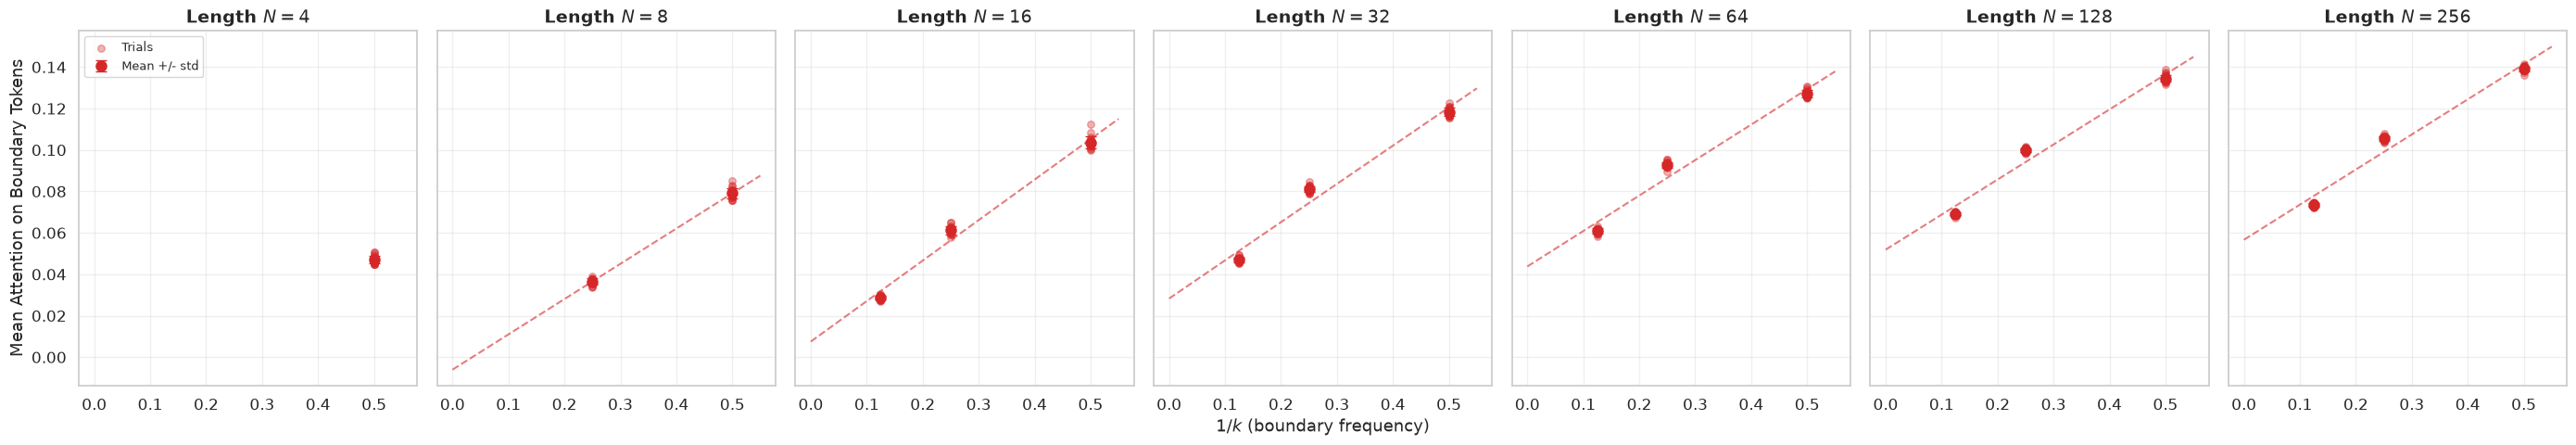


--- BOUNDARY-SINK REGRESSION (Cell_Boundary_Attn ~ Inv_K, by Seq_Length) ---
 Seq_Length  Slope  Intercept  R_squared  P_value
          8 0.1702    -0.0060     0.9913      0.0
         16 0.1955     0.0075     0.9823      0.0
         32 0.1845     0.0283     0.9700      0.0
         64 0.1711     0.0438     0.9688      0.0
        128 0.1692     0.0519     0.9741      0.0
        256 0.1694     0.0566     0.9675      0.0

--- MEAN DELTA (Cellular - Base) BY (Seq_Length, Interval) ---
 Seq_Length  Interval  Delta_Entropy  Delta_Diag  Delta_Dist
          4         2       0.073337    0.002133    0.007405
          8         2       0.107306    0.000598    0.005239
          8         4       0.042901    0.003355    0.001424
         16         2       0.130015    0.000335    0.004522
         16         4       0.061990    0.005128   -0.000362
         16         8       0.028231    0.003551   -0.000749
         32         2       0.136140   -0.000272    0.002720
         32         

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import seaborn as sns
import os

# ============================================================
# BOUNDARY SINK ANALYSIS (statistical, across the attention sweep)
# ============================================================
# attention_metrics.csv now holds one row per (Seq_Length, Interval, Trial)
# condition from the sweep in the Attention Analysis setup cell -- not a
# single snapshot. Cell_Boundary_Attn is the average attention mass (across
# all layers/heads) that lands on the "|" boundary tokens; if boundaries
# act as attention sinks, this should be systematically elevated, and grow
# as boundaries get more frequent (larger Inv_K = 1/Interval).

csv_filename = os.path.join(RESULTS_DIR, "attention_metrics.csv")
df = pd.read_csv(csv_filename)

print(f"Loaded {len(df)} sweep conditions from '{csv_filename}'")
print(df[["Seq_Length", "Interval", "Trial", "Cell_Boundary_Attn", "Delta_Entropy", "Delta_Diag"]].head(10))

# --- Overall summary ---
print("\n--- OVERALL (across all conditions) ---")
print(df[["Cell_Boundary_Attn", "Delta_Entropy", "Delta_Diag", "Delta_Dist"]].agg(["mean", "std"]))

# --- Plot: Boundary attention vs 1/k, faceted by sequence length ---
seq_lengths = sorted(df["Seq_Length"].unique())
num_lengths = len(seq_lengths)

sns.set_theme(style="whitegrid", font_scale=1.1)

if num_lengths == 1:
    fig, axes = plt.subplots(1, 1, figsize=(6, 5))
    axes = [axes]
else:
    fig, axes = plt.subplots(1, num_lengths, figsize=(4 * num_lengths, 5), sharex=True, sharey=True)

regression_results = []

for i, N in enumerate(seq_lengths):
    ax = axes[i]
    sub_N = df[df["Seq_Length"] == N]

    # Per-(Interval) mean +/- std across trials, then regress the trial-level points
    summary_N = sub_N.groupby("Inv_K")["Cell_Boundary_Attn"].agg(["mean", "std"]).reset_index()

    ax.scatter(sub_N["Inv_K"], sub_N["Cell_Boundary_Attn"], color="tab:red", alpha=0.35, s=30, label="Trials")
    ax.errorbar(summary_N["Inv_K"], summary_N["mean"], yerr=summary_N["std"],
                fmt="o", color="tab:red", markersize=8, capsize=4, label="Mean +/- std")

    if sub_N["Inv_K"].nunique() >= 2:
        slope, intercept, r_value, p_value, std_err = linregress(sub_N["Inv_K"], sub_N["Cell_Boundary_Attn"])
        regression_results.append({
            "Seq_Length": N, "Slope": slope, "Intercept": intercept,
            "R_squared": r_value ** 2, "P_value": p_value,
        })
        x_fit = np.linspace(0, sub_N["Inv_K"].max() * 1.1, 100)
        y_fit = slope * x_fit + intercept
        ax.plot(x_fit, y_fit, linestyle="--", color="tab:red", alpha=0.6, linewidth=1.5)

    ax.set_title(f"Length $N = {N}$", fontsize=14, fontweight="bold")
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.set_ylabel("Mean Attention on Boundary Tokens", fontsize=13)
    if i == num_lengths // 2:
        ax.set_xlabel("$1/k$ (boundary frequency)", fontsize=13)

axes[0].legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "boundary_sink_analysis.png"), bbox_inches="tight", dpi=300)
plt.show()

print("\n--- BOUNDARY-SINK REGRESSION (Cell_Boundary_Attn ~ Inv_K, by Seq_Length) ---")
print(pd.DataFrame(regression_results).round(4).to_string(index=False))

# --- Does chunking also change entropy/diagonal focus, beyond the boundary tokens themselves? ---
delta_summary = (
    df.groupby(["Seq_Length", "Interval"])[["Delta_Entropy", "Delta_Diag", "Delta_Dist"]]
      .mean()
      .reset_index()
      .sort_values(["Seq_Length", "Interval"])
)
print("\n--- MEAN DELTA (Cellular - Base) BY (Seq_Length, Interval) ---")
print(delta_summary.to_string(index=False))

# Head Entropy

Base shape: (32, 32, 16, 16)
Cell shape: (32, 32, 23, 23)
Number of alphabetic tokens in Cellular: 16


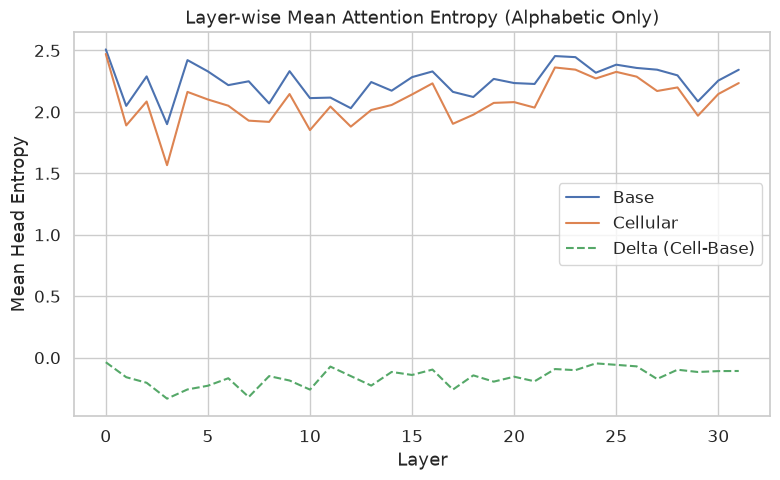

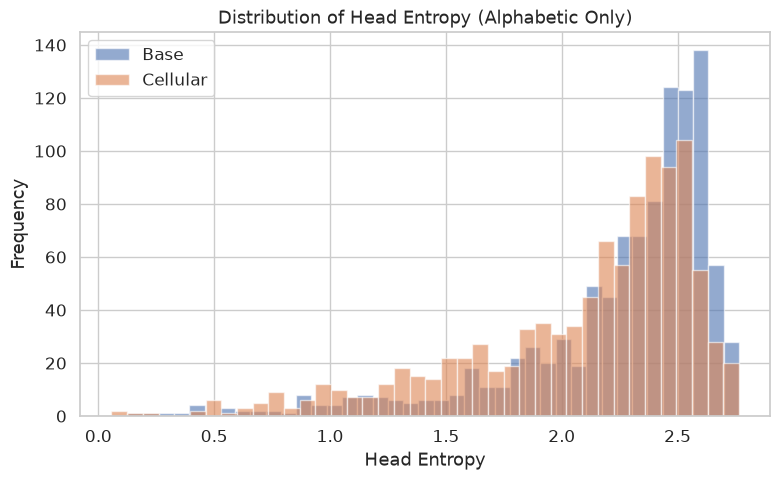

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# 1. LOAD DATA
# ============================================================

data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = data["tokens_base"]
tokens_cell = data["tokens_cell"]

num_layers, num_heads = attn_base.shape[:2]

print("Base shape:", attn_base.shape)
print("Cell shape:", attn_cell.shape)

# ============================================================
# 2. MASK BOUNDARIES and All Zero Heads
# ============================================================

# Create a mask to ignore '|' tokens
mask_cell = np.array([t != '|' for t in tokens_cell])

# Apply mask: crop both rows and columns to alphabetic tokens only
attn_cell_masked = attn_cell[:, :, mask_cell, :][:, :, :, mask_cell]
# Reverse Mask
#attn_cell_masked = attn_cell
print("Number of alphabetic tokens in Cellular:", mask_cell.sum())

# ============================================================
# 3. ENTROPY FUNCTION
# ============================================================
def compute_head_entropy(attn_tensor, ignore=None):
    """
    Returns entropy per (layer, head)
    Output shape: (layers, heads)

    ignore: tuple (layer_index, head_index) to skip, e.g., (27, 10)
    """
    eps = 1e-12
    L, H = attn_tensor.shape[:2]
    entropy_matrix = np.zeros((L, H))

    for l in range(L):
        for h in range(H):
            if ignore is not None and (l, h) == ignore:
                entropy_matrix[l, h] = np.nan
                continue

            m = attn_tensor[l, h]  # (N, N)
            
            # Normalize each row to sum to 1
            row_sums = m.sum(axis=-1, keepdims=True)
            m_norm = m / (row_sums + eps)  # avoid division by zero

            # Compute entropy per row
            row_entropy = -np.sum(m_norm * np.log2(m_norm + eps), axis=-1)
            
            # Average over rows to get head-level entropy
            entropy_matrix[l, h] = np.mean(row_entropy)

    return entropy_matrix
    
# ============================================================
# 4. COMPUTE ENTROPY (with ignored head)
# ============================================================

ignore_layer_head = (1, 1)  # 0-based indexing
ignore_layer_head = None

entropy_base = compute_head_entropy(attn_base, ignore=ignore_layer_head)          
entropy_cell = compute_head_entropy(attn_cell_masked, ignore=ignore_layer_head)

# Compute delta, ignoring the ignored head
delta_entropy = entropy_cell - entropy_base

# ============================================================
# 6. VISUALIZATION 2: LAYER-WISE MEAN ENTROPY
# ============================================================

layer_mean_base = np.mean(entropy_base, axis=1)
layer_mean_cell = np.mean(entropy_cell, axis=1)
layer_mean_delta = np.mean(delta_entropy, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(layer_mean_base, label="Base")
plt.plot(layer_mean_cell, label="Cellular")
plt.plot(layer_mean_delta, label="Delta (Cell-Base)", linestyle="--")
plt.xlabel("Layer")
plt.ylabel("Mean Head Entropy")
plt.title("Layer-wise Mean Attention Entropy (Alphabetic Only)")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 7. VISUALIZATION 3: ENTROPY DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))
plt.hist(entropy_base.flatten(), bins=40, alpha=0.6, label="Base")
plt.hist(entropy_cell.flatten(), bins=40, alpha=0.6, label="Cellular")
plt.xlabel("Head Entropy")
plt.ylabel("Frequency")
plt.title("Distribution of Head Entropy (Alphabetic Only)")
plt.legend()
plt.tight_layout()

plt.show()

In [26]:
def get_top_n_stats(entropy_matrix, n=5):
    # Flatten and get indices of sorted values
    flat_indices = np.argsort(entropy_matrix, axis=None)
    
    # Lowest Entropy (First N)
    lowest_indices = flat_indices[:n]
    # Highest Entropy (Last N, reversed to show highest first)
    highest_indices = flat_indices[-n:][::-1]
    
    def extract_info(indices):
        info = []
        for idx in indices:
            l, h = np.unravel_index(idx, entropy_matrix.shape)
            info.append((l, h, entropy_matrix[l, h]))
        return info

    return extract_info(highest_indices), extract_info(lowest_indices)

# Execute for both models
base_high, base_low = get_top_n_stats(entropy_base)
cell_high, cell_low = get_top_n_stats(entropy_cell)

# ============================================================
# RESULTS SUMMARY
# ============================================================

def print_top_n(name, high, low):
    print(f"\n{'='*20} {name} MODEL {'='*20}")
    print("TOP 5 HIGHEST ENTROPY (Broad/Global Attention):")
    for i, (l, h, v) in enumerate(high, 1):
        print(f"  {i}. Layer {l:2d}, Head {h:2d} | Entropy: {v:.4f}")
    
    print("\nTOP 5 LOWEST ENTROPY (Sharp/Specialized Attention):")
    for i, (l, h, v) in enumerate(low, 1):
        print(f"  {i}. Layer {l:2d}, Head {h:2d} | Entropy: {v:.4f}")

print_top_n("BASE", base_high, base_low)
print_top_n("CELLULAR", cell_high, cell_low)

# ============================================================
# 8. COMPUTE AND RANK ENTROPY SHIFT
# ============================================================

# Calculate the signed difference
# Positive delta = Cellular is more diffuse (higher entropy)
# Negative delta = Cellular is more focused (lower entropy)
delta_entropy = entropy_cell - entropy_base

# We rank by absolute magnitude to see the biggest changes regardless of direction
flat_delta_abs = np.abs(delta_entropy).flatten()
top_shift_indices = np.argsort(flat_delta_abs)[-5:][::-1]

print(f"\n{'='*20} TOP 5 ENTROPY SHIFTS {'='*20}")
print(f"{'Rank':<5} | {'Layer':<6} | {'Head':<5} | {'Base':<8} | {'Cell':<8} | {'Shift':<8}")
print("-" * 60)

for i, idx in enumerate(top_shift_indices, 1):
    l, h = np.unravel_index(idx, delta_entropy.shape)
    base_val = entropy_base[l, h]
    cell_val = entropy_cell[l, h]
    shift = delta_entropy[l, h]
    
    direction = "📈 (More Broad)" if shift > 0 else "📉 (More Focused)"
    print(f"{i:<5} | {l:<6} | {h:<5} | {base_val:<8.4f} | {cell_val:<8.4f} | {shift:<+8.4f} {direction}")


==================== BASE MODEL ====================
TOP 5 HIGHEST ENTROPY (Broad/Global Attention):
  1. Layer  0, Head 17 | Entropy: 2.7652
  2. Layer  0, Head  6 | Entropy: 2.7639
  3. Layer  0, Head  5 | Entropy: 2.7629
  4. Layer  0, Head 15 | Entropy: 2.7611
  5. Layer  0, Head 19 | Entropy: 2.7599

TOP 5 LOWEST ENTROPY (Sharp/Specialized Attention):
  1. Layer 14, Head 14 | Entropy: 0.1287
  2. Layer 29, Head  4 | Entropy: 0.2245
  3. Layer 29, Head  7 | Entropy: 0.3134
  4. Layer 11, Head 17 | Entropy: 0.3779
  5. Layer  3, Head 15 | Entropy: 0.4397

==================== CELLULAR MODEL ====================
TOP 5 HIGHEST ENTROPY (Broad/Global Attention):
  1. Layer  0, Head 17 | Entropy: 2.7652
  2. Layer  0, Head  6 | Entropy: 2.7639
  3. Layer  0, Head  5 | Entropy: 2.7628
  4. Layer  0, Head 15 | Entropy: 2.7615
  5. Layer  0, Head 19 | Entropy: 2.7593

TOP 5 LOWEST ENTROPY (Sharp/Specialized Attention):
  1. Layer 14, Head 14 | Entropy: 0.0566
  2. Layer 29, Head  4 | Entro

# Network Analysis

Loading attention tensors...
Computing network topologies with threshold 0.1...


Processing Layers:   0%|          | 0/32 [00:00<?, ?it/s]

Processing Layers:  31%|███▏      | 10/32 [00:00<00:00, 92.01it/s]

Processing Layers:  62%|██████▎   | 20/32 [00:00<00:00, 67.48it/s]

Processing Layers:  94%|█████████▍| 30/32 [00:00<00:00, 79.04it/s]

Processing Layers: 100%|██████████| 32/32 [00:00<00:00, 75.54it/s]


Saved topology analysis plot to results/Mistral-7B-Instruct-v0.3/topology_clustering_analysis.png


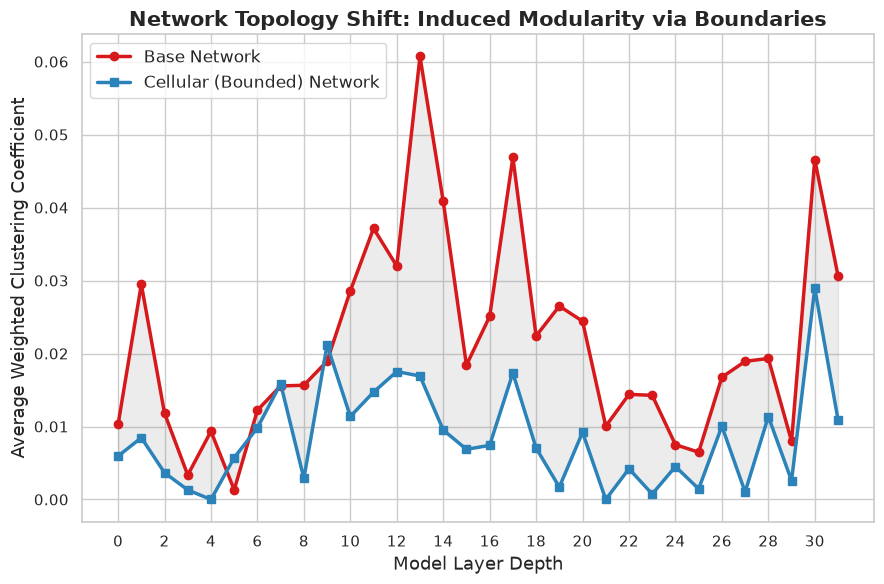

Global Average Clustering (Base): 0.0214
Global Average Clustering (Cell): 0.0084


In [27]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import os
from tqdm import tqdm

# ============================================================
# 1. LOAD DATA
# ============================================================
print("Loading attention tensors...")
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = data["tokens_base"]
tokens_cell = data["tokens_cell"]

# ============================================================
# 2. MASK BOUNDARIES and All Zero Heads
# ============================================================

# Create a mask to ignore '|' tokens
mask_cell = np.array([t != '|' for t in tokens_cell])

# Apply mask: crop both rows and columns to alphabetic tokens only
attn_cell_masked = attn_cell[:, :, mask_cell, :][:, :, :, mask_cell]
# Reverse Mask
#attn_cell_masked = attn_cell

num_layers, num_heads = attn_base.shape[:2]

# ============================================================
# 2. COMPUTE CLUSTERING COEFFICIENT (NETWORK TOPOLOGY)
# ============================================================
# We treat each attention matrix as a weighted, directed adjacency matrix.
# The clustering coefficient measures the degree to which nodes in a graph tend to cluster together.

# ============================================================
# 2. COMPUTE CLUSTERING COEFFICIENT (NETWORK TOPOLOGY)
# ============================================================

base_clustering_layers = np.zeros(num_layers)
cell_clustering_layers = np.zeros(num_layers)

# Define your threshold (e.g., 0.01 means ignore weights under 1%)
THRESHOLD = 0.1 

print(f"Computing network topologies with threshold {THRESHOLD}...")
for l in tqdm(range(num_layers), desc="Processing Layers"):
    base_head_cluster = []
    cell_head_cluster = []
    
    for h in range(num_heads):
        # --- Base Network ---
        m_base = attn_base[l, h].copy()
        # Apply Threshold: Zero out weak connections
        m_base[m_base < THRESHOLD] = 0.0
        
        # Create a directed graph from the thresholded matrix
        G_base = nx.from_numpy_array(m_base, create_using=nx.DiGraph)
        # Drop self-attention edges (the diagonal) before computing clustering:
        # nx's directed weighted clustering coefficient divides by a term built
        # from each node's self-loop weight, so a node whose only strong edge
        # is its own diagonal entry (very common post-threshold) hits 0/0 -> NaN.
        # Self-attention isn't meaningful for "clustering with other tokens" anyway.
        G_base.remove_edges_from(nx.selfloop_edges(G_base))
        base_vals = list(nx.clustering(G_base, weight='weight').values())
        c_base = np.nanmean(base_vals) if base_vals else 0.0
        base_head_cluster.append(c_base)
        
        # --- Cellular (Boundary) Network ---
        m_cell = attn_cell_masked[l, h].copy()
        # Apply Threshold: Zero out weak connections
        m_cell[m_cell < THRESHOLD] = 0.0
        
        G_cell = nx.from_numpy_array(m_cell, create_using=nx.DiGraph)
        G_cell.remove_edges_from(nx.selfloop_edges(G_cell))
        cell_vals = list(nx.clustering(G_cell, weight='weight').values())
        c_cell = np.nanmean(cell_vals) if cell_vals else 0.0
        cell_head_cluster.append(c_cell)
        
    base_clustering_layers[l] = np.nanmean(base_head_cluster)
    cell_clustering_layers[l] = np.nanmean(cell_head_cluster)


# ============================================================
# 3. VISUALIZATION
# ============================================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 6))

plt.plot(range(num_layers), base_clustering_layers, label="Base Network", 
         marker='o', markersize=6, linewidth=2.5, color='#d7191c')
plt.plot(range(num_layers), cell_clustering_layers, label="Cellular (Bounded) Network", 
         marker='s', markersize=6, linewidth=2.5, color='#2b83ba')

# Fill the gap to emphasize the difference
plt.fill_between(range(num_layers), base_clustering_layers, cell_clustering_layers, 
                 color='gray', alpha=0.15)

plt.xlabel("Model Layer Depth", fontsize=13)
plt.ylabel("Average Weighted Clustering Coefficient", fontsize=13)
plt.title("Network Topology Shift: Induced Modularity via Boundaries", fontsize=15, fontweight='bold')
plt.xticks(range(0, num_layers, 2))
plt.legend(fontsize=12, loc='upper left')

plot_filename = os.path.join(RESULTS_DIR, "topology_clustering_analysis.png")
plt.tight_layout()
plt.savefig(plot_filename, dpi=300)
print(f"\nSaved topology analysis plot to {plot_filename}")
plt.show()

# Print global averages
print(f"Global Average Clustering (Base): {np.nanmean(base_clustering_layers):.4f}")
print(f"Global Average Clustering (Cell): {np.nanmean(cell_clustering_layers):.4f}")

# Sample Presentation 

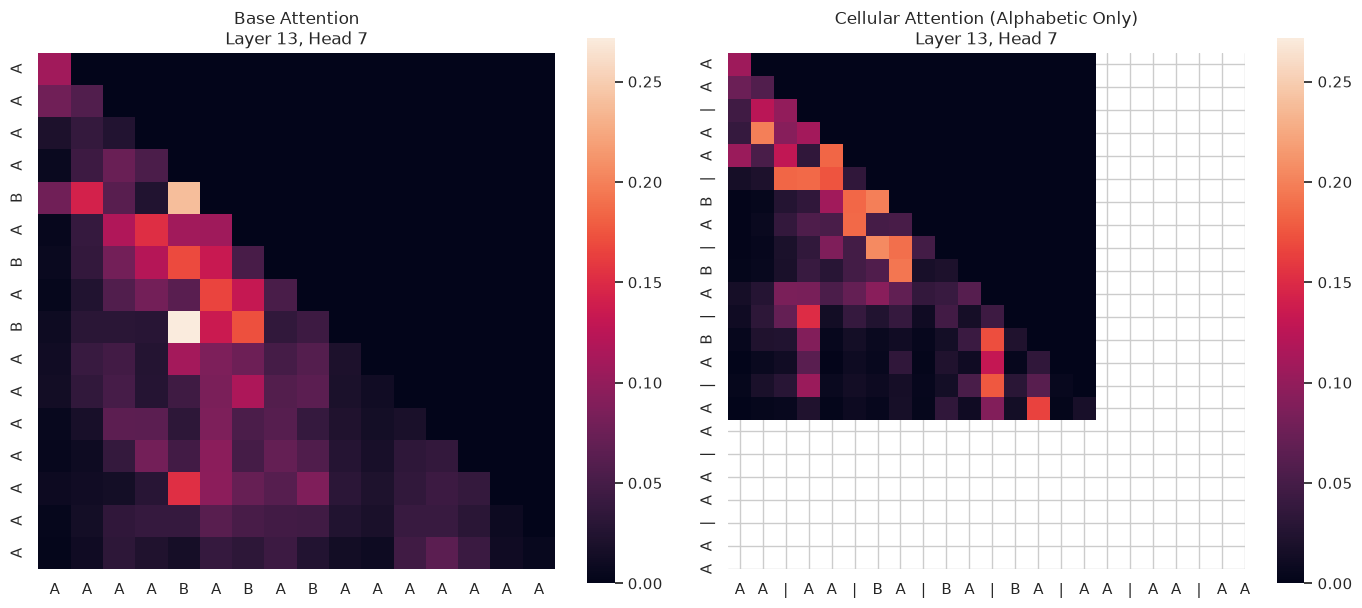

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Load data ---
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = data["tokens_base"]
tokens_cell = data["tokens_cell"]

# --- Mask boundaries for cellular ---
mask_cell = np.array([t != '|' for t in tokens_cell])
attn_cell_masked = attn_cell[:, :, mask_cell, :][:, :, :, mask_cell].copy()

tokens_cell_masked = np.array(tokens_cell)[mask_cell]

# Reverse Mask
#attn_cell_masked = attn_cell
tokens_cell_masked = tokens_cell

# --- Layer and Head to visualize ---
layer_idx = 13
head_idx = 7

m_base = attn_base[layer_idx, head_idx]
m_cell = attn_cell_masked[layer_idx, head_idx]

tokens_base_list = tokens_base
tokens_cell_list = tokens_cell_masked

vmax_shared = max(np.max(m_base), np.max(m_cell))

# --- Plot ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Base
sns.heatmap(
    m_base,
    xticklabels=tokens_base_list,
    yticklabels=tokens_base_list,
    cmap="rocket",
    vmin=0, vmax=vmax_shared,
    ax=ax1
)
ax1.set_title(f"Base Attention\nLayer {layer_idx}, Head {head_idx}", fontsize=12)
ax1.set_aspect('equal')

# Cellular (alphabetic only)
sns.heatmap(
    m_cell,
    xticklabels=tokens_cell_list,
    yticklabels=tokens_cell_list,
    cmap="rocket",
    vmin=0, vmax=vmax_shared,
    ax=ax2
)
ax2.set_title(f"Cellular Attention (Alphabetic Only)\nLayer {layer_idx}, Head {head_idx}", fontsize=12)
ax2.set_aspect('equal')

plt.tight_layout()
plt.savefig("example.png",dpi=300)
plt.show()

# OFF-Attention Weght Prob Distrition 

Mean Base context mass: 0.2024816232663511
Mean Cellular context mass: 0.1349839350124915
Mean Δ: -0.0674976882538596


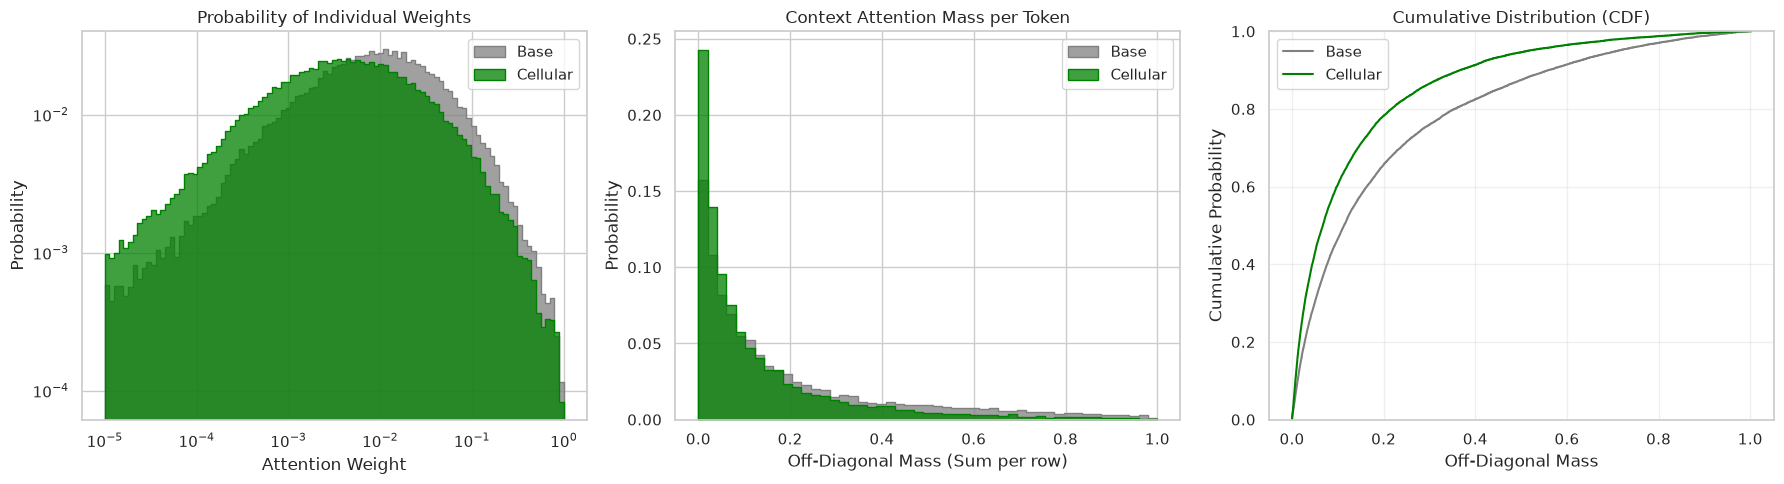

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# LOAD DATA
# ============================================================

data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = data["tokens_base"]
tokens_cell = data["tokens_cell"]

# ============================================================
# MASK CELLULAR BOUNDARY TOKENS
# ============================================================

mask_cell = np.array([t != '|' for t in tokens_cell])

attn_cell_masked = attn_cell[:, :, mask_cell, :][:, :, :, mask_cell].copy()
tokens_cell_masked = np.array(tokens_cell)[mask_cell]

#attn_cell_masked = attn_cell
tokens_cell_masked = tokens_cell

# ============================================================
# FUNCTIONS
# ============================================================

def offdiag_fraction(attn_tensor):
    """
    Mean off-diagonal mass per (layer, head)
    """
    L, H = attn_tensor.shape[:2]
    frac = np.zeros((L, H))

    for l in range(L):
        for h in range(H):
            m = attn_tensor[l, h]
            off = np.tril(m, k=-1).sum(axis=1)
            frac[l, h] = off[1:].mean()

    return frac


def offdiag_values(attn_tensor):
    """
    Collects all individual off-diagonal attention weights
    """
    L, H = attn_tensor.shape[:2]
    vals = []

    for l in range(L):
        for h in range(H):
            m = attn_tensor[l, h]
            N = m.shape[0]

            for i in range(N):
                off = np.delete(m[i, :], i)
                vals.extend(off)

    return np.array(vals)


def offdiag_mass_per_row(attn_tensor):
    """
    Total off-diagonal mass per token
    """
    L, H = attn_tensor.shape[:2]
    vals = []

    for l in range(L):
        for h in range(H):
            m = attn_tensor[l, h]
            off = np.tril(m, k=-1).sum(axis=1)
            vals.extend(off[1:])  # skip first token

    return np.array(vals)


# ============================================================
# COMPUTE METRICS
# ============================================================

ratio_base = offdiag_fraction(attn_base)
ratio_cell = offdiag_fraction(attn_cell_masked)

delta_ratio = ratio_cell - ratio_base

print("Mean Base context mass:", np.mean(ratio_base))
print("Mean Cellular context mass:", np.mean(ratio_cell))
print("Mean Δ:", np.mean(delta_ratio))


off_base_vals = offdiag_values(attn_base)
off_cell_vals = offdiag_values(attn_cell_masked)

off_base_mass = offdiag_mass_per_row(attn_base)
off_cell_mass = offdiag_mass_per_row(attn_cell_masked)

# PLOTS
# ============================================================

# We will create 3 plots: Weight Prob, Mass Prob, and Mass CDF
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ------------------------------------------------------------
# 1. Probability of Individual Weights (Log Scale)
# ------------------------------------------------------------
bins_log = np.logspace(-5, 0, 100)

for data, label, color in [(off_base_vals, "Base", "gray"), (off_cell_vals, "Cellular", "green")]:
    sns.histplot(
        data,
        bins=bins_log,
        stat="probability",  # Changed from density
        element="step",
        label=label,
        color=color,
        ax=axes[0]
    )

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Probability of Individual Weights")
axes[0].set_xlabel("Attention Weight")
axes[0].set_ylabel("Probability")
axes[0].legend()

# ------------------------------------------------------------
# 2. Probability of Context Mass per Token
# ------------------------------------------------------------
bins_lin = np.linspace(0, 1, 50)

for data, label, color in [(off_base_mass, "Base", "gray"), (off_cell_mass, "Cellular", "green")]:
    sns.histplot(
        data,
        bins=bins_lin,
        stat="probability",  # Changed from density
        element="step",
        label=label,
        color=color,
        ax=axes[1]
    )

axes[1].set_title("Context Attention Mass per Token")
axes[1].set_xlabel("Off-Diagonal Mass (Sum per row)")
axes[1].set_ylabel("Probability")
axes[1].legend()

# ------------------------------------------------------------
# 3. Cumulative Distribution (CDF) of Mass
# ------------------------------------------------------------
# This shows: "What % of tokens have at least X amount of context mass?"
sns.ecdfplot(off_base_mass, label="Base", color="gray", ax=axes[2])
sns.ecdfplot(off_cell_mass, label="Cellular", color="green", ax=axes[2])

axes[2].set_title("Cumulative Distribution (CDF)")
axes[2].set_xlabel("Off-Diagonal Mass")
axes[2].set_ylabel("Cumulative Probability")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("off_diagonal_probability.png", dpi=300)
plt.show()

# Diagonal-Attention Weght Prob Distrition 

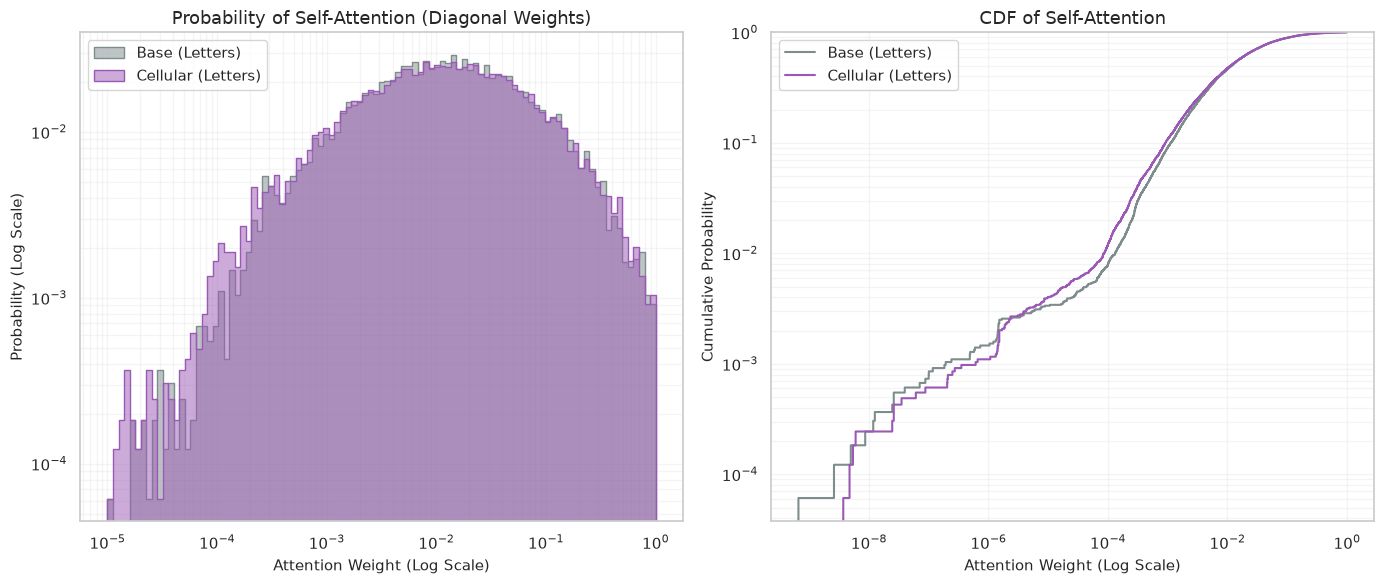

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# ============================================================
# LOAD DATA
# ============================================================
# Use the original 4D tensors (Layers, Heads, Seq, Seq)
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)
attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = np.array(data["tokens_base"])
tokens_cell = np.array(data["tokens_cell"])

# ============================================================
# DATA EXTRACTION (Diagonal Elements)
# ============================================================

def get_diagonal_elements(attn_tensor, tokens):
    """
    Extracts diagonal values for all layers/heads, excluding dividers.
    Supports 4D (L,H,N,N) tensors.
    """
    L, H, N, _ = attn_tensor.shape
    diag_vals = []
    
    # Identify non-divider indices
    alpha_indices = np.where(np.array(tokens) != '|')[0]

    for l in range(L):
        for h in range(H):
            m = attn_tensor[l, h]
            d = np.diag(m)  # Get the full diagonal
            # Filter out dividers
            alpha_diags = d[alpha_indices]
            diag_vals.extend(alpha_diags)
            
    return np.array(diag_vals)

# Compute values
# We use the raw 4D data to ensure we have the full distribution across all heads
diag_base = get_diagonal_elements(attn_base, tokens_base)
diag_cell = get_diagonal_elements(attn_cell, tokens_cell)

# ============================================================
# PLOTS (Probability with Log Scale)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define bins in log space for the X-axis
# We look at weights from 0.00001 up to 1.0
bins_log = np.logspace(-5, 0, 100)

# ------------------------------------------------------------
# 1. Probability Distribution (PDF) with Log Scale
# ------------------------------------------------------------
sns.histplot(
    diag_base,
    bins=bins_log,
    stat="probability",
    element="step",
    label="Base (Letters)",
    color="#7f8c8d", # Grey
    alpha=0.5,
    ax=axes[0]
)

sns.histplot(
    diag_cell,
    bins=bins_log,
    stat="probability",
    element="step",
    label="Cellular (Letters)",
    color="#9b59b6", # Purple
    alpha=0.5,
    ax=axes[0]
)

axes[0].set_xscale("log")
# We also log the Y-axis to see the differences in extremely low/high probability regions
axes[0].set_yscale("log") 

axes[0].set_title("Probability of Self-Attention (Diagonal Weights)", fontsize=13)
axes[0].set_xlabel("Attention Weight (Log Scale)", fontsize=11)
axes[0].set_ylabel("Probability (Log Scale)", fontsize=11)
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.2)

# ------------------------------------------------------------
# 2. Cumulative Distribution (CDF) with Log Scale X-axis
# ------------------------------------------------------------
sns.ecdfplot(diag_base, label="Base (Letters)", color="#7f8c8d", ax=axes[1])
sns.ecdfplot(diag_cell, label="Cellular (Letters)", color="#9b59b6", ax=axes[1])

axes[1].set_xscale("log")
axes[1].set_yscale("log") 

axes[1].set_title("CDF of Self-Attention", fontsize=13)
axes[1].set_xlabel("Attention Weight (Log Scale)", fontsize=11)
axes[1].set_ylabel("Cumulative Probability", fontsize=11)
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.2)

plt.tight_layout()
plt.show()

# Correlation Decay

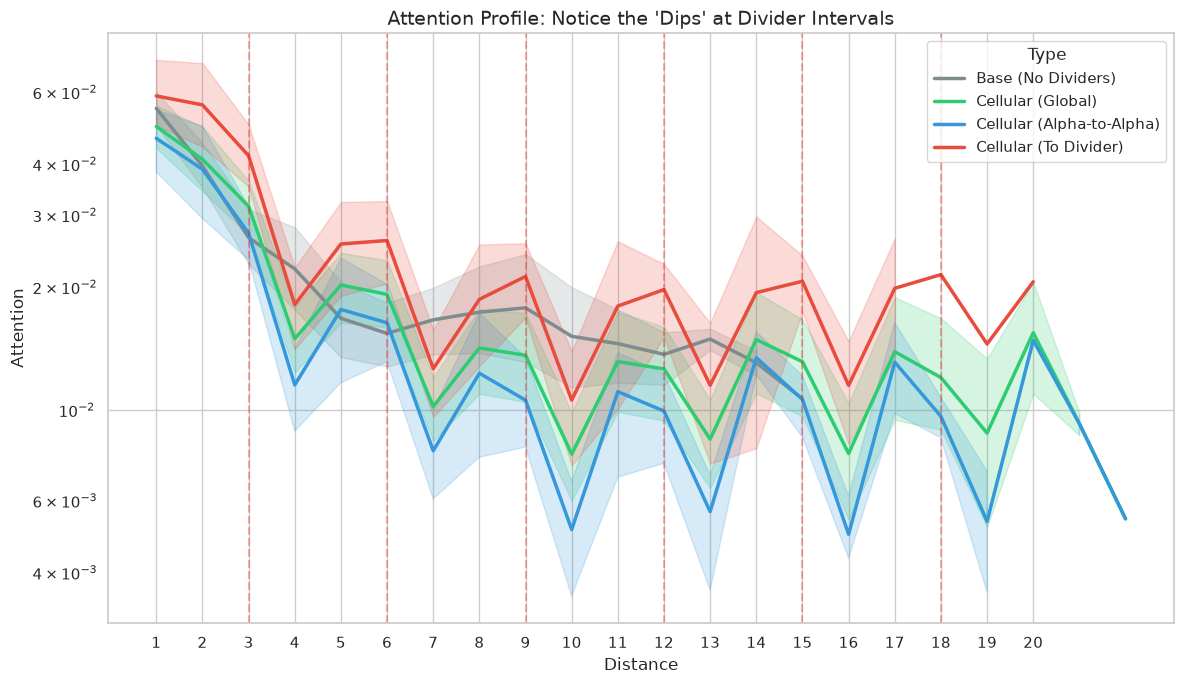

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# ============================================================
# LOAD DATA
# ============================================================
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

# Average across Layers (L) and Heads (H) to get (N, N) matrices
attn_base = data["attn_base"].mean(axis=(0, 1))
attn_cell = data["attn_cell"].mean(axis=(0, 1))

tokens_base = np.array(data["tokens_base"])
tokens_cell = np.array(data["tokens_cell"])

palette = {
    "Base (No Dividers)": "#7f8c8d",      # Grey (Baseline)
    "Cellular (Global)": "#2ecc71",       # Green (Full Cellular model)
    "Cellular (To Divider)": "#e74c3c",   # Red (Attention focused on '|')
    "Cellular (Alpha-to-Alpha)": "#3498db" # Blue (Letter-to-letter context)
}

# ============================================================
# DATA EXTRACTION
# ============================================================
results = []

# 1. PROCESS BASE MODEL (Pure Alphabet)
N_base = attn_base.shape[0]
for i in range(1, N_base):
    for j in range(i):
        results.append({
            "Distance": i - j,
            "Attention": attn_base[i, j],
            "Type": "Base (No Dividers)"
        })

# 2. PROCESS CELLULAR MODEL (Mixed)
N_cell = attn_cell.shape[0]
div_idx = np.where(tokens_cell == "|")[0]
alpha_idx = np.where(tokens_cell != "|")[0]

for i in range(1, N_cell):
    for j in range(i):
        dist = i - j
        val = attn_cell[i, j]
        
        # Cellular (All)
        results.append({"Distance": dist, "Attention": val, "Type": "Cellular (Global)"})
        
        # Cellular (To Divider)
        if j in div_idx:
            results.append({"Distance": dist, "Attention": val, "Type": "Cellular (To Divider)"})
            
        # Cellular (Alpha -> Alpha)
        if i in alpha_idx and j in alpha_idx:
            results.append({"Distance": dist, "Attention": val, "Type": "Cellular (Alpha-to-Alpha)"})

df = pd.DataFrame(results)

# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(12, 7))

# Plot the lines
sns.lineplot(data=df, x="Distance", y="Attention", hue="Type", palette=palette, linewidth=2.5)

# ADD VERTICAL LINES every 5 tokens (divider positions)
for d in range(3, 21, 3):
    plt.axvline(x=d, color='red', linestyle='--', alpha=0.3, label='Divider Gap' if d==5 else "")

plt.title("Attention Profile: Notice the 'Dips' at Divider Intervals", fontsize=14)
#plt.xlim(1, 20)
plt.yscale('log')
plt.xticks(range(1, 21))

# Add a note about the missing distances
plt.annotate('Alpha-to-Alpha dips\nbecause a Divider is at this distance', 
             xy=(5, 0), xytext=(6, 0.02),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))
plt.tight_layout()
plt.savefig('attention_distance_profile.png',dpi=300)
plt.show()

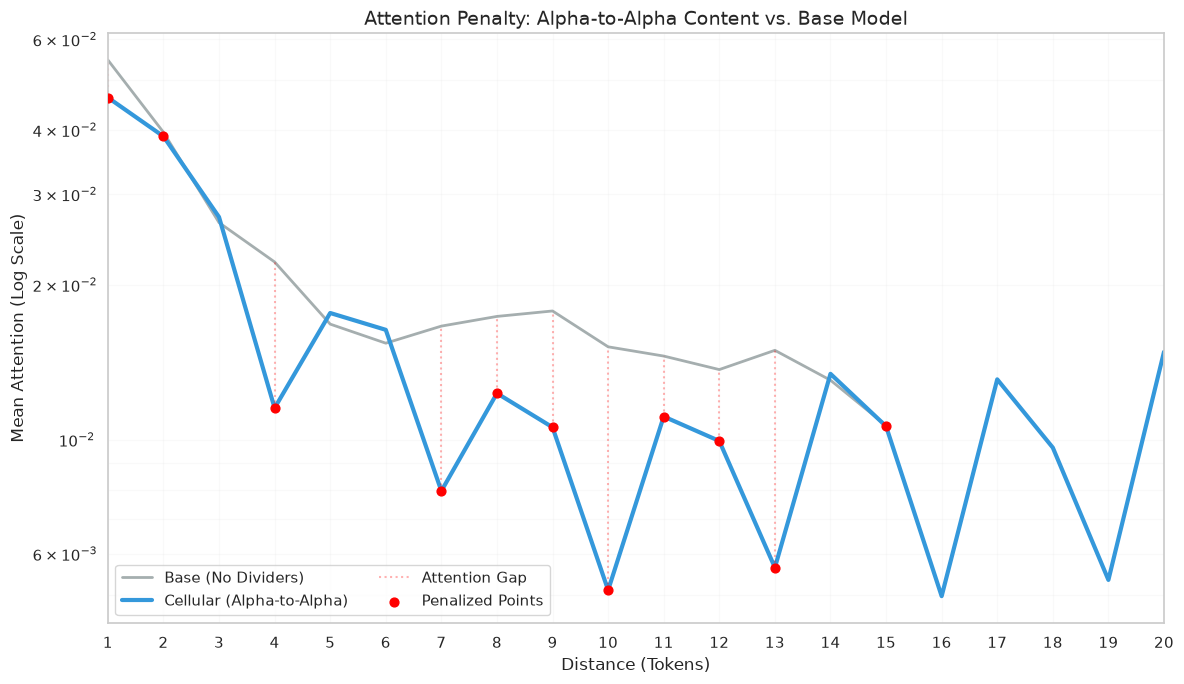

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# ============================================================
# LOAD DATA
# ============================================================
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

# Average across Layers and Heads
attn_base = data["attn_base"].mean(axis=(0, 1))
attn_cell = data["attn_cell"].mean(axis=(0, 1))

tokens_base = np.array(data["tokens_base"])
tokens_cell = np.array(data["tokens_cell"])

# ============================================================
# DATA EXTRACTION
# ============================================================
results = []

# 1. Base Model processing
N_base = attn_base.shape[0]
for i in range(1, N_base):
    for j in range(i):
        results.append({
            "Distance": i - j,
            "Attention": attn_base[i, j],
            "Type": "Base (No Dividers)"
        })

# 2. Cellular Alpha-to-Alpha processing
N_cell = attn_cell.shape[0]
alpha_idx = np.where(tokens_cell != "|")[0]

for i in range(1, N_cell):
    for j in range(i):
        if i in alpha_idx and j in alpha_idx:
            results.append({
                "Distance": i - j,
                "Attention": attn_cell[i, j],
                "Type": "Cellular (Alpha-to-Alpha)"
            })

df = pd.DataFrame(results)
summary = df.groupby(['Distance', 'Type'])['Attention'].mean().unstack()

# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(12, 7))

# Plot lines
plt.plot(summary.index, summary["Base (No Dividers)"], 
         label="Base (No Dividers)", color="#7f8c8d", linewidth=2, alpha=0.7)
plt.plot(summary.index, summary["Cellular (Alpha-to-Alpha)"], 
         label="Cellular (Alpha-to-Alpha)", color="#3498db", linewidth=3)

# Find where Cellular < Base
penalty_mask = summary["Cellular (Alpha-to-Alpha)"] < summary["Base (No Dividers)"]
penalty_dists = summary.index[penalty_mask]
penalty_vals = summary["Cellular (Alpha-to-Alpha)"][penalty_mask]

# 1. Highlight the gap with vertical error bars (stems)
plt.vlines(penalty_dists, penalty_vals, summary["Base (No Dividers)"][penalty_mask], 
           color='red', alpha=0.3, linestyles=':', label='Attention Gap')

# 2. Add singular red dots on points where attention is lower
plt.scatter(penalty_dists, penalty_vals, color='red', s=40, zorder=5, label='Penalized Points')

plt.yscale('log')
plt.title("Attention Penalty: Alpha-to-Alpha Content vs. Base Model", fontsize=14)
plt.xlabel("Distance (Tokens)", fontsize=12)
plt.ylabel("Mean Attention (Log Scale)", fontsize=12)
plt.xlim(1, 20)
plt.xticks(range(1, 21))
plt.grid(True, which="both", ls="-", alpha=0.1)
plt.legend(frameon=True, loc='lower left', ncol=2)

plt.tight_layout()
plt.show()

# Model-Scale Comparison

Found results for 3 model scale(s): ['Mistral-7B-Instruct-v0.3', 'Qwen2.5-14B-Instruct', 'Qwen2.5-7B-Instruct']

--- MODEL-SCALE COMPARISON ---
                   Model  Params_B  SAR_Base  SAR_Cellular_Bounds  Alpha_Base  Alpha_Cellular  Alpha_Reduction_%  Mean_Boundary_Attn  Mean_Delta_Entropy  Mean_Delta_Clustering
Mistral-7B-Instruct-v0.3       7.0    0.0214               0.0083      1.3984          1.3866             0.8371              0.0836              0.0965                 0.0034
     Qwen2.5-7B-Instruct       7.0    0.0429               0.0639      1.3053          1.0611            18.7102              0.1048              0.1216                 0.0007
    Qwen2.5-14B-Instruct      14.0    0.0619               0.1148      1.4399          1.1836            17.8030                 NaN                 NaN                    NaN



Saved plot to results/model_scale_comparison.png


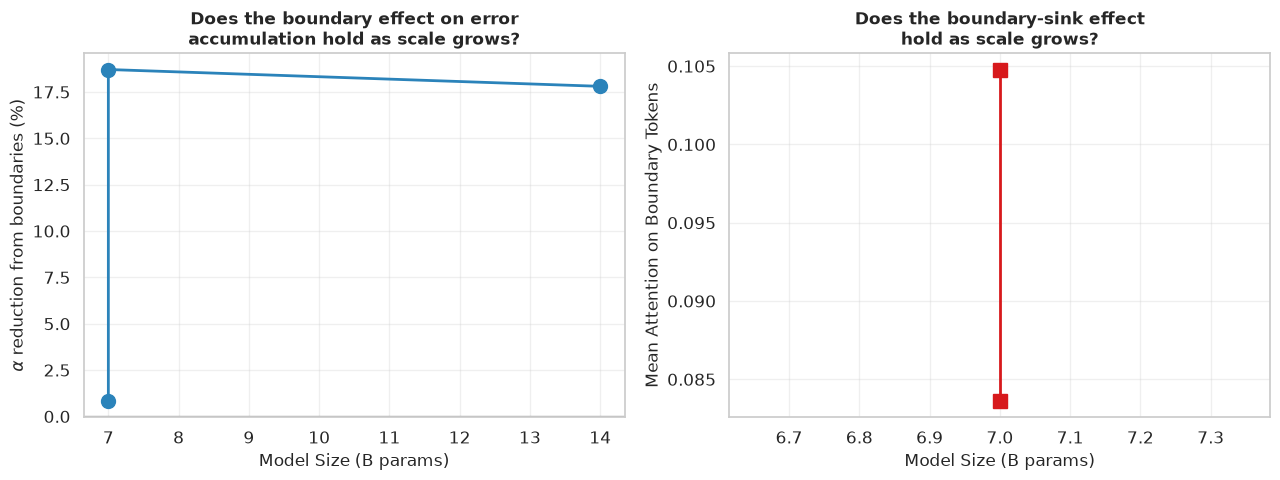

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

# ============================================================
# MODEL-SCALE COMPARISON
# ============================================================
# Change MODEL_ID in the MODEL SELECTION cell near the top of this notebook
# and re-run top to bottom to populate results for another scale (e.g.
# Qwen2.5-14B-Instruct). This cell auto-discovers every results/<MODEL_TAG>/
# directory that has been run so far and compares them side by side --
# nothing to configure here, just re-run this cell after each new scale.

available_tags = sorted(
    d for d in os.listdir("results") if os.path.isdir(os.path.join("results", d))
) if os.path.isdir("results") else []

print(f"Found results for {len(available_tags)} model scale(s): {available_tags}")
if len(available_tags) < 2:
    print("\nOnly one model scale has been run so far -- nothing to compare yet.")
    print("Change MODEL_ID in the MODEL SELECTION cell near the top, re-run the")
    print("notebook top to bottom for that scale, then re-run this cell.")

def parse_param_count(tag):
    # e.g. "Qwen2.5-7B-Instruct" -> 7.0, "Qwen2.5-14B-Instruct" -> 14.0
    m = re.search(r'(\d+(?:\.\d+)?)B', tag)
    return float(m.group(1)) if m else float('nan')

rows = []
for tag in available_tags:
    d = os.path.join("results", tag)
    entry = {"Model": tag, "Params_B": parse_param_count(tag)}

    thermo_path = os.path.join(d, "thermodynamics_grid.csv")
    if os.path.exists(thermo_path):
        df = pd.read_csv(thermo_path)
        for method, sub in df.groupby("Method"):
            entry[f"SAR_{method}"] = sub["SAR"].mean()

    sk_path = os.path.join(d, "thermodynamics_sk_fit.csv")
    if os.path.exists(sk_path):
        sk = pd.read_csv(sk_path)
        base_alpha = sk[sk["Method"] == "Base"]["Alpha"].mean()
        cell_alpha = sk[sk["Method"] == "Cellular_Bounds"]["Alpha"].mean()
        entry["Alpha_Base"] = base_alpha
        entry["Alpha_Cellular"] = cell_alpha
        entry["Alpha_Reduction_%"] = 100 * (base_alpha - cell_alpha) / base_alpha if base_alpha else float("nan")

    attn_path = os.path.join(d, "attention_metrics.csv")
    if os.path.exists(attn_path):
        attn = pd.read_csv(attn_path)
        entry["Mean_Boundary_Attn"] = attn["Cell_Boundary_Attn"].mean()
        entry["Mean_Delta_Entropy"] = attn["Delta_Entropy"].mean()
        if "Delta_Clustering" in attn.columns:
            entry["Mean_Delta_Clustering"] = attn["Delta_Clustering"].mean()

    rows.append(entry)

comparison_df = pd.DataFrame(rows).sort_values("Params_B")
print("\n--- MODEL-SCALE COMPARISON ---")
print(comparison_df.round(4).to_string(index=False))

if len(comparison_df) >= 2:
    comparison_df.to_csv(os.path.join("results", "model_scale_comparison.csv"), index=False)

    sns.set_theme(style="whitegrid", font_scale=1.1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    if "Alpha_Reduction_%" in comparison_df.columns:
        axes[0].plot(comparison_df["Params_B"], comparison_df["Alpha_Reduction_%"],
                     marker='o', markersize=10, linewidth=2, color='#2b83ba')
        axes[0].axhline(0.0, color='black', linestyle='-', alpha=0.3, linewidth=1)
        axes[0].set_xlabel("Model Size (B params)", fontsize=12)
        axes[0].set_ylabel(r"$\alpha$ reduction from boundaries (%)", fontsize=12)
        axes[0].set_title("Does the boundary effect on error\naccumulation hold as scale grows?",
                           fontsize=12, fontweight='bold')
        axes[0].grid(True, alpha=0.3)

    if "Mean_Boundary_Attn" in comparison_df.columns:
        axes[1].plot(comparison_df["Params_B"], comparison_df["Mean_Boundary_Attn"],
                     marker='s', markersize=10, linewidth=2, color='#d7191c')
        axes[1].set_xlabel("Model Size (B params)", fontsize=12)
        axes[1].set_ylabel("Mean Attention on Boundary Tokens", fontsize=12)
        axes[1].set_title("Does the boundary-sink effect\nhold as scale grows?",
                           fontsize=12, fontweight='bold')
        axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plot_path = os.path.join("results", "model_scale_comparison.png")
    plt.savefig(plot_path, dpi=300, bbox_inches='tight')
    print(f"\nSaved plot to {plot_path}")
    plt.show()